# Ames Housing Price Prediction — Team Notebook

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 80 columns) · **Target:** `SalePrice` · **Global random state:** `42`


> **Handoff from Part 1 to Part 2:** `df`, `cols_num`, `cols_nominal`, `cols_ordinal`, `ordinal_orders` (defined at the end of Section 1, re-checked at the very end of this part).

In [1]:
# ---- Imports & global settings ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif      # ANOVA F-test (used for significance tests)
from sklearn.preprocessing import PowerTransformer   # Yeo-Johnson transformation

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 100
PALETTE = "viridis"

---
# Section 1 — Dataset Understanding

### 1.1 Loading the data

The file is read in the ordinary way with `pd.read_csv`. Note that pandas converts the text `NA` to `NaN`. In this dataset, `NA` is used both for *"the house does not have this feature"* (e.g. no basement, no garage, no pool) and for *"value not recorded"*, so missing values are analysed carefully in Section 1.3.

In [2]:
df = pd.read_csv('train.csv')            # ordinary read
print("Loaded:", df.shape)
df.head()

Loaded: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.2 Target variable and shape

The target is **`SalePrice`** (sale price in USD) — a continuous variable, so this is a **regression** problem.

In [3]:
print(f"Shape            : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target           : SalePrice  (dtype={df['SalePrice'].dtype})")
print(f"Duplicated rows  : {df.duplicated().sum()}")
print(f"Duplicates (ignoring Id): {df.drop(columns='Id').duplicated().sum()}")
print("\nData types:")
display(df.dtypes.astype(str).value_counts().rename("number of columns").to_frame())

Shape            : 1,460 rows x 81 columns
Target           : SalePrice  (dtype=int64)
Duplicated rows  : 0
Duplicates (ignoring Id): 0

Data types:


,number of columns
object,43
int64,35
float64,3


**Finding.** The dataset has **1,460 rows and 81 columns** (80 features including `Id`, plus `SalePrice`). There are **0 duplicated rows**, even when `Id` is ignored, so no duplicate removal is needed. 38 columns are numeric and 43 are text/categorical.

### 1.3 Missing values: report and treatment

First we report the missing values, then handle them. The rule is to **ask what the missing value means** before choosing a fill value:

| Situation | Treatment | Why |
|---|---|---|
| Categorical `NaN` = feature absent (`PoolQC`, `Fence`, `Alley`, `MiscFeature`, `FireplaceQu`, basement and garage columns) | fill with the category **`"None"`** | It is real information ("no pool"), not an error |
| `MasVnrType` (`NaN`) | fill with **`"None"`** | In this file the category *None* (no veneer) is also read as `NaN`; 864 of the 872 `NaN`s are this case |
| `MasVnrArea` (`NaN`) | fill with **0** | No veneer means an area of 0 sq ft |
| `GarageYrBlt` (`NaN`, 81 houses with no garage) | fill with **`YearBuilt`** | A year of 0 would be absurd and would distort the column; a garage with no date is best approximated by the house's own year |
| `LotFrontage` (259 houses) | **leave as `NaN` here** | Zero is wrong (every lot touches a street), so a statistical fill (median) is needed. It must be learned from the training set only, so it is done **inside the Part 2 pipeline** to avoid data leakage |
| `Electrical` (1 house) | **leave as `NaN` here** | One missing category: filled with the most frequent value in the Part 2 pipeline |

,missing,missing_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Columns with missing values: 19   |   total missing cells: 7,829


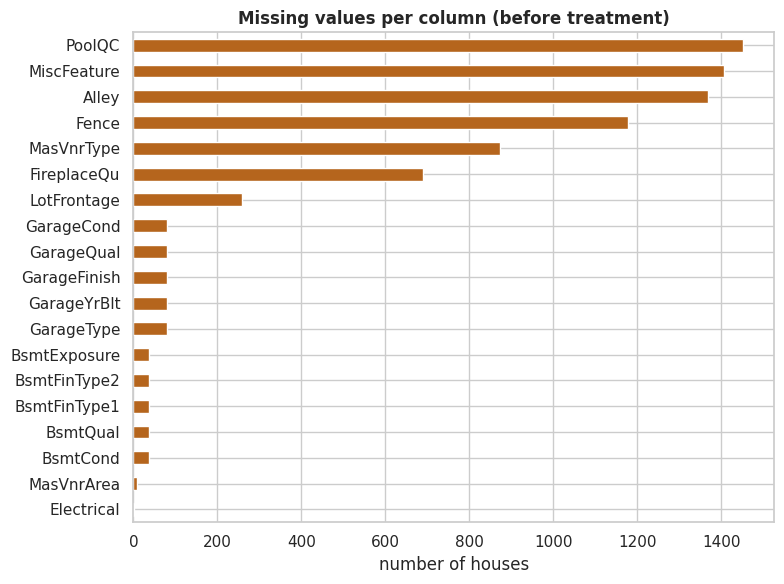


Missing values after treatment (left for the Part 2 pipeline):
LotFrontage    259
Electrical       1


In [4]:
# ---- 1. Report missing values (before any treatment) ----
missing_before = df.isna().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)
report = pd.DataFrame({"missing": missing_before,
                       "missing_%": (missing_before / len(df) * 100).round(2)})
display(report)
print(f"Columns with missing values: {len(report)}   |   total missing cells: {missing_before.sum():,}")

fig, ax = plt.subplots(figsize=(8, 6))
missing_before.sort_values().plot.barh(ax=ax, color="#b5651d")
ax.set_title("Missing values per column (before treatment)"); ax.set_xlabel("number of houses")
plt.tight_layout(); plt.show()

# ---- 2. Treatment ----
CAT_NONE_COLS = ["Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
                 "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual",
                 "GarageCond", "PoolQC", "Fence", "MiscFeature"]
df[CAT_NONE_COLS] = df[CAT_NONE_COLS].fillna("None")            # feature absent -> category "None"
df["MasVnrArea"]  = df["MasVnrArea"].fillna(0)                   # no veneer -> 0 sq ft
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])    # no garage -> use the house's year

# LotFrontage and Electrical stay NaN on purpose: they need statistics learned from the TRAIN set only (Part 2)
missing_after = df.isna().sum()
print("\nMissing values after treatment (left for the Part 2 pipeline):")
print(missing_after[missing_after > 0].to_string())

**Finding.** pandas reports **19 columns with missing values (7,829 cells)**, and `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%) and `Fence` (80.8%) look almost empty. This is misleading: these `NaN`s mostly mean the house **does not have** the feature, so they are filled with the category `"None"` (or 0 for `MasVnrArea`, and `YearBuilt` for `GarageYrBlt`). After this treatment only **2 columns still have missing values**: `LotFrontage` (259 houses, 17.7%) and `Electrical` (1 house). These are the only ones that need statistical imputation, which belongs inside the Part 2 pipeline (fit on the training set only).

### 1.4 Feature classification: numerical / nominal / ordinal

* **Ordinal** — categories with a natural order (quality ratings `Po < Fa < TA < Gd < Ex`, basement exposure, finish levels, `Functional`, ...). The order is written explicitly in `ordinal_orders`, **lowest → highest**, with `"None"` (feature absent) as the lowest level where it applies.
* **Nominal** — categories with no order (`Neighborhood`, `MSZoning`, `Exterior1st`, ...). Two numeric columns are really nominal codes, so we treat them as nominal: `MSSubClass` (dwelling-type code, e.g. 20, 60, 120 — the numbers are labels, not quantities) and `MoSold` (month, which is cyclical, so December is not "bigger" than January in a meaningful way).
* **Numerical** — everything else, including `OverallQual` and `OverallCond` (already integer 1–10 scales, so they behave as ordered numbers and need no encoder) and year columns.

In [5]:
QUAL5 = ["None", "Po", "Fa", "TA", "Gd", "Ex"]          # quality scale used by many columns

ordinal_orders = {
    # Quality / condition scales (lowest -> highest)
    "ExterQual":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "HeatingQC":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual":  ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":     QUAL5,
    "BsmtCond":     QUAL5,
    "FireplaceQu":  QUAL5,
    "GarageQual":   QUAL5,
    "GarageCond":   QUAL5,
    "PoolQC":       QUAL5,
    # Other ordered scales
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "Functional":   ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fence":        ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "PavedDrive":   ["N", "P", "Y"],
    "LotShape":     ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":    ["Sev", "Mod", "Gtl"],
    "Utilities":    ["ELO", "NoSeWa", "NoSewr", "AllPub"],
    "CentralAir":   ["N", "Y"],
    "Street":       ["Grvl", "Pave"],
}

# Sanity check: every category that appears in the data is covered by the declared order
for col, order in ordinal_orders.items():
    unknown = set(df[col].dropna().unique()) - set(order)
    assert not unknown, f"{col}: categories missing from order -> {unknown}"

NUMERIC_BUT_NOMINAL = ["MSSubClass", "MoSold"]
TARGET, ID_COL = "SalePrice", "Id"

cols_ordinal = list(ordinal_orders.keys())
cols_nominal = [c for c in df.columns
                if c not in cols_ordinal + [TARGET, ID_COL]
                and (c in NUMERIC_BUT_NOMINAL or not pd.api.types.is_numeric_dtype(df[c]))]
cols_num     = [c for c in df.columns
                if c not in cols_ordinal + cols_nominal + [TARGET, ID_COL]]

assert len(cols_ordinal) + len(cols_nominal) + len(cols_num) == 79      # 81 columns - Id - SalePrice
assert not (set(cols_ordinal) & set(cols_nominal)) and not (set(cols_num) & set(cols_nominal))

print(f"Numerical : {len(cols_num)}\nNominal   : {len(cols_nominal)}\nOrdinal   : {len(cols_ordinal)}\n")
for name, cols in [("NUMERICAL", cols_num), ("NOMINAL", cols_nominal), ("ORDINAL", cols_ordinal)]:
    print(f"{name} ({len(cols)}):\n  {', '.join(cols)}\n")

Numerical : 34
Nominal   : 23
Ordinal   : 22

NUMERICAL (34):
  LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, YrSold

NOMINAL (23):
  MSSubClass, MSZoning, Alley, LandContour, LotConfig, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, Electrical, GarageType, MiscFeature, MoSold, SaleType, SaleCondition

ORDINAL (22):
  ExterQual, ExterCond, HeatingQC, KitchenQual, BsmtQual, BsmtCond, FireplaceQu, GarageQual, GarageCond, PoolQC, BsmtExposure, BsmtFinType1, BsmtFinType2, GarageFinish, Functional, Fence, PavedDrive, LotShape, LandSlope, Utilities, Cen

**Finding.** The 79 predictors split into **34 numerical**, **23 nominal** and **22 ordinal** features. `Id` is only an identifier and `SalePrice` is the target, so neither is used as a predictor.

### 1.5 Description of the most important variables

| Variable | Type | Meaning |
|---|---|---|
| `SalePrice` | target | Final sale price in USD |
| `OverallQual` | numeric (1–10) | Overall material and finish quality of the house |
| `GrLivArea` | numeric | Above-ground living area (sq ft) |
| `Neighborhood` | nominal (25) | Physical location within Ames city limits |
| `GarageCars` / `GarageArea` | numeric | Garage capacity (cars) / size (sq ft) |
| `TotalBsmtSF` | numeric | Total basement area (sq ft) |
| `YearBuilt` / `YearRemodAdd` | numeric | Construction year / remodel year |
| `ExterQual`, `KitchenQual`, `BsmtQual` | ordinal | Quality of exterior material, kitchen, basement height |
| `FullBath`, `BedroomAbvGr` | numeric | Number of full bathrooms / bedrooms above ground |
| `LotArea` | numeric | Lot size (sq ft) |
| `MoSold`, `YrSold` | nominal / numeric | Month and year of sale |

### Summary — Section 1
The dataset contains **1,460 houses × 81 columns** with no duplicate rows. pandas reports 19 columns with missing values (7,829 cells), but most `NaN`s mean *"the house has no pool/garage/basement"*, so they were filled with `"None"` (categorical), 0 (`MasVnrArea`) or `YearBuilt` (`GarageYrBlt`). Only **`LotFrontage` (259) and `Electrical` (1)** remain missing and are left for the Part 2 pipeline, to be imputed using the training set only. The 79 predictors are classified into **34 numerical, 23 nominal and 22 ordinal** features, with explicit category orders for all ordinal columns.

---
# Section 2 — Exploratory Data Analysis (EDA)

### 2.1 Descriptive statistics

In [6]:
display(df[cols_num + [TARGET]].describe().T)
print("Categorical features (nominal + ordinal): number of unique values and most frequent category")
cat_summary = pd.DataFrame({
    "unique": df[cols_nominal + cols_ordinal].nunique(),
    "top": df[cols_nominal + cols_ordinal].mode().iloc[0],
})
cat_summary["top_share_%"] = [(df[c] == cat_summary.loc[c, "top"]).mean() * 100 for c in cat_summary.index]
display(cat_summary.sort_values("unique", ascending=False).head(12))

,count,mean,std,min,25%,50%,75%,max
LotFrontage,"1,201.00",70.05,24.28,21.00,59.00,69.00,80.00,313.00
LotArea,"1,460.00","10,516.83","9,981.26","1,300.00","7,553.50","9,478.50","11,601.50","215,245.00"
OverallQual,"1,460.00",6.10,1.38,1.00,5.00,6.00,7.00,10.00
OverallCond,"1,460.00",5.58,1.11,1.00,5.00,5.00,6.00,9.00
YearBuilt,"1,460.00","1,971.27",30.20,"1,872.00","1,954.00","1,973.00","2,000.00","2,010.00"
YearRemodAdd,"1,460.00","1,984.87",20.65,"1,950.00","1,967.00","1,994.00","2,004.00","2,010.00"
MasVnrArea,"1,460.00",103.12,180.73,0.00,0.00,0.00,164.25,"1,600.00"
BsmtFinSF1,"1,460.00",443.64,456.10,0.00,0.00,383.50,712.25,"5,644.00"
BsmtFinSF2,"1,460.00",46.55,161.32,0.00,0.00,0.00,0.00,"1,474.00"
BsmtUnfSF,"1,460.00",567.24,441.87,0.00,223.00,477.50,808.00,"2,336.00"


Categorical features (nominal + ordinal): number of unique values and most frequent category


,unique,top,top_share_%
Neighborhood,25,NAmes,15.41
Exterior2nd,16,VinylSd,34.52
Exterior1st,15,VinylSd,35.27
MSSubClass,15,20,36.71
MoSold,12,6,17.33
Condition1,9,Norm,86.30
SaleType,9,WD,86.78
RoofMatl,8,CompShg,98.22
Condition2,8,Norm,98.97
HouseStyle,8,1Story,49.73


**Findings.**
* `SalePrice` ranges from \$34,900 to \$755,000 with mean \$180,921 and median \$163,000: the mean is above the median, the first sign of a right-skewed distribution.
* Many area features have a median far below their maximum (e.g. `LotArea`, `MiscVal`, `PoolArea`), and several columns are mostly zero (`PoolArea`, `3SsnPorch`, `ScreenPorch`, `LowQualFinSF`), meaning the feature exists for only a few houses.
* Several categorical columns are dominated by one category (e.g. `Street`, `Utilities`, `Condition2`, `RoofMatl`), so they carry very little information.

### 2.2 Distribution of `SalePrice`

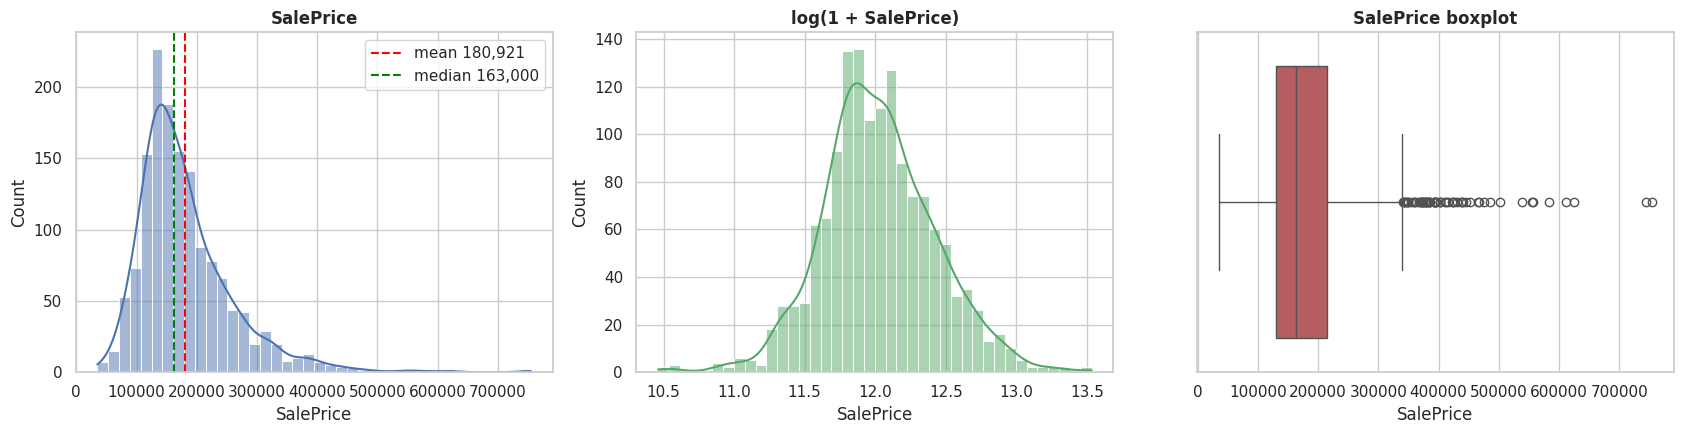

Skewness  raw: 1.883    log1p: 0.121
Kurtosis  raw: 6.536    log1p: 0.810


In [7]:
price = df[TARGET]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(price, kde=True, bins=40, color="#4c72b0", ax=ax[0])
ax[0].axvline(price.mean(), color="red", ls="--", label=f"mean {price.mean():,.0f}")
ax[0].axvline(price.median(), color="green", ls="--", label=f"median {price.median():,.0f}")
ax[0].set_title("SalePrice"); ax[0].legend()

sns.histplot(np.log1p(price), kde=True, bins=40, color="#55a868", ax=ax[1])
ax[1].set_title("log(1 + SalePrice)")

sns.boxplot(x=price, color="#c44e52", ax=ax[2]); ax[2].set_title("SalePrice boxplot")
plt.tight_layout(); plt.show()

print(f"Skewness  raw: {price.skew():.3f}    log1p: {np.log1p(price).skew():.3f}")
print(f"Kurtosis  raw: {price.kurt():.3f}    log1p: {np.log1p(price).kurt():.3f}")

**Finding.** `SalePrice` is clearly **right-skewed (skewness 1.88, kurtosis 6.54)**: most houses sell between roughly \$130k and \$214k (the middle 50%), while a long tail of expensive houses reaches \$755k. After a `log1p` transformation the skewness drops to **0.12**, giving an almost symmetric, bell-shaped distribution. **Decision for Part 2:** train the models on `log1p(SalePrice)` and convert predictions back with `expm1`. This also makes errors relative (a \$20k miss matters more on a \$100k house than on a \$500k house).

### 2.3 Distribution of important numerical features

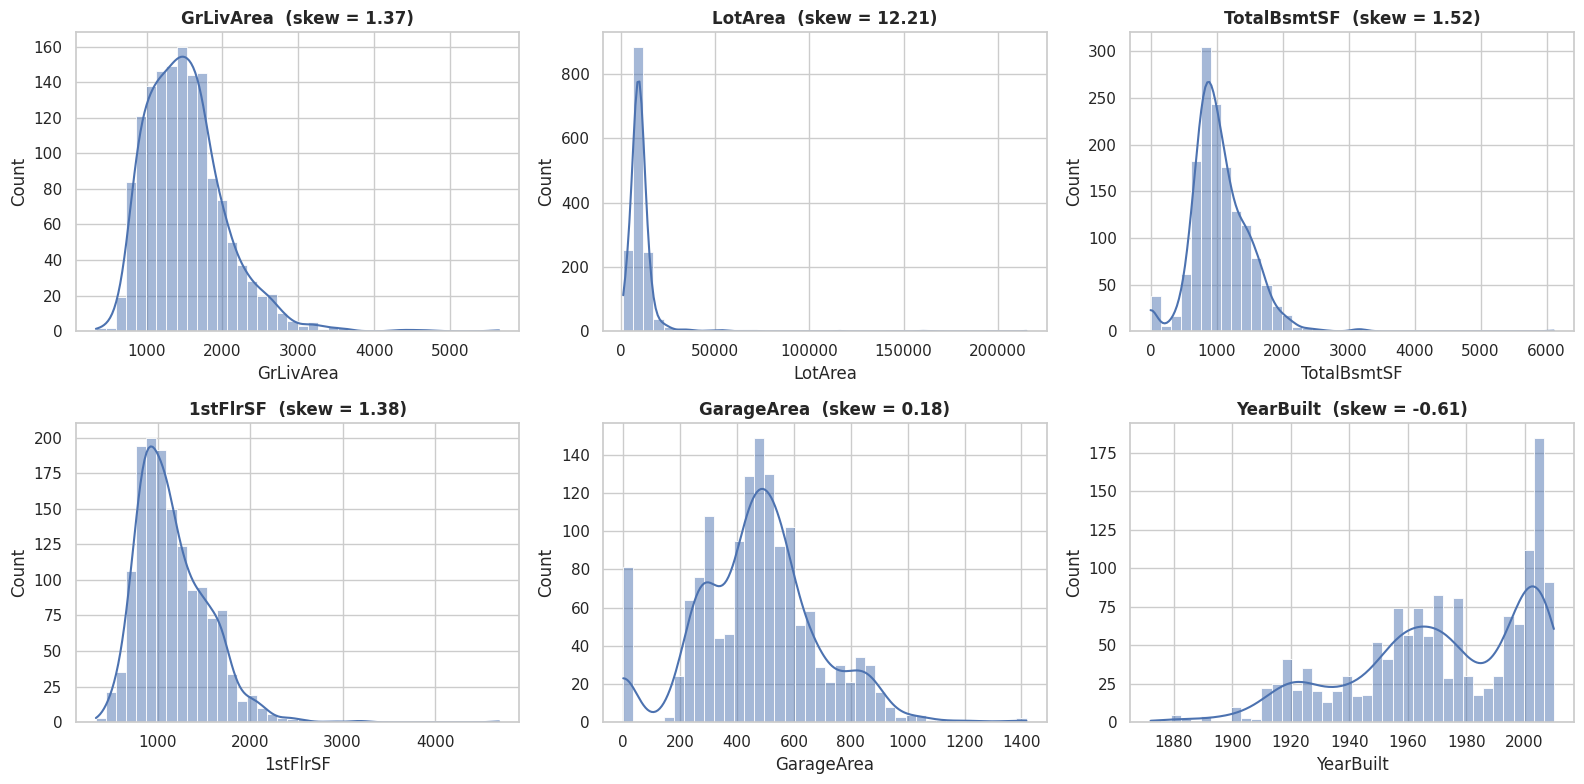

Most skewed numerical features (|skew| > 1 are strongly skewed):


,skewness
MiscVal,24.48
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01
KitchenAbvGr,4.49
BsmtFinSF2,4.26
ScreenPorch,4.12
BsmtHalfBath,4.10
EnclosedPorch,3.09


Numerical features with |skew| > 1: 18 of 34


In [8]:
key_num = ["GrLivArea", "LotArea", "TotalBsmtSF", "1stFlrSF", "GarageArea", "YearBuilt"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_num):
    sns.histplot(df[col], kde=True, bins=40, ax=ax, color="#4c72b0")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
plt.tight_layout(); plt.show()

skew_table = df[cols_num].skew().sort_values(ascending=False)
print("Most skewed numerical features (|skew| > 1 are strongly skewed):")
display(skew_table.head(12).to_frame("skewness"))
print(f"Numerical features with |skew| > 1: {(skew_table.abs() > 1).sum()} of {len(cols_num)}")

#### Yeo-Johnson transformation of skewed features
Yeo-Johnson (`PowerTransformer`) is a power transform that, unlike Box-Cox, works with **zeros and negative values**. This matters here because many columns contain zeros (no porch, no pool, no basement). Below we check how well it reduces skewness (for display only; in Part 2 it must be fitted **inside the pipeline on the training set**).

,skew_before,skew_after_yeo_johnson,lambda
MiscVal,24.48,5.02,-4.28
PoolArea,14.83,14.35,-32.86
LotArea,12.21,0.03,0.03
3SsnPorch,10.30,7.61,-11.67
LowQualFinSF,9.01,7.30,-10.02
KitchenAbvGr,4.49,-2.80,-1.86
BsmtFinSF2,4.26,2.43,-1.52
ScreenPorch,4.12,3.11,-2.43
BsmtHalfBath,4.10,3.86,-25.33
EnclosedPorch,3.09,2.05,-1.42


Skewed features: 18 | skewness reduced for 18 | |skew| < 1 after Yeo-Johnson: 9
SalePrice skewness  raw: 1.883 | log1p: 0.121 | Yeo-Johnson: -0.009


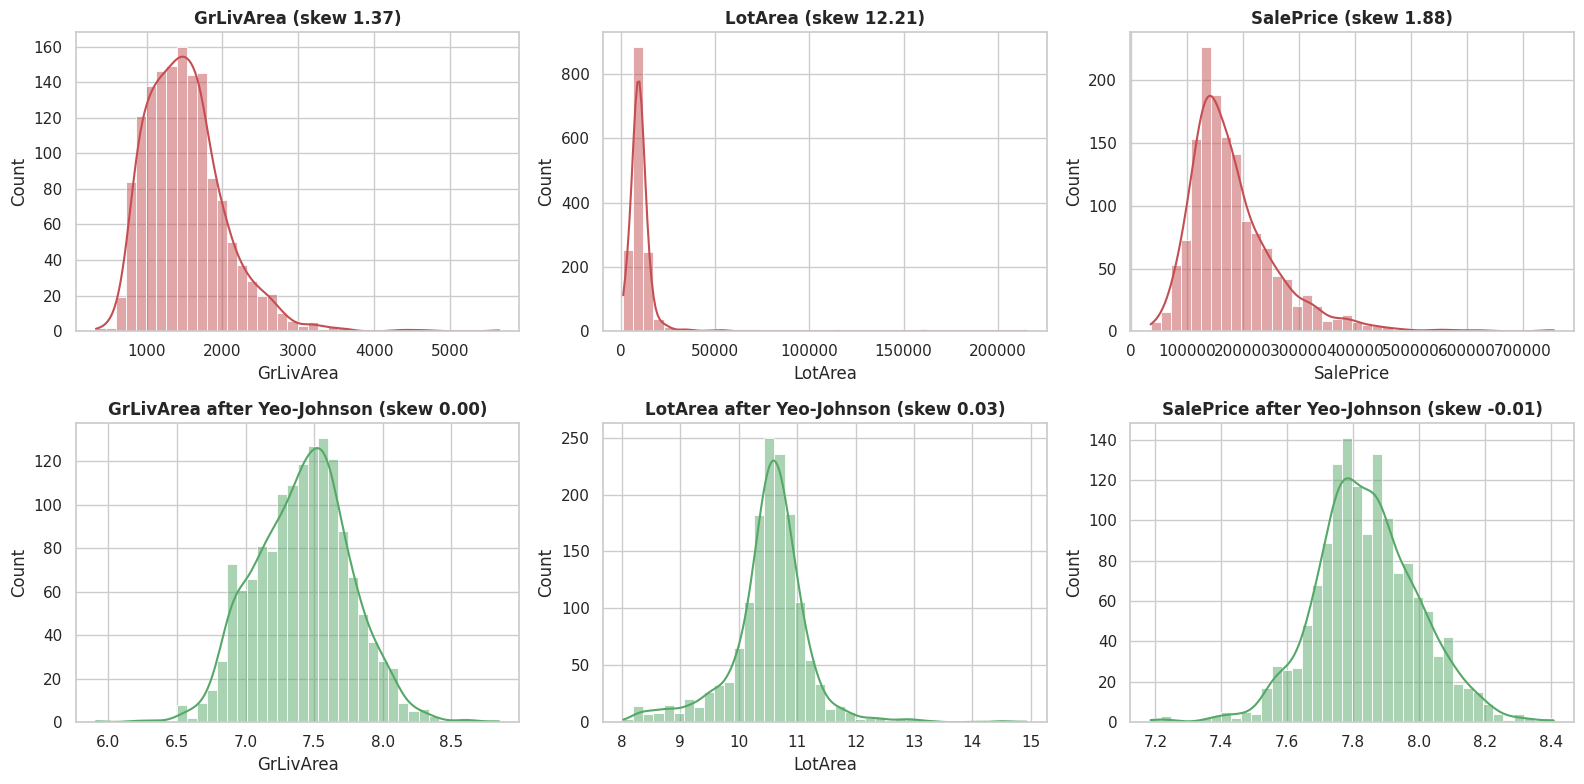

In [9]:
skewed_cols = skew_table[skew_table.abs() > 1].index.tolist()

yj = PowerTransformer(method="yeo-johnson", standardize=False)
yj_vals = pd.DataFrame(yj.fit_transform(df[skewed_cols]), columns=skewed_cols)

yj_table = pd.DataFrame({"skew_before": df[skewed_cols].skew(),
                         "skew_after_yeo_johnson": yj_vals.skew(),
                         "lambda": yj.lambdas_}).sort_values("skew_before", ascending=False)
display(yj_table.round(2))
improved = (yj_table["skew_after_yeo_johnson"].abs() < yj_table["skew_before"].abs()).sum()
print(f"Skewed features: {len(skewed_cols)} | skewness reduced for {improved} | |skew| < 1 after Yeo-Johnson: {(yj_table['skew_after_yeo_johnson'].abs() < 1).sum()}")

# The target too: Yeo-Johnson vs log1p
yj_target = PowerTransformer(method="yeo-johnson", standardize=False)
price_yj = yj_target.fit_transform(df[[TARGET]]).ravel()
print(f"SalePrice skewness  raw: {df[TARGET].skew():.3f} | log1p: {np.log1p(df[TARGET]).skew():.3f} | Yeo-Johnson: {pd.Series(price_yj).skew():.3f}")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(["GrLivArea", "LotArea"]):
    sns.histplot(df[col], kde=True, bins=40, ax=axes[0, j], color="#c44e52"); axes[0, j].set_title(f"{col} (skew {df[col].skew():.2f})")
    sns.histplot(yj_vals[col], kde=True, bins=40, ax=axes[1, j], color="#55a868"); axes[1, j].set_title(f"{col} after Yeo-Johnson (skew {yj_vals[col].skew():.2f})")
sns.histplot(df[TARGET], kde=True, bins=40, ax=axes[0, 2], color="#c44e52"); axes[0, 2].set_title(f"SalePrice (skew {df[TARGET].skew():.2f})")
sns.histplot(price_yj, kde=True, bins=40, ax=axes[1, 2], color="#55a868"); axes[1, 2].set_title(f"SalePrice after Yeo-Johnson (skew {pd.Series(price_yj).skew():.2f})")
plt.tight_layout(); plt.show()

**Findings.** `GrLivArea`, `TotalBsmtSF`, `1stFlrSF` and `LotArea` are right-skewed, with `LotArea` the most extreme of the main features (skew 12.2, a few huge lots over 100,000 sq ft). `YearBuilt` is left-skewed (most houses were built after 1950), and `GarageArea` is roughly symmetric with a spike at 0 (no garage). Overall, **18 of the 34 numerical columns are strongly skewed (|skew| > 1)**, so **Part 2 should apply a log/Yeo-Johnson-style transformation** to the skewed numeric features before scaling.


**Yeo-Johnson result.** Of the 18 strongly skewed features, Yeo-Johnson reduced the skewness of **all 18** and brought **9 of them below |skew| = 1**. The gains are dramatic for continuous features: `LotArea` 12.21 → 0.03, `LotFrontage` 2.16 → 0.12, `GrLivArea` 1.37 → 0.00, `1stFlrSF` 1.38 → 0.00, `OpenPorchSF` 2.36 → −0.01, `MasVnrArea` 2.68 → 0.43. It cannot fix features that are **almost always zero** (`PoolArea` 14.83 → 14.35, `3SsnPorch` 10.30 → 7.61, `LowQualFinSF` 9.01 → 7.30, `BsmtHalfBath` 4.10 → 3.86), because a spike of identical zero values cannot be spread out by any power transform. Those features carry little information, and tree-based models are not affected by skew anyway. For the target, Yeo-Johnson brings `SalePrice` to skew −0.01, essentially the same as `log1p` (0.12). **Decision for Part 2:** use Yeo-Johnson inside the numerical pipeline (it handles the zeros that are common here, unlike Box-Cox), fitted on the training set only.

### 2.4 Analysis of categorical features

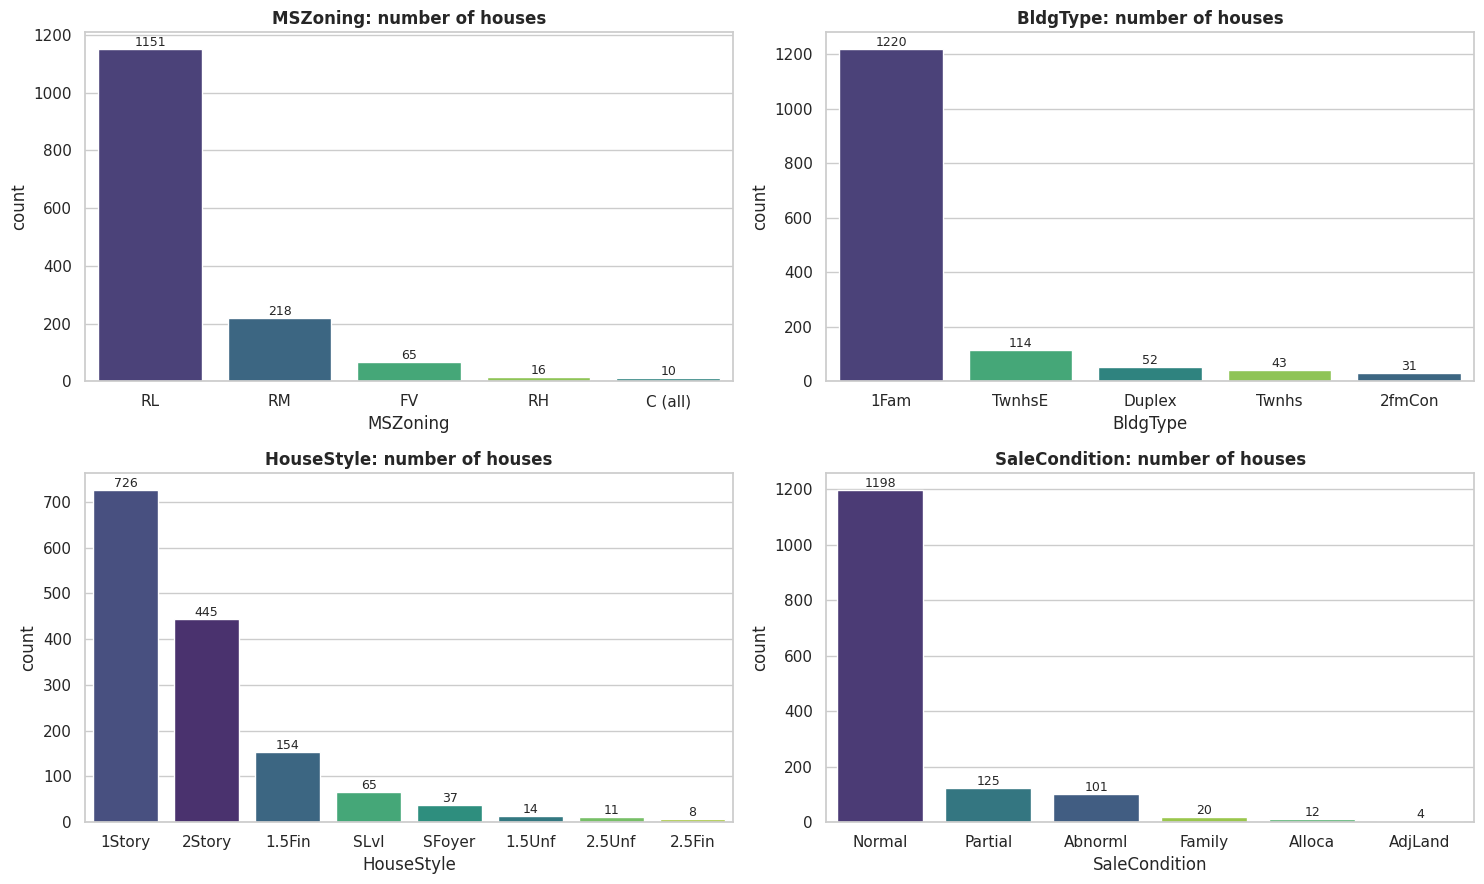

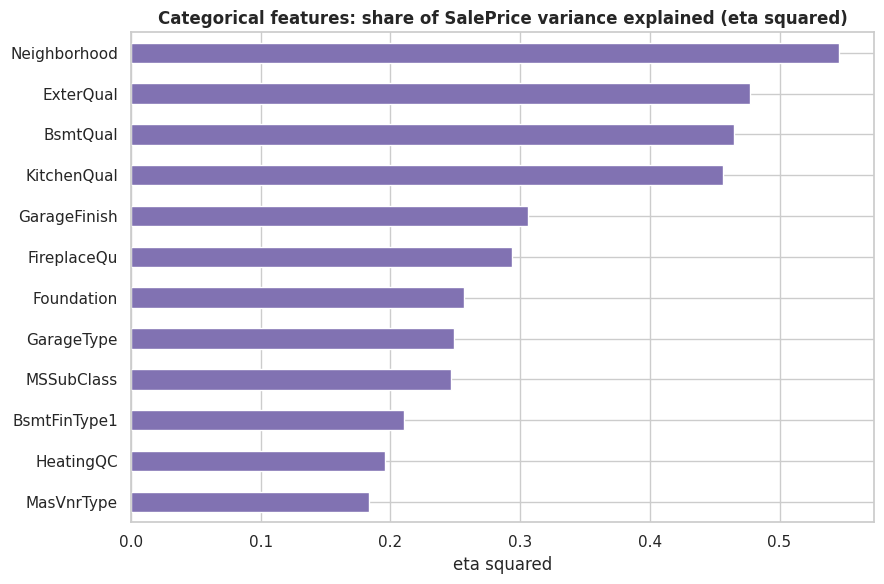

,eta_squared
Neighborhood,0.55
ExterQual,0.48
BsmtQual,0.47
KitchenQual,0.46
GarageFinish,0.31
FireplaceQu,0.29
Foundation,0.26
GarageType,0.25


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), ["MSZoning", "BldgType", "HouseStyle", "SaleCondition"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette=PALETTE, hue=col, legend=False)
    ax.set_title(f"{col}: number of houses")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

# How much of the SalePrice variance does each categorical feature explain? (eta squared)
def eta_squared(frame, cat, target=TARGET):
    grand = frame[target].mean()
    ss_between = frame.groupby(cat)[target].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    ss_total = ((frame[target] - grand) ** 2).sum()
    return ss_between / ss_total

eta = pd.Series({c: eta_squared(df.dropna(subset=[c]), c) for c in cols_nominal + cols_ordinal}).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
eta.head(12).sort_values().plot.barh(color="#8172b2")
plt.title("Categorical features: share of SalePrice variance explained (eta squared)")
plt.xlabel("eta squared"); plt.tight_layout(); plt.show()
display(eta.head(8).round(3).to_frame("eta_squared"))

**Findings.**
* Most houses are in **`RL` (low-density residential) zoning**, are **single-family (`1Fam`)** and are **`Normal`** sales, so the data is dominated by typical homes.
* Eta squared shows how much of the price variance a categorical feature explains. The strongest is `Neighborhood` (0.55), followed by the quality ratings `ExterQual` (0.48), `BsmtQual` (0.47) and `KitchenQual` (0.46), meaning **quality and location are the categorical drivers of price**, while features like `Street` or `Utilities` explain almost nothing.

### 2.5 Outliers

,IQR outliers,% of houses
SalePrice,61,4.18
GrLivArea,31,2.12
LotArea,69,4.73
TotalBsmtSF,61,4.18
GarageArea,21,1.44
1stFlrSF,20,1.37


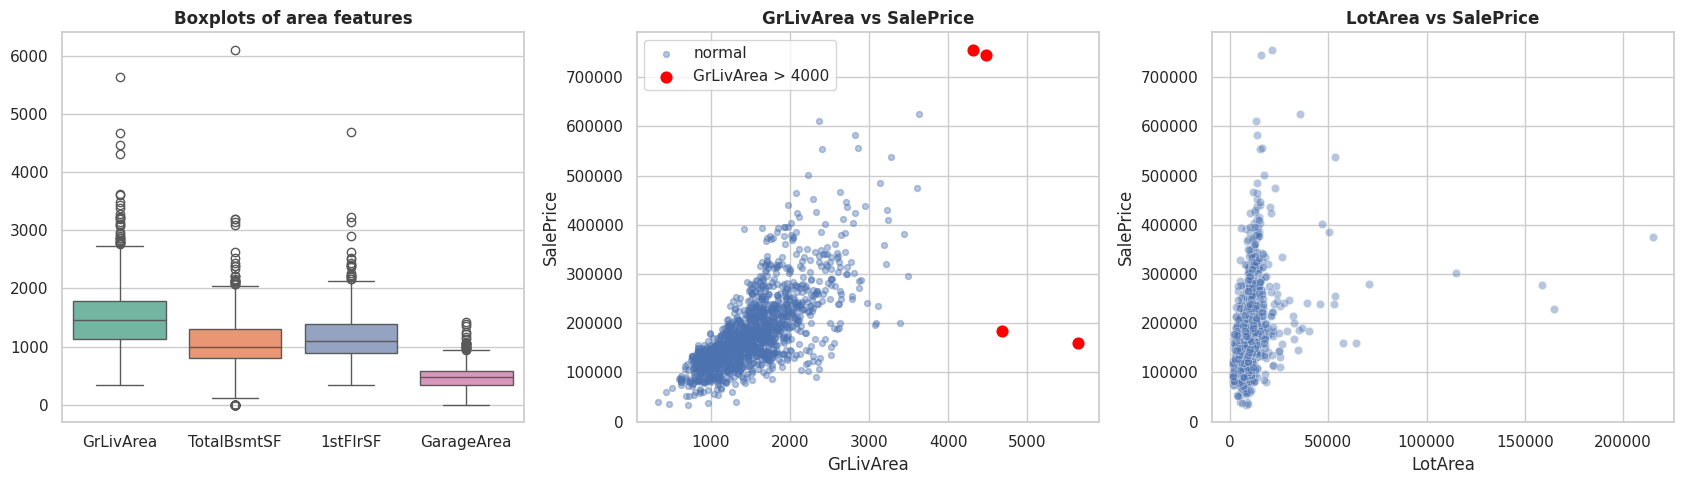

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
691,692,4316,755000,10,NoRidge,Normal
1182,1183,4476,745000,10,NoRidge,Abnorml
1298,1299,5642,160000,10,Edwards,Partial


Correlation GrLivArea-SalePrice  all houses: 0.709 | without the 4 houses > 4000 sq ft: 0.721


In [11]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out_cols = ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea", "1stFlrSF"]
display(pd.DataFrame({"IQR outliers": [iqr_outliers(df[c]) for c in out_cols],
                      "% of houses": [iqr_outliers(df[c]) / len(df) * 100 for c in out_cols]}, index=out_cols))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=df[["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea"]], ax=ax[0], palette="Set2")
ax[0].set_title("Boxplots of area features")

big = df["GrLivArea"] > 4000
ax[1].scatter(df.loc[~big, "GrLivArea"], df.loc[~big, TARGET], alpha=0.4, s=18, label="normal")
ax[1].scatter(df.loc[big, "GrLivArea"], df.loc[big, TARGET], color="red", s=60, label="GrLivArea > 4000")
ax[1].set_xlabel("GrLivArea"); ax[1].set_ylabel("SalePrice"); ax[1].legend(); ax[1].set_title("GrLivArea vs SalePrice")

sns.scatterplot(data=df, x="LotArea", y=TARGET, alpha=0.4, ax=ax[2]); ax[2].set_title("LotArea vs SalePrice")
plt.tight_layout(); plt.show()

display(df.loc[big, ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]])
print("Correlation GrLivArea-SalePrice  all houses:", round(df["GrLivArea"].corr(df[TARGET]), 3),
      "| without the 4 houses > 4000 sq ft:", round(df.loc[~big, "GrLivArea"].corr(df.loc[~big, TARGET]), 3))

**Findings.**
* By the IQR rule, 61 houses (4.2%) are price outliers (above \$340,038) and 31 have an unusually large `GrLivArea`. These are mostly **genuine luxury homes**, not errors.
* **Four houses have `GrLivArea` above 4,000 sq ft.** Two of them (`Id` 692 and 1183) are consistent with the trend: huge, top-quality houses sold for \$755,000 and \$745,000. The other two (**`Id` 524 and 1299**, with 4,676 and 5,642 sq ft) sold for only \$184,750 and \$160,000. Both were `Partial` sales (house not completed when assessed) in `Edwards`, so their prices do not reflect their size or their quality rating of 10. They are **true anomalies** that would pull a linear model's line down.
* Removing these four houses raises the correlation between `GrLivArea` and price from 0.709 to 0.721.
* **Recommendation for Part 2 (decision is theirs, to be justified in markdown):** remove at least `Id` 524 and 1299 from the **training** data (the well-known Ames outliers). Keep the genuine expensive houses, since they are real market behaviour.

### 2.6 Correlation analysis

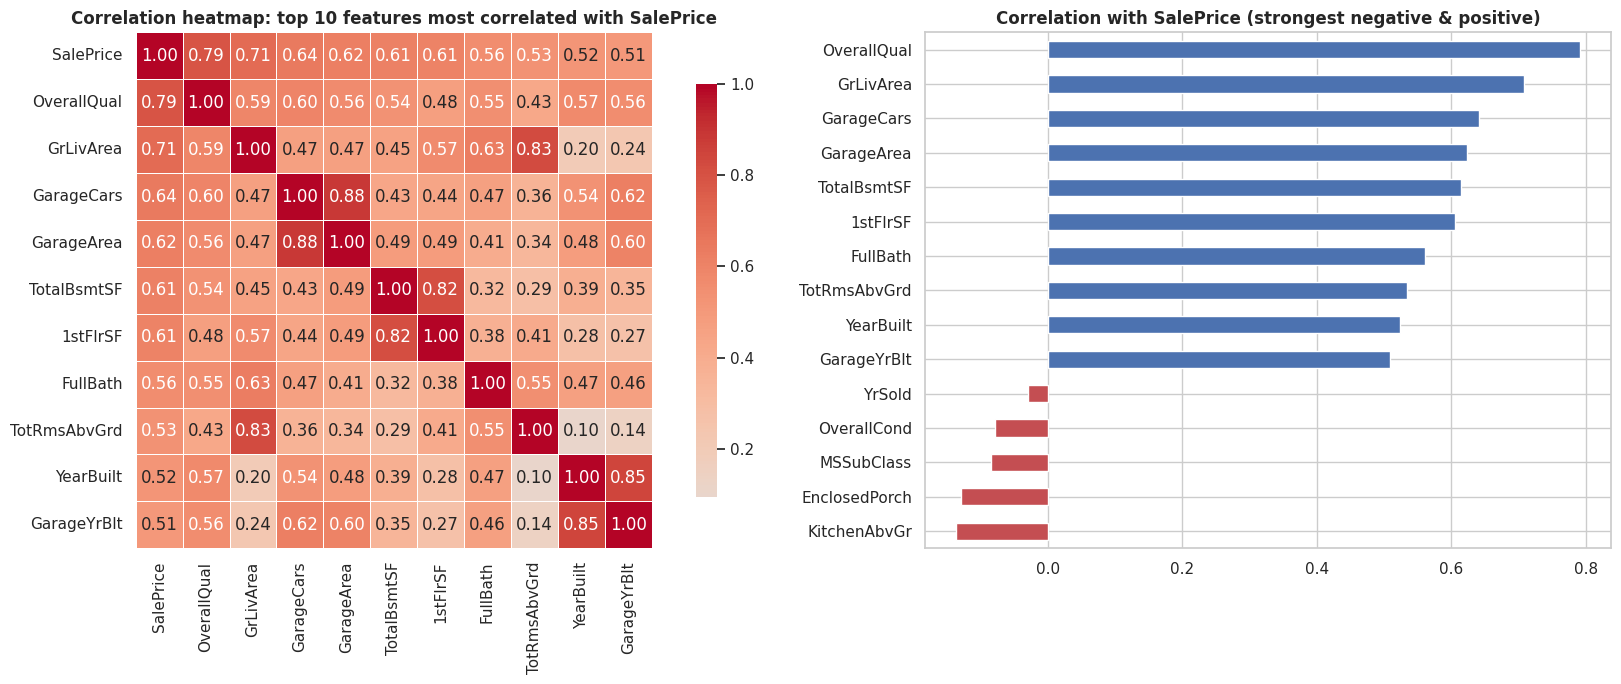

Highly correlated predictor pairs (|r| > 0.8):


,,correlation
GarageCars,GarageArea,0.88
YearBuilt,GarageYrBlt,0.84
GrLivArea,TotRmsAbvGrd,0.82
TotalBsmtSF,1stFlrSF,0.82


In [12]:
num_all = df.select_dtypes("number").drop(columns=["Id"])
corr = num_all.corr()
top_feats = corr[TARGET].abs().sort_values(ascending=False).head(11).index

fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr.loc[top_feats, top_feats], annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax[0])
ax[0].set_title("Correlation heatmap: top 10 features most correlated with SalePrice")

pos = corr[TARGET].drop(TARGET).sort_values()
sel = pd.concat([pos.head(5), pos.tail(10)])
sel.plot.barh(color=["#c44e52" if v < 0 else "#4c72b0" for v in sel], ax=ax[1])
ax[1].set_title("Correlation with SalePrice (strongest negative & positive)")
plt.tight_layout(); plt.show()

# Pairs of predictors that are almost redundant (multicollinearity)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() > 0.8].sort_values(ascending=False)
print("Highly correlated predictor pairs (|r| > 0.8):")
display(pairs.round(3).to_frame("correlation"))

**Findings.**
* **`OverallQual` (r = 0.79)** is the strongest linear predictor, followed by **`GrLivArea` (0.71)**, `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` (0.61), `1stFlrSF` (0.61) and `FullBath` (0.56). So **quality, size and garage** dominate. `YearBuilt` (0.52) shows newer houses sell for more.
* Only weak or negative relations appear for `OverallCond` (−0.08), `MSSubClass` (−0.08), `EnclosedPorch` (−0.13) and `KitchenAbvGr` (−0.14): *condition* matters much less than *quality*.
* **Multicollinearity:** some predictors are almost duplicates (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`, `GrLivArea`/`TotRmsAbvGrd`, `YearBuilt`/`GarageYrBlt`). This hurts coefficient interpretation in linear models, but matters much less for SVR or tree-based models.

### 2.7 Relationships between important features and `SalePrice`

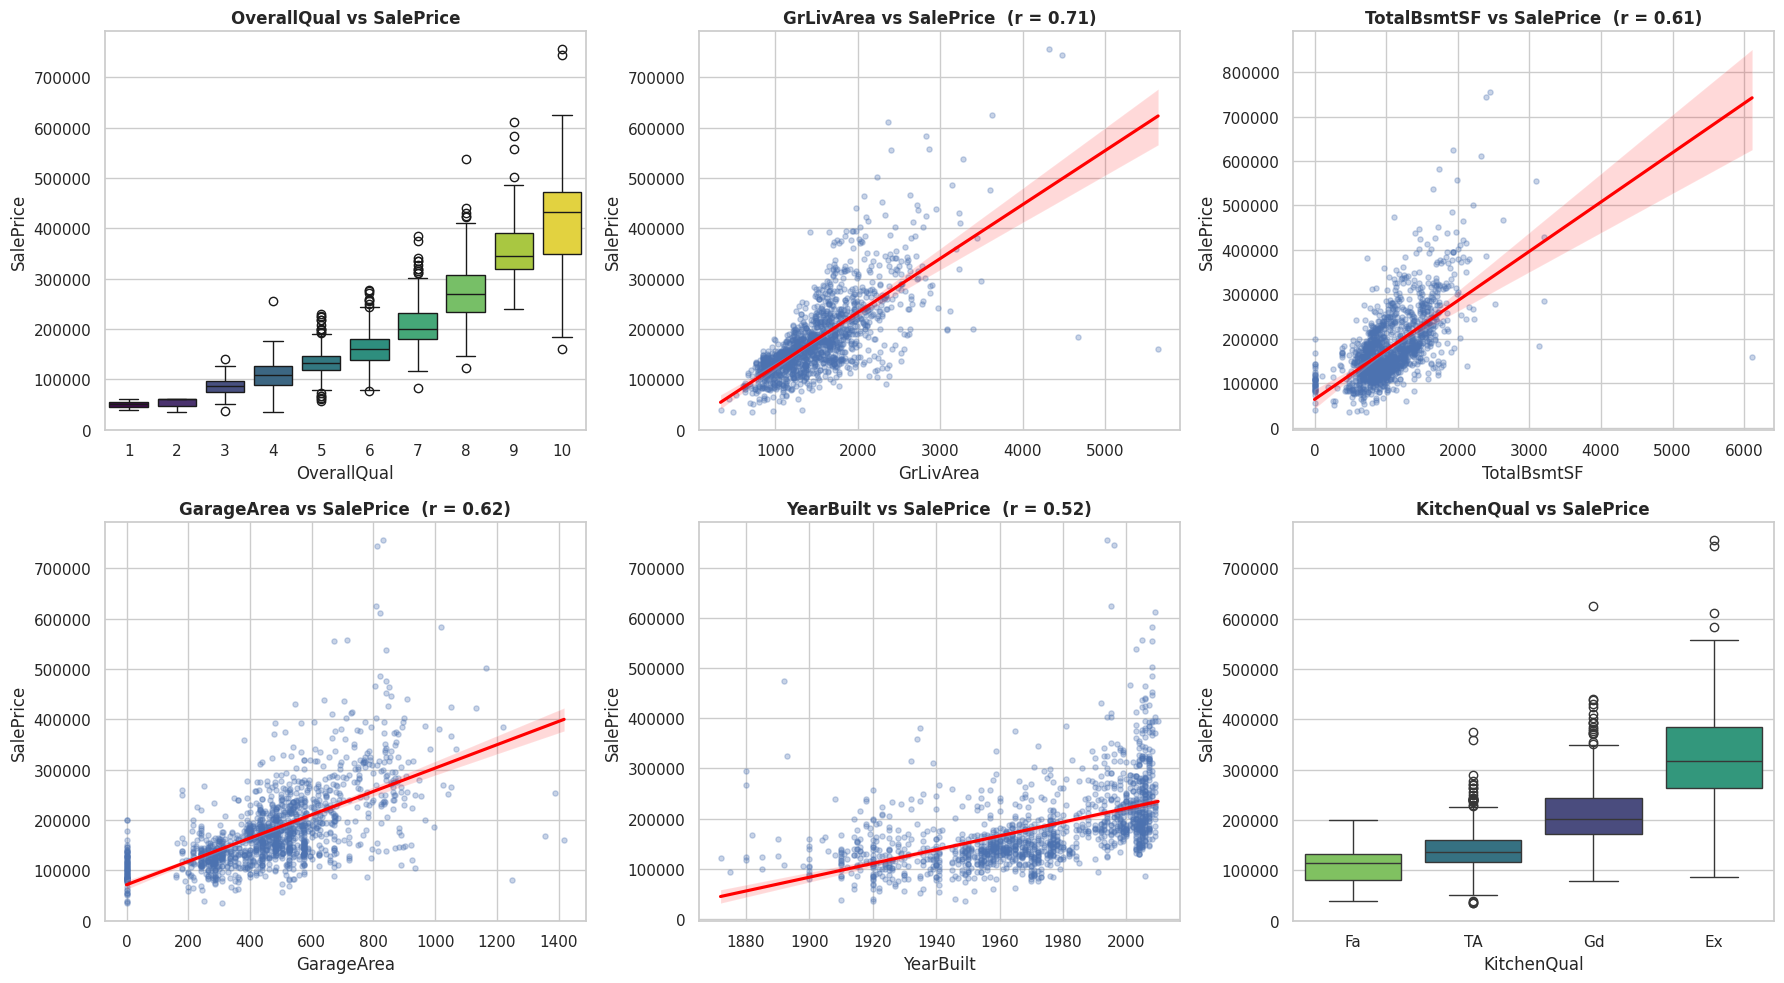

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.boxplot(data=df, x="OverallQual", y=TARGET, ax=axes[0, 0], palette=PALETTE, hue="OverallQual", legend=False)
axes[0, 0].set_title("OverallQual vs SalePrice")
for ax, col in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]],
                   ["GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]):
    sns.regplot(data=df, x=col, y=TARGET, ax=ax, scatter_kws={"alpha": 0.3, "s": 14},
                line_kws={"color": "red"})
    ax.set_title(f"{col} vs SalePrice  (r = {df[col].corr(df[TARGET]):.2f})")
order = ["Po", "Fa", "TA", "Gd", "Ex"]
sns.boxplot(data=df, x="KitchenQual", y=TARGET, order=[o for o in order if o in df.KitchenQual.unique()],
            ax=axes[1, 2], palette=PALETTE, hue="KitchenQual", legend=False)
axes[1, 2].set_title("KitchenQual vs SalePrice")
plt.tight_layout(); plt.show()

**Findings.** Price rises steadily with `OverallQual`, and the spread widens at higher levels. `GrLivArea`, `TotalBsmtSF` and `GarageArea` show clear positive linear trends, but the **variance grows with size** (a funnel shape), another reason to model `log(SalePrice)`. Newer houses (`YearBuilt`) cost more on average, although the relationship is noisier. Kitchen quality shows clear price steps from `TA` to `Gd` to `Ex`.

### Summary — Section 2
`SalePrice` is right-skewed (skew 1.88) and nearly symmetric after `log1p` (0.12), so the target will be log-transformed; many numerical features are also strongly skewed and need transformation. The strongest predictors are `OverallQual` (r = 0.79), `GrLivArea` (0.71), garage size (0.64) and basement area (0.61), and categorically the quality ratings and `Neighborhood`. Four houses exceed 4,000 sq ft; two of them (`Id` 524 and 1299, `Partial` sales) are true anomalies, recommended for removal from training. Several predictor pairs are strongly collinear (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`).

---
# Section 3 — Data Analysis & Insights
Each insight follows the same structure: **Question → Analysis → Visualization → Result (actual values) → Meaning.**

## Insight 1 — Housing prices overview
**Questions:** What are the mean, median, min and max `SalePrice`? Which houses are the most and least expensive? How does price vary with `GrLivArea`? What characterizes the most expensive houses?

,SalePrice (USD)
mean,"180,921.00"
median,"163,000.00"
min,"34,900.00"
max,"755,000.00"
std,"79,443.00"


5 most expensive houses:


,Id,SalePrice,Neighborhood,OverallQual,GrLivArea,YearBuilt,GarageCars
691,692,755000,NoRidge,10,4316,1994,3
1182,1183,745000,NoRidge,10,4476,1996,3
1169,1170,625000,NoRidge,10,3627,1995,3
898,899,611657,NridgHt,9,2364,2009,3
803,804,582933,NridgHt,9,2822,2008,3


5 cheapest houses:


,Id,SalePrice,Neighborhood,OverallQual,GrLivArea,YearBuilt,GarageCars
495,496,34900,IDOTRR,4,720,1920,0
916,917,35311,IDOTRR,2,480,1949,1
968,969,37900,OldTown,3,968,1910,0
533,534,39300,BrkSide,1,334,1946,0
30,31,40000,IDOTRR,4,1317,1920,1


Top 10% = houses sold for >= $278,000  (147 houses)


,Other 90%,Top 10%,ratio
GrLivArea,"1,431.63","2,264.26",1.58
OverallQual,5.85,8.34,1.43
GarageCars,1.66,2.73,1.65
TotalBsmtSF,993.01,"1,632.86",1.64
YearBuilt,"1,968.47","1,996.29",1.01
LotArea,"9,906.47","15,968.49",1.61
FullBath,1.51,2.07,1.37


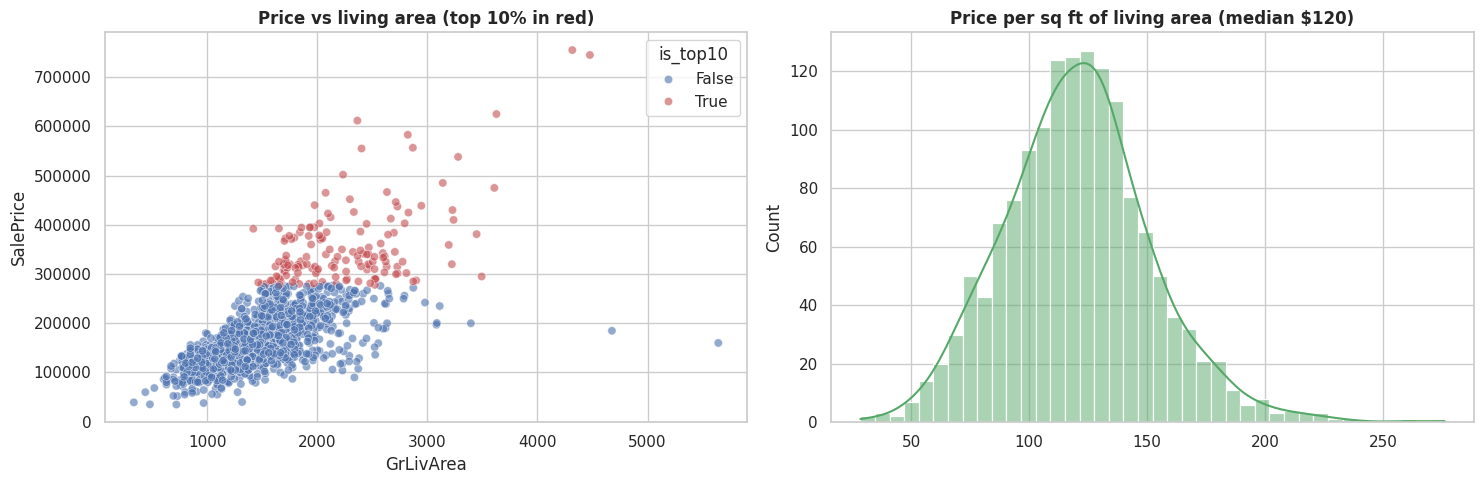

Top-10% houses: share by ExterQual: {'Gd': 66.0, 'Ex': 27.9, 'TA': 6.1}
Top-10% houses: top neighborhoods: {'NridgHt': 48, 'NoRidge': 27, 'Somerst': 13}


In [14]:
stats_tbl = price.agg(["mean", "median", "min", "max", "std"]).round(0).to_frame("SalePrice (USD)")
display(stats_tbl)

cols_show = ["Id", "SalePrice", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "GarageCars"]
print("5 most expensive houses:"); display(df.nlargest(5, TARGET)[cols_show])
print("5 cheapest houses:");       display(df.nsmallest(5, TARGET)[cols_show])

# Characteristics of the most expensive houses: top 10% vs the rest
threshold = price.quantile(0.90)
df["is_top10"] = price >= threshold
compare_cols = ["GrLivArea", "OverallQual", "GarageCars", "TotalBsmtSF", "YearBuilt", "LotArea", "FullBath"]
comp = df.groupby("is_top10")[compare_cols].mean().T
comp.columns = ["Other 90%", "Top 10%"]
comp["ratio"] = comp["Top 10%"] / comp["Other 90%"]
print(f"Top 10% = houses sold for >= ${threshold:,.0f}  ({df['is_top10'].sum()} houses)")
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df, x="GrLivArea", y=TARGET, hue="is_top10", palette={False: "#4c72b0", True: "#c44e52"},
                alpha=0.6, ax=ax[0]); ax[0].set_title("Price vs living area (top 10% in red)")
price_per_area = df[TARGET] / df["GrLivArea"]
sns.histplot(price_per_area, bins=40, kde=True, ax=ax[1], color="#55a868")
ax[1].set_title(f"Price per sq ft of living area (median ${price_per_area.median():,.0f})")
plt.tight_layout(); plt.show()

print("Top-10% houses: share by ExterQual:",
      (df.loc[df.is_top10, "ExterQual"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Top-10% houses: top neighborhoods:", df.loc[df.is_top10, "Neighborhood"].value_counts().head(3).to_dict())

**Result and meaning.**
* **Mean \$180,921, median \$163,000, min \$34,900, max \$755,000**, standard deviation about \$79,443. The mean exceeds the median because a few luxury houses pull it up.
* The **most expensive** houses are in **Northridge (`NoRidge`)**: `Id` 692 (\$755,000), 1183 (\$745,000) and 1170 (\$625,000), all with `OverallQual` 10 and built in the mid-1990s. The **cheapest** are in `IDOTRR` and `OldTown`: `Id` 496 (\$34,900, 720 sq ft, built 1920), 917 (\$35,311) and 969 (\$37,900), with low quality (2–4) and built before 1950.
* Price and living area have a clear positive relationship (r = 0.71): each additional square foot is associated with a higher price, but the spread widens for larger houses, so size alone is not enough.
* **Top-10% houses** (sold for at least \$278,000; 147 houses) are on average **58% larger** than the other 90% (2,264 vs 1,432 sq ft), have **quality 8.3 vs 5.9**, a garage for **2.7 vs 1.7 cars**, a basement about **64% larger** (1,633 vs 993 sq ft), a **61% larger lot**, and are about 28 years newer (built 1996 vs 1968). Almost all have `Gd` or `Ex` exterior quality, and **48 of 147 are in `NridgHt` and 27 in `NoRidge`**. In short: *expensive houses are bigger, newer, higher quality and located in specific neighborhoods.*

## Insight 2 — Neighborhood analysis
**Questions:** Which 3 neighborhoods are the most and least expensive on average? What are their average prices? Which has the most houses? Does neighborhood strongly relate to price?

Top 3 neighborhoods by average price:


,avg_price,median_price,houses
Neighborhood,,,
NoRidge,"335,295.00","301,500.00",41
NridgHt,"316,271.00","315,000.00",77
StoneBr,"310,499.00","278,000.00",25


Lowest 3 neighborhoods by average price:


,avg_price,median_price,houses
Neighborhood,,,
MeadowV,"98,576.00","88,000.00",17
IDOTRR,"100,124.00","103,000.00",37
BrDale,"104,494.00","106,000.00",16


Neighborhood with the most houses: NAmes (225 houses, 15.4% of the data)

ANOVA across neighborhoods: F = 71.8, p = 1.56e-225
Eta squared (variance of price explained by Neighborhood): 0.546


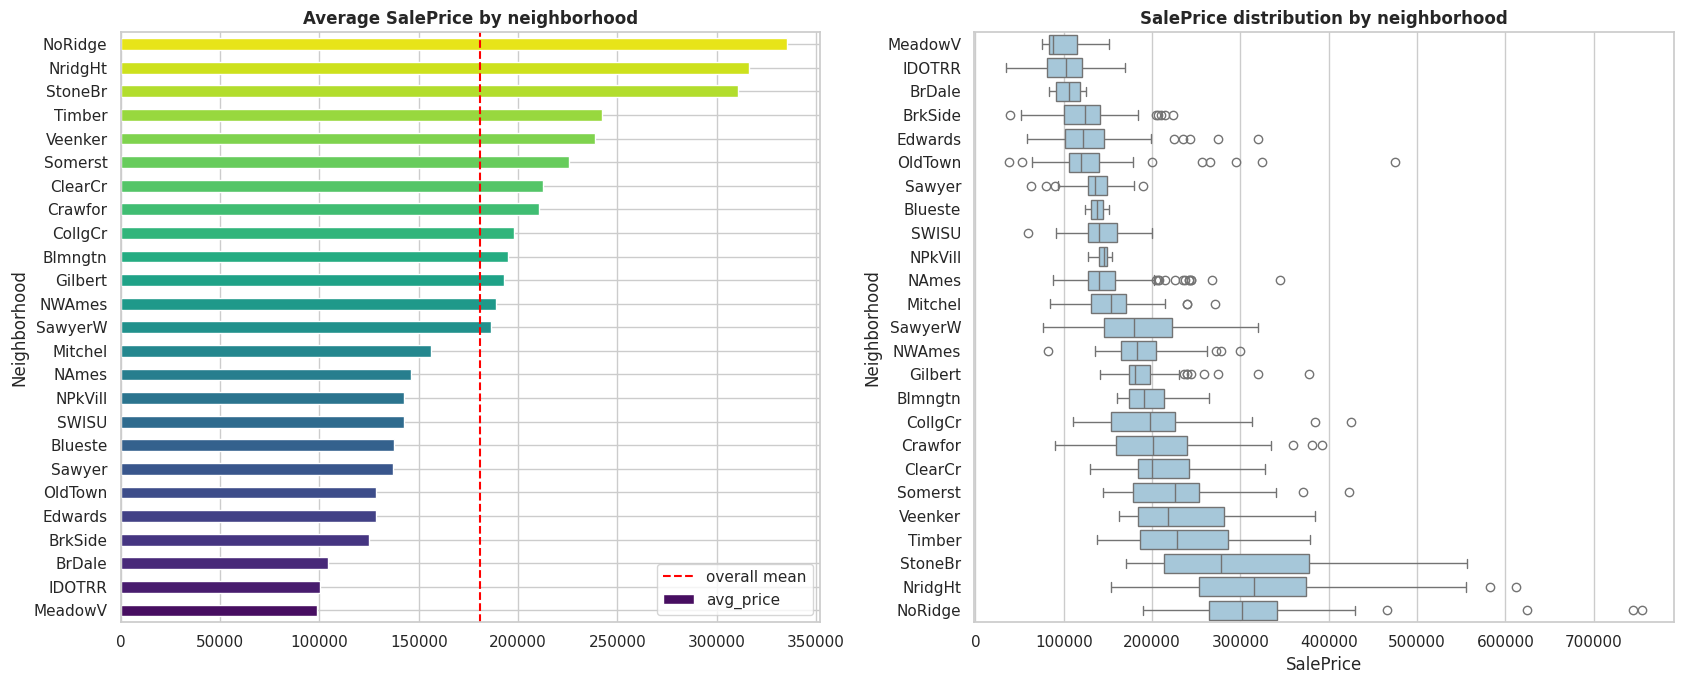

In [15]:
nb_stats = df.groupby("Neighborhood")[TARGET].agg(avg_price="mean", median_price="median", houses="count").sort_values("avg_price")
print("Top 3 neighborhoods by average price:");    display(nb_stats.tail(3).iloc[::-1].round(0))
print("Lowest 3 neighborhoods by average price:"); display(nb_stats.head(3).round(0))
most = nb_stats["houses"].idxmax()
print(f"Neighborhood with the most houses: {most} ({nb_stats.loc[most, 'houses']} houses, "
      f"{nb_stats.loc[most, 'houses'] / len(df):.1%} of the data)")

# ANOVA F-test: does mean SalePrice differ across neighborhoods?
f_stat, p_val = f_classif(df[[TARGET]], df["Neighborhood"])
print(f"\nANOVA across neighborhoods: F = {f_stat[0]:.1f}, p = {p_val[0]:.2e}")
print(f"Eta squared (variance of price explained by Neighborhood): {eta_squared(df, 'Neighborhood'):.3f}")

order_nb = nb_stats.index
fig, ax = plt.subplots(1, 2, figsize=(17, 7))
nb_stats["avg_price"].plot.barh(ax=ax[0], color=sns.color_palette(PALETTE, len(nb_stats)))
ax[0].axvline(price.mean(), color="red", ls="--", label="overall mean"); ax[0].legend()
ax[0].set_title("Average SalePrice by neighborhood")
sns.boxplot(data=df, y="Neighborhood", x=TARGET, order=order_nb, ax=ax[1], color="#9ecae1")
ax[1].set_title("SalePrice distribution by neighborhood")
plt.tight_layout(); plt.show()

**Result and meaning.**
* **Top 3 (average price):** `NoRidge` **\$335,295**, `NridgHt` **\$316,271**, `StoneBr` **\$310,499**.
* **Lowest 3:** `MeadowV` **\$98,576**, `IDOTRR` **\$100,124**, `BrDale` **\$104,494**.
* The most populated neighborhood is **`NAmes` (North Ames) with 225 houses (15.4%)**.
* The best neighborhoods average about **3.3×** the price of the worst. An ANOVA gives F = 71.8, p ≈ 1.6e-225, and **neighborhood alone explains about 54.6% of the variance in price** (eta squared = 0.546). **Neighborhood has a very strong relationship with price** and will be an important feature, so it deserves one-hot encoding. Note that the expensive neighborhoods (e.g. `NoRidge`) also contain a wide price range, while the cheap ones are tightly clustered.

## Insight 3 — Time-based analysis (seasonality)
**Questions:** Which month has the highest and lowest average price? Which month has the most sales? Does the price vary throughout the year?

,avg_price,median_price,sales
Jan,"183,256.00","151,650.00",58
Feb,"177,882.00","173,250.00",52
Mar,"183,254.00","165,250.00",106
Apr,"171,503.00","147,000.00",141
May,"172,307.00","154,000.00",204
Jun,"177,396.00","163,000.00",253
Jul,"186,331.00","165,195.00",234
Aug,"184,652.00","174,450.00",122
Sep,"195,683.00","185,900.00",63
Oct,"179,564.00","159,000.00",89


Highest average price : Sep  ($195,683)
Lowest  average price : Apr  ($171,503)
Most sales            : Jun  (253 houses)

ANOVA on log(price) (is price different across months?): F = 0.99, p = 0.450


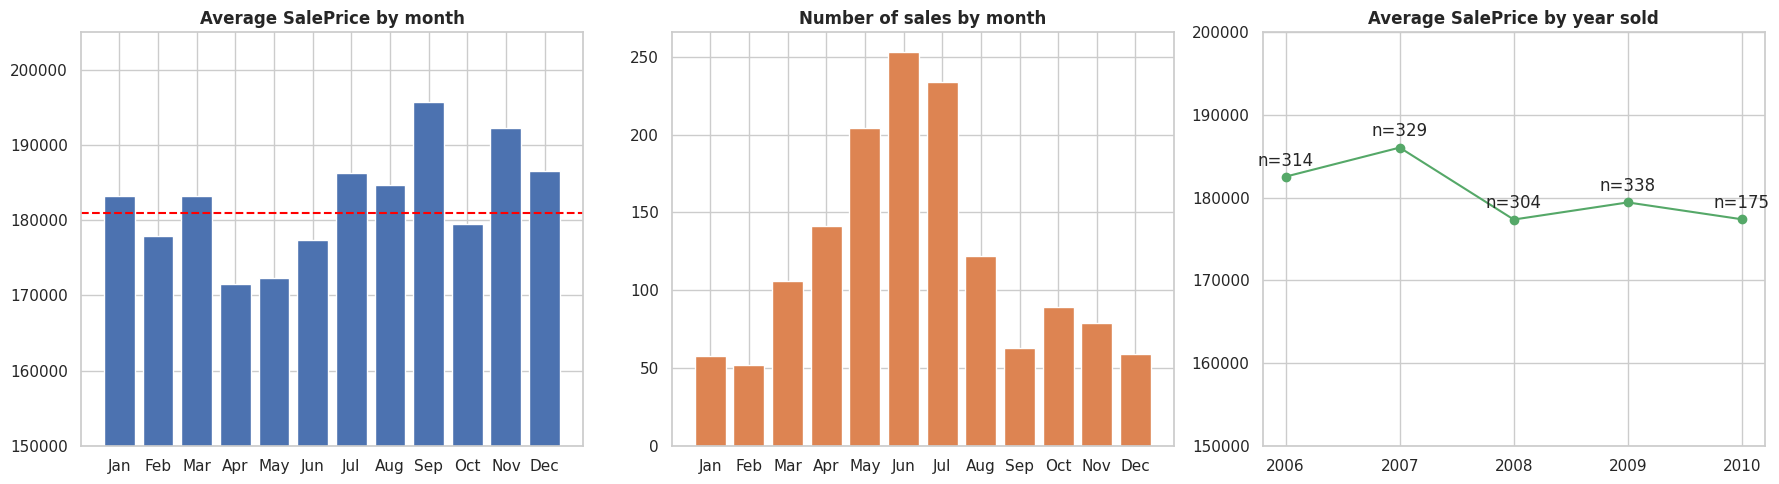

In [16]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = df.groupby("MoSold")[TARGET].agg(avg_price="mean", median_price="median", sales="count")
monthly.index = month_names
display(monthly.round(0))
print(f"Highest average price : {monthly['avg_price'].idxmax()}  (${monthly['avg_price'].max():,.0f})")
print(f"Lowest  average price : {monthly['avg_price'].idxmin()}  (${monthly['avg_price'].min():,.0f})")
print(f"Most sales            : {monthly['sales'].idxmax()}  ({monthly['sales'].max()} houses)")

# ANOVA F-test on log(price) (log makes the skewed prices closer to normal, as ANOVA assumes)
f_m, p_m = f_classif(np.log1p(df[[TARGET]]), df["MoSold"])
print(f"\nANOVA on log(price) (is price different across months?): F = {f_m[0]:.2f}, p = {p_m[0]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].bar(monthly.index, monthly["avg_price"], color="#4c72b0"); ax[0].axhline(price.mean(), color="red", ls="--")
ax[0].set_title("Average SalePrice by month"); ax[0].set_ylim(150000, 205000)
ax[1].bar(monthly.index, monthly["sales"], color="#dd8452"); ax[1].set_title("Number of sales by month")
yearly = df.groupby("YrSold")[TARGET].agg(["mean", "count"])
ax[2].plot(yearly.index, yearly["mean"], marker="o", color="#55a868"); ax[2].set_xticks(yearly.index)
ax[2].set_title("Average SalePrice by year sold"); ax[2].set_ylim(150000, 200000)
for yr, row in yearly.iterrows(): ax[2].annotate(f"n={int(row['count'])}", (yr, row["mean"]), textcoords="offset points", xytext=(0, 8), ha="center")
plt.tight_layout(); plt.show()

**Result and meaning.**
* **Highest average price: September (\$195,683); lowest: April (\$171,503)**, a gap of about \$24k (14%).
* **Most sales: June (253 houses)**, followed by July (234) and May (204): the market is **strongly seasonal in volume**, with a peak in late spring and summer.
* However, the price differences across months are **not statistically significant** (ANOVA on log price: F = 0.99, p = 0.45). September's high average is based on only 63 sales, and the median pattern differs from the mean one (e.g. January has one of the highest averages but one of the lowest medians, \$151,650 vs \$183,256 mean). So **month of sale has little reliable effect on price**; volume has seasonality but price does not.
* Yearly averages are flat (about \$177k–186k from 2006 to 2010) even through the 2008 financial crisis. Note that 2010 data covers only January–July.

## Insight 4 — Do bedrooms affect price?
**Question:** Does the number of bedrooms above ground (`BedroomAbvGr`) affect `SalePrice`?

,avg_price,median_price,houses
BedroomAbvGr,,,
0,"221,493.00","202,500.00",6
1,"173,162.00","145,250.00",50
2,"158,198.00","137,250.00",358
3,"181,057.00","169,945.00",804
4,"220,421.00","193,500.00",213
5,"180,819.00","161,500.00",21
6,"143,779.00","141,000.00",7
8,"200,000.00","200,000.00",1


Correlation BedroomAbvGr vs SalePrice : 0.168
Correlation BedroomAbvGr vs GrLivArea : 0.521

Same size (GrLivArea 1,200-1,800 sq ft):


,avg_price,houses
BedroomAbvGr,,
0,"218,320.00",3
1,"218,228.00",16
2,"189,528.00",152
3,"178,728.00",451
4,"141,176.00",66
5,"161,500.00",1
6,"132,700.00",5


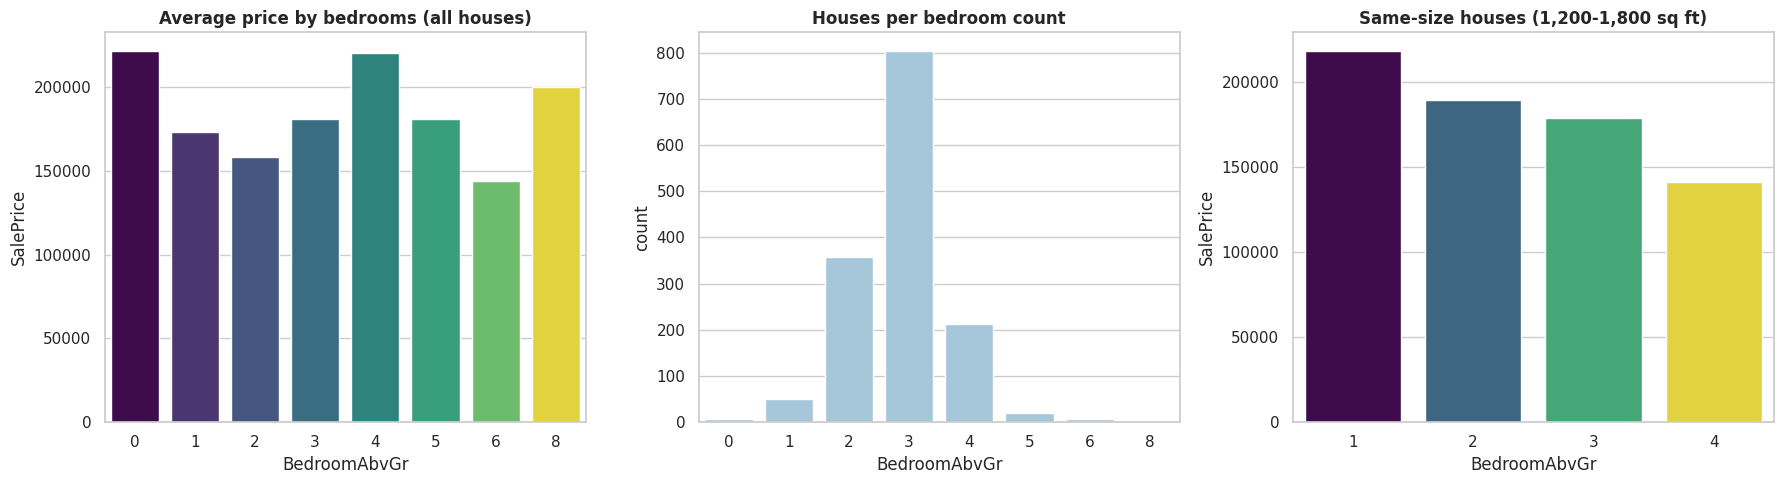

In [17]:
bed = df.groupby("BedroomAbvGr")[TARGET].agg(avg_price="mean", median_price="median", houses="count")
display(bed.round(0))
print(f"Correlation BedroomAbvGr vs SalePrice : {df['BedroomAbvGr'].corr(df[TARGET]):.3f}")
print(f"Correlation BedroomAbvGr vs GrLivArea : {df['BedroomAbvGr'].corr(df['GrLivArea']):.3f}")

# Control for size: compare houses with similar living area (1,200 - 1,800 sq ft)
similar = df[df["GrLivArea"].between(1200, 1800)]
ctrl = similar.groupby("BedroomAbvGr")[TARGET].agg(avg_price="mean", houses="count")
print("\nSame size (GrLivArea 1,200-1,800 sq ft):"); display(ctrl.round(0))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=df, x="BedroomAbvGr", y=TARGET, ax=ax[0], palette=PALETTE, hue="BedroomAbvGr", legend=False, errorbar=None)
ax[0].set_title("Average price by bedrooms (all houses)")
sns.countplot(data=df, x="BedroomAbvGr", ax=ax[1], color="#9ecae1"); ax[1].set_title("Houses per bedroom count")
sns.barplot(data=similar[similar.BedroomAbvGr.between(1, 4)], x="BedroomAbvGr", y=TARGET, ax=ax[2],
            palette=PALETTE, hue="BedroomAbvGr", legend=False, errorbar=None)
ax[2].set_title("Same-size houses (1,200-1,800 sq ft)")
plt.tight_layout(); plt.show()

**Result and meaning.**
* The overall correlation is weak (**r = 0.17**), and the relationship is **not monotonic**: 3-bedroom houses average \$181,057 and 4-bedroom \$220,421, but 2-bedroom houses (\$158,198) are cheaper than 1-bedroom (\$173,162), and 5–6 bedroom houses are *cheaper* than 4-bedroom ones (\$143,779 for 6, but only 7 houses).
* The reason is **size**: bedrooms correlate with living area (r = 0.52), so part of the apparent bedroom effect is really an area effect. When we compare houses of **similar size (1,200–1,800 sq ft)**, **more bedrooms means a *lower* price**: \$218k (1 bed), \$190k (2 beds), \$179k (3 beds), \$141k (4 beds). Packing more bedrooms into the same area gives smaller rooms and probably signals older, cheaper housing.
* **Conclusion:** bedroom count is a weak, indirect predictor; living area and quality matter far more.

## Insight 5 — Bathrooms and price
**Question:** How does the number of bathrooms relate to `SalePrice`?

,avg_price,houses
FullBath,,
0,"165,201.00",9
1,"134,751.00",650
2,"213,010.00",768
3,"347,823.00",33


Correlation FullBath vs SalePrice  : 0.561
Correlation TotalBath vs SalePrice : 0.632


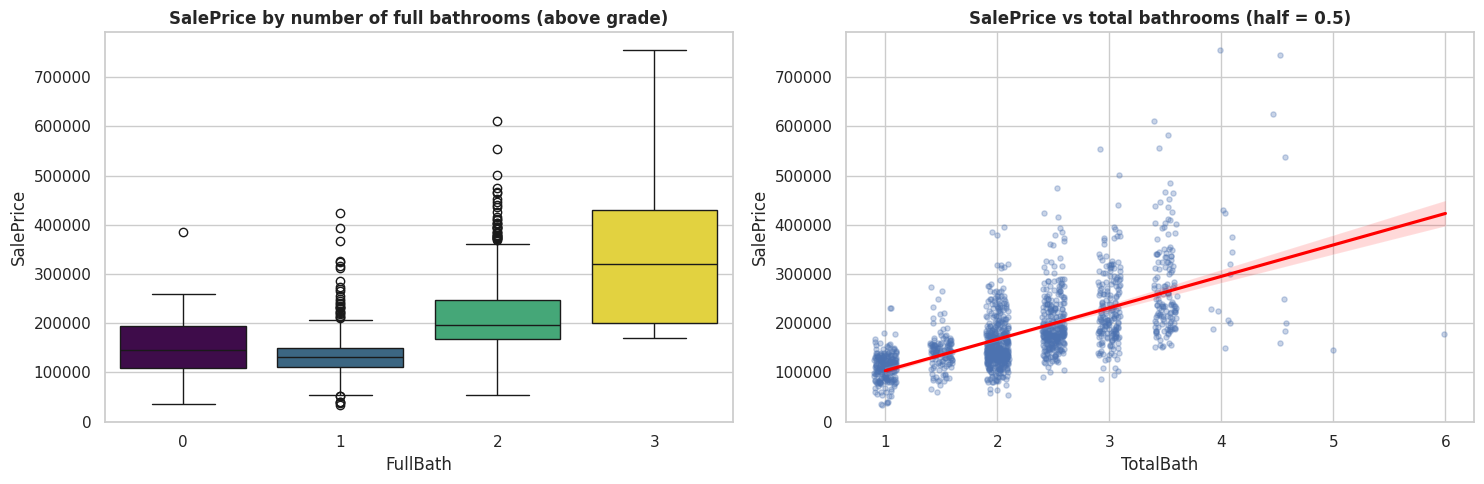

In [18]:
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
full_bath = df.groupby("FullBath")[TARGET].agg(avg_price="mean", houses="count"); display(full_bath.round(0))
print(f"Correlation FullBath vs SalePrice  : {df['FullBath'].corr(df[TARGET]):.3f}")
print(f"Correlation TotalBath vs SalePrice : {df['TotalBath'].corr(df[TARGET]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="FullBath", y=TARGET, ax=ax[0], palette=PALETTE, hue="FullBath", legend=False)
ax[0].set_title("SalePrice by number of full bathrooms (above grade)")
sns.regplot(data=df, x="TotalBath", y=TARGET, x_jitter=0.1, ax=ax[1], scatter_kws={"alpha": 0.3, "s": 14}, line_kws={"color": "red"})
ax[1].set_title("SalePrice vs total bathrooms (half = 0.5)")
plt.tight_layout(); plt.show()

**Result and meaning.** Price increases strongly with bathrooms: houses with **1 full bathroom average \$134,751, with 2 average \$213,010 and with 3 average \$347,823**. The correlation is r = 0.56 for `FullBath` and **0.63 for a combined `TotalBath`** (full + 0.5 × half, basement included), so combining all bathrooms is a better predictor than any single column. Bathrooms are partly a proxy for house size and quality (large, high-end houses have more of them), so **`TotalBath` is a good candidate engineered feature** for the modelling stage.

## Insight 6 — Overall quality
**Question:** How does `OverallQual` affect price?

,avg_price,median_price,houses,increase_vs_prev_%
OverallQual,,,,
1,"50,150.00","50,150.00",2,NaN
2,"51,770.30","60,000.00",3,3.20
3,"87,473.80","86,250.00",20,69.00
4,"108,420.70","108,000.00",116,23.90
5,"133,523.30","133,000.00",397,23.20
6,"161,603.00","160,000.00",374,21.00
7,"207,716.40","200,141.00",319,28.50
8,"274,735.50","269,750.00",168,32.30
9,"367,513.00","345,000.00",43,33.80


Pearson r = 0.791 | Spearman rho = 0.810


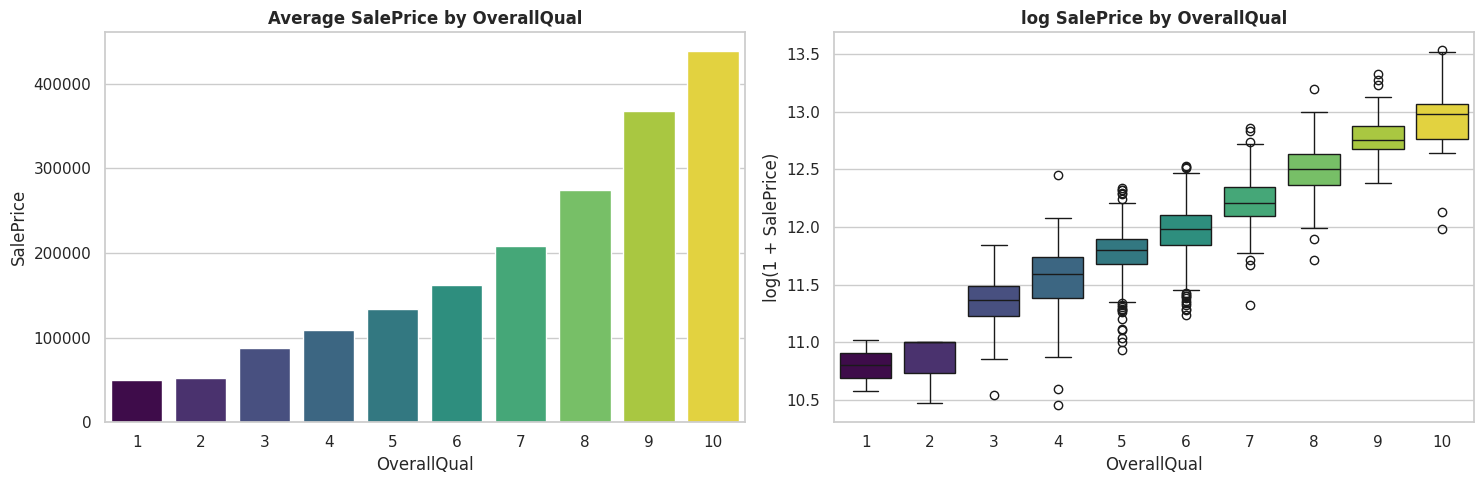

In [19]:
qual = df.groupby("OverallQual")[TARGET].agg(avg_price="mean", median_price="median", houses="count")
qual["increase_vs_prev_%"] = qual["avg_price"].pct_change() * 100
display(qual.round(1))
print(f"Pearson r = {df['OverallQual'].corr(df[TARGET]):.3f} | "
      f"Spearman rho = {df['OverallQual'].corr(df[TARGET], method='spearman'):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df, x="OverallQual", y=TARGET, ax=ax[0], palette=PALETTE, hue="OverallQual", legend=False, errorbar=None)
ax[0].set_title("Average SalePrice by OverallQual")
sns.boxplot(data=df, x="OverallQual", y=np.log1p(df[TARGET]), ax=ax[1], palette=PALETTE, hue="OverallQual", legend=False)
ax[1].set_ylabel("log(1 + SalePrice)"); ax[1].set_title("log SalePrice by OverallQual")
plt.tight_layout(); plt.show()

**Result and meaning.** Price rises at every step of quality: from about **\$50k at quality 1–2**, to **\$133,523 at quality 5**, **\$207,716 at quality 7**, **\$274,736 at quality 8** and **\$438,588 at quality 10**. A top-quality house costs roughly **8.7×** a quality-1 house and **3.3×** an average (quality 5) one. The Pearson correlation is **0.79** (the strongest in the dataset). The relationship is **convex in dollars but nearly linear in log(price)**, another argument for modelling the log of the price. Most houses are rated 5–7 (1,090 of 1,460), and the extreme levels have very few houses (1–2 and 10 have 2, 3 and 18 houses), so averages there are less reliable.

## Insight 7 — Garage capacity
**Question:** How does garage capacity (`GarageCars`) affect price?

,avg_price,median_price,houses
GarageCars,,,
0,"103,317.00","100,000.00",81
1,"128,117.00","128,000.00",369
2,"183,852.00","177,750.00",824
3,"309,636.00","295,000.00",181
4,"192,656.00","200,000.00",5


Correlation GarageCars vs SalePrice: 0.640
Correlation GarageCars vs GrLivArea: 0.467


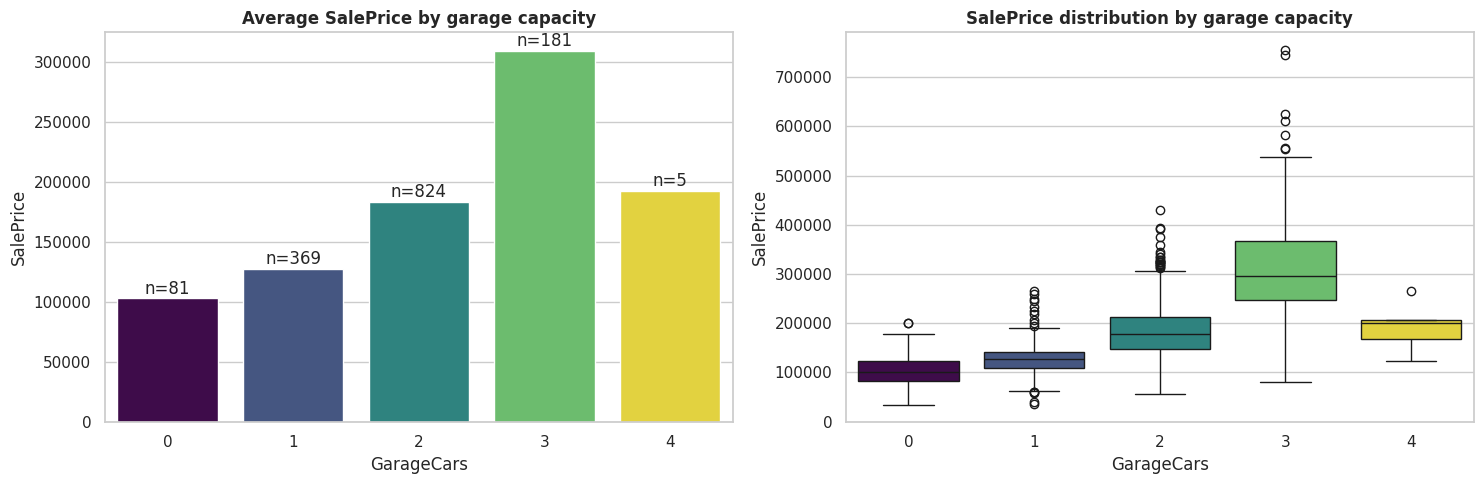

In [20]:
gar = df.groupby("GarageCars")[TARGET].agg(avg_price="mean", median_price="median", houses="count")
display(gar.round(0))
print(f"Correlation GarageCars vs SalePrice: {df['GarageCars'].corr(df[TARGET]):.3f}")
print(f"Correlation GarageCars vs GrLivArea: {df['GarageCars'].corr(df['GrLivArea']):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df, x="GarageCars", y=TARGET, ax=ax[0], palette=PALETTE, hue="GarageCars", legend=False, errorbar=None)
for i, (idx, r) in enumerate(gar.iterrows()): ax[0].text(i, r["avg_price"] + 4000, f"n={int(r['houses'])}", ha="center")
ax[0].set_title("Average SalePrice by garage capacity")
sns.boxplot(data=df, x="GarageCars", y=TARGET, ax=ax[1], palette=PALETTE, hue="GarageCars", legend=False)
ax[1].set_title("SalePrice distribution by garage capacity")
plt.tight_layout(); plt.show()

**Result and meaning.** Price grows sharply with garage capacity: **no garage \$103,317, 1 car \$128,117, 2 cars \$183,852, 3 cars \$309,636**. Going from 0 to 3 cars triples the average price. The exception is **4-car garages (\$192,656), but only 5 houses** have them, so this is noise, not a real drop. The correlation is **0.64**, so a larger garage is a strong price signal, partly because large, expensive houses (r = 0.47 with living area) tend to come with big garages. After 3 cars the benefit does not continue, and `GarageCars` and `GarageArea` carry almost the same information (see Section 2.6).

## Insight 8 — Does having a basement matter?
**Question:** Does having a basement significantly affect the average house price? (basement = `TotalBsmtSF > 0`)

,avg_price,median_price,houses
HasBasement,,,
Has basement,"182,878.00","165,000.00",1423
No basement,"105,653.00","101,800.00",37


ANOVA on log(price), basement vs none: F = 60.5, p = 1.37e-14
Difference in average price: $77,225  (73% higher)


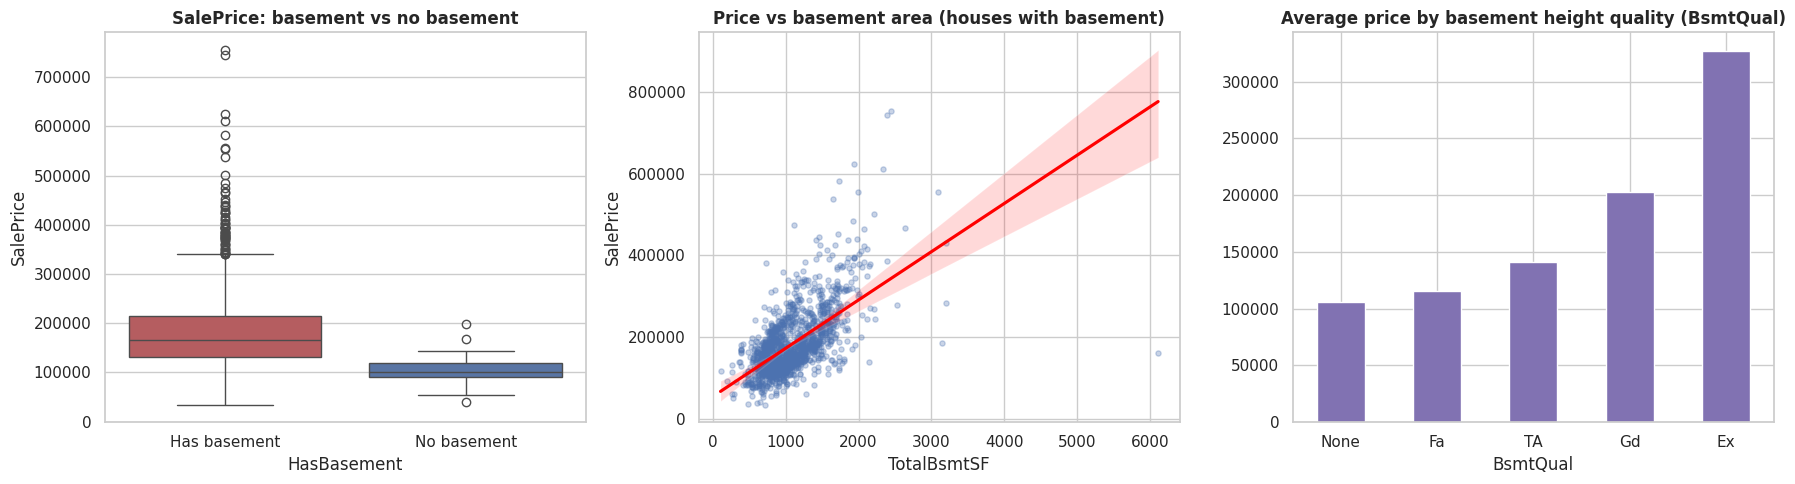

Average price by BsmtQual: {'None': 105653.0, 'Fa': 115692.0, 'TA': 140760.0, 'Gd': 202688.0, 'Ex': 327041.0}
Average GrLivArea  basement vs none: {'Has basement': 1521.0, 'No basement': 1289.0}


In [21]:
df["HasBasement"] = np.where(df["TotalBsmtSF"] > 0, "Has basement", "No basement")
bs = df.groupby("HasBasement")[TARGET].agg(avg_price="mean", median_price="median", houses="count")
display(bs.round(0))
f_b, p_b = f_classif(np.log1p(df[[TARGET]]), df["HasBasement"])   # ANOVA on log(price), 2 groups
print(f"ANOVA on log(price), basement vs none: F = {f_b[0]:.1f}, p = {p_b[0]:.2e}")
diff = bs.loc["Has basement", "avg_price"] - bs.loc["No basement", "avg_price"]
print(f"Difference in average price: ${diff:,.0f}  ({diff / bs.loc['No basement', 'avg_price']:.0%} higher)")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="HasBasement", y=TARGET, ax=ax[0], palette=["#c44e52", "#4c72b0"], hue="HasBasement", legend=False)
ax[0].set_title("SalePrice: basement vs no basement")
sns.regplot(data=df[df.TotalBsmtSF > 0], x="TotalBsmtSF", y=TARGET, ax=ax[1], scatter_kws={"alpha": 0.3, "s": 14}, line_kws={"color": "red"})
ax[1].set_title("Price vs basement area (houses with basement)")
bq = df.groupby("BsmtQual")[TARGET].mean().reindex(["None", "Fa", "TA", "Gd", "Ex"])
bq.plot.bar(ax=ax[2], color="#8172b2", rot=0); ax[2].set_title("Average price by basement height quality (BsmtQual)")
plt.tight_layout(); plt.show()
print("Average price by BsmtQual:", bq.round(0).to_dict())
print("Average GrLivArea  basement vs none:", df.groupby("HasBasement")["GrLivArea"].mean().round(0).to_dict())

**Result and meaning.** Houses **with a basement average \$182,878** versus **\$105,653 without**, a difference of about \$77k (73% higher); the difference is statistically significant (ANOVA on log price: F = 60.5, p ≈ 1.4e-14). Caution: only **37 houses (2.5%) have no basement**, and these are mostly small, older houses, so part of the gap reflects overall house type instead of the basement itself. Beyond presence, the **quality and size of the basement matter**: average price rises from `TA` to `Gd` to `Ex` basement height, and `TotalBsmtSF` has r = 0.61 with price. So the basement is informative, mostly through its size and quality.

## Insight 9 — House age
**Question:** How does house age (`YrSold − YearBuilt`) affect `SalePrice`?

,avg_price,median_price,houses
HouseAge,,,
0-5,"247,235.00","225,500.00",310
6-20,"226,734.00","212,500.00",254
21-40,"158,938.00","149,900.00",273
41-60,"144,104.00","139,000.00",331
60+,"132,956.00","120,750.00",292


Correlation HouseAge vs SalePrice : -0.523
Correlation RemodAge vs SalePrice : -0.509
Houses remodeled after construction: 47.7%


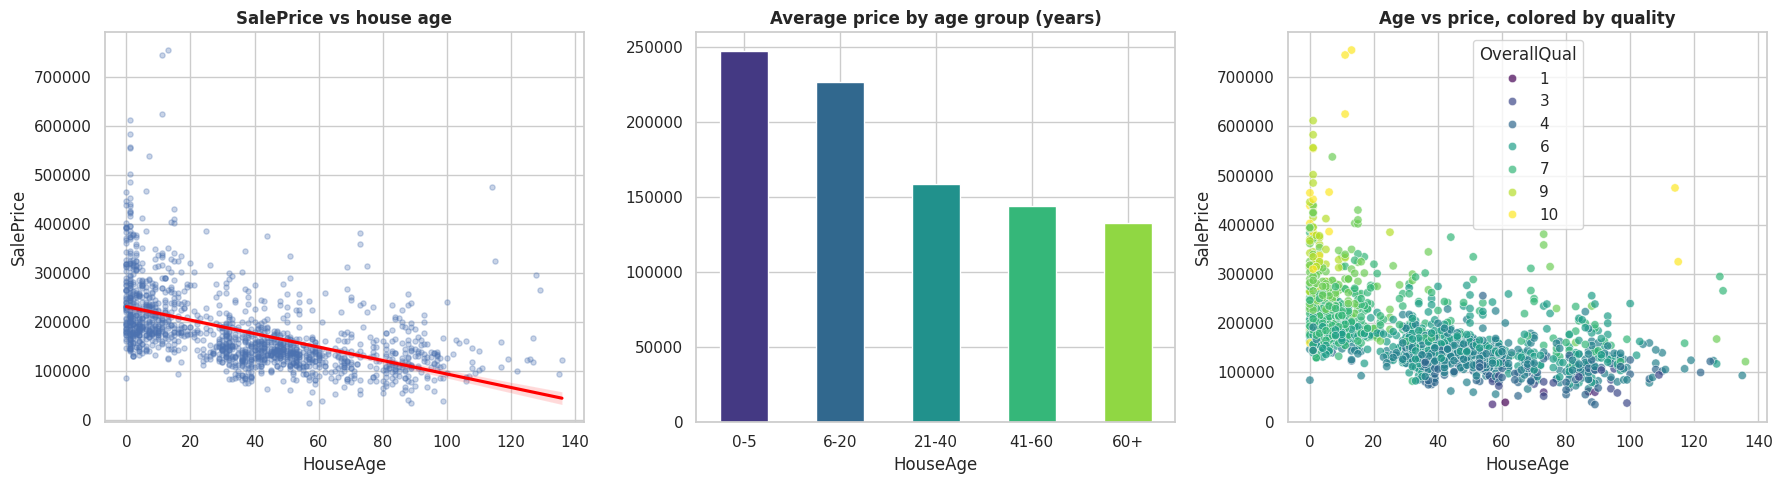

Average OverallQual by age group: {'0-5': 7.46, '6-20': 6.96, '21-40': 5.69, '41-60': 5.16, '60+': 5.35}


In [22]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
age_bins = pd.cut(df["HouseAge"], [-1, 5, 20, 40, 60, 200], labels=["0-5", "6-20", "21-40", "41-60", "60+"])
age_tbl = df.groupby(age_bins, observed=True)[TARGET].agg(avg_price="mean", median_price="median", houses="count")
display(age_tbl.round(0))
print(f"Correlation HouseAge vs SalePrice : {df['HouseAge'].corr(df[TARGET]):.3f}")
print(f"Correlation RemodAge vs SalePrice : {df['RemodAge'].corr(df[TARGET]):.3f}")
print(f"Houses remodeled after construction: {(df.YearRemodAdd > df.YearBuilt).mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.regplot(data=df, x="HouseAge", y=TARGET, ax=ax[0], scatter_kws={"alpha": 0.3, "s": 14}, line_kws={"color": "red"})
ax[0].set_title("SalePrice vs house age")
age_tbl["avg_price"].plot.bar(ax=ax[1], color=sns.color_palette(PALETTE, 5), rot=0); ax[1].set_title("Average price by age group (years)")
sns.scatterplot(data=df, x="HouseAge", y=TARGET, hue="OverallQual", palette="viridis", ax=ax[2], alpha=0.7)
ax[2].set_title("Age vs price, colored by quality")
plt.tight_layout(); plt.show()
print("Average OverallQual by age group:", df.groupby(age_bins, observed=True)["OverallQual"].mean().round(2).to_dict())

**Result and meaning.** Age and price are negatively related (**r = −0.52**): houses 0–5 years old average **\$247,235**, 6–20 years **\$226,734**, 21–40 years **\$158,938**, 41–60 years **\$144,105** and over 60 years **\$132,956**. So a house under 5 years old costs about **86% more** than one over 60 years old. Most of the drop happens in the first 40 years, then the curve flattens. Age partly reflects construction quality (average `OverallQual` is 7.5 for 0–5-year-old houses vs 5.4 for 60+), and nearly half the houses (47.7%) were remodeled, which can offset age, so a **remodel-age feature** is worth considering in feature engineering.

## Additional Insight A — Price per square foot by neighborhood
**Question:** Is neighborhood's effect just because houses there are bigger?

,median_ppsf,median_area,houses
Neighborhood,,,
SWISU,80.60,"1,691.00",25
IDOTRR,90.60,"1,128.00",37
BrDale,91.10,"1,155.00",16
Veenker,143.80,"1,437.00",11
StoneBr,157.90,"1,742.00",25
NridgHt,158.00,"1,850.00",77


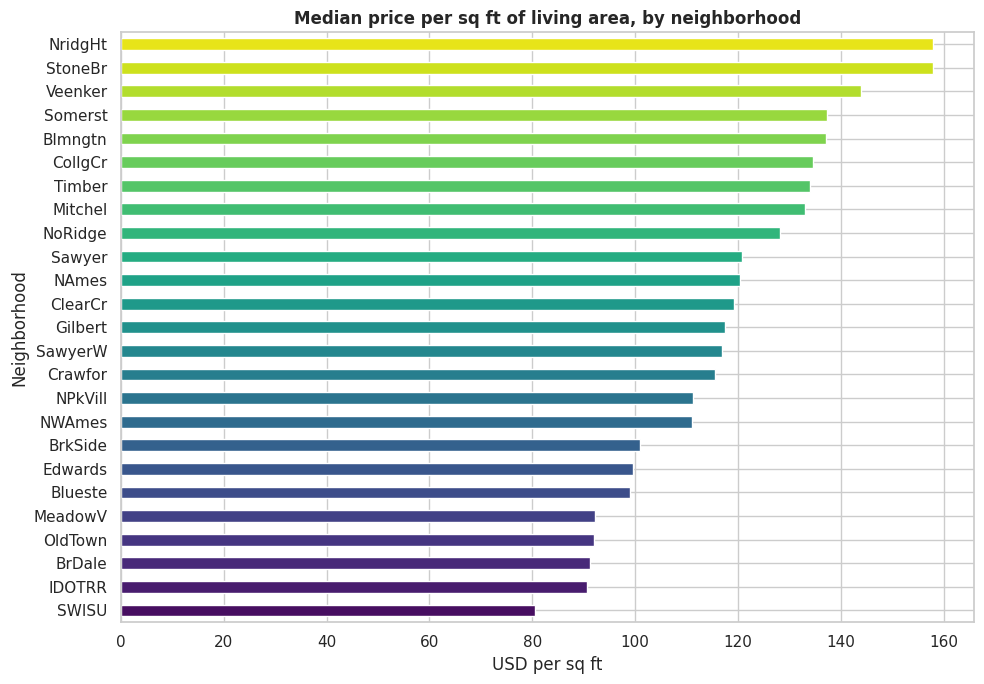

In [23]:
df["PricePerSqFt"] = df[TARGET] / df["GrLivArea"]
ppsf = df.groupby("Neighborhood").agg(median_ppsf=("PricePerSqFt", "median"), median_area=("GrLivArea", "median"), houses=("Id", "count")).sort_values("median_ppsf")
display(pd.concat([ppsf.head(3), ppsf.tail(3)]).round(1))
fig, ax = plt.subplots(figsize=(10, 7))
ppsf["median_ppsf"].plot.barh(ax=ax, color=sns.color_palette(PALETTE, len(ppsf)))
ax.set_title("Median price per sq ft of living area, by neighborhood"); ax.set_xlabel("USD per sq ft")
plt.tight_layout(); plt.show()

**Result and meaning.** Even after dividing out size, location still matters a lot: `NridgHt` (\$158/sq ft) and `StoneBr` (\$158/sq ft) are almost **twice** as expensive per square foot as `SWISU` (\$81/sq ft) and `IDOTRR` (\$91/sq ft). So the neighborhood premium is **not only about bigger houses**; it also captures quality and desirability of the location.

## Additional Insight B — Condition of sale
**Question:** Do some sale conditions behave differently?

,avg_price,avg_quality,houses
SaleCondition,,,
Partial,"272,291.80",7.60,125
Normal,"175,202.20",6.00,1198
Alloca,"167,377.40",5.40,12
Family,"149,600.00",5.80,20
Abnorml,"146,526.60",5.60,101
AdjLand,"104,125.00",5.00,4


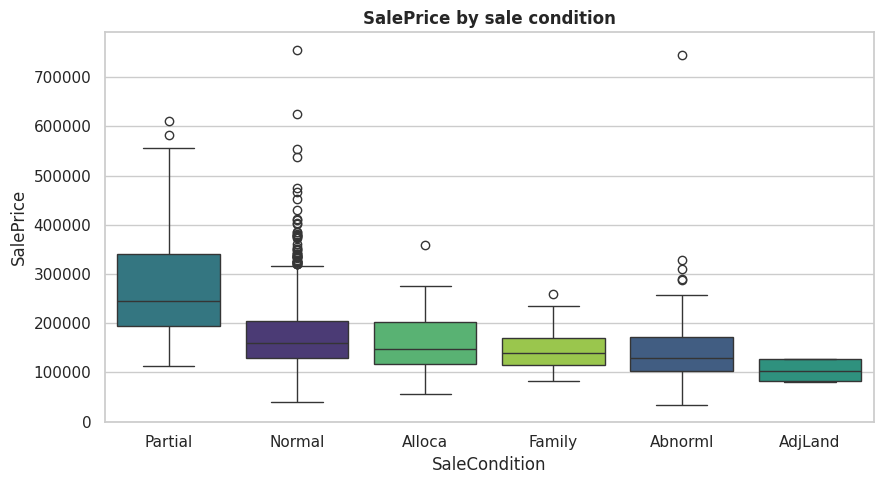

In [24]:
sc = df.groupby("SaleCondition").agg(avg_price=(TARGET, "mean"), avg_quality=("OverallQual", "mean"), houses=(TARGET, "count")).sort_values("avg_price", ascending=False)
display(sc.round(1))
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="SaleCondition", y=TARGET, order=sc.index, ax=ax, palette=PALETTE, hue="SaleCondition", legend=False)
ax.set_title("SalePrice by sale condition"); plt.tight_layout(); plt.show()

**Result and meaning.** `Partial` sales (new houses not yet completed when assessed) are the most expensive at **\$272,292 on average (125 houses)**, while `Abnorml` sales (foreclosures, short sales) are cheaper at **\$146,527 (101 houses)** than `Normal` sales (**\$175,202**, 1,198 houses). So the **type of sale carries information** and should stay as a feature. It also explains why the two large `Partial` houses (Section 2.5) had low prices.

### Summary — Section 3
Mean/median price is \$180,921 / \$163,000, and the most expensive houses are large, new, high-quality homes concentrated in `NoRidge`/`NridgHt`. **Neighborhood alone explains 54.6% of price variance** (top 3 average \$310k–\$335k vs lowest 3 about \$99k–\$104k), while **month of sale has no significant effect** (p = 0.45) even though June has the most sales (253). Quality, size and garage are the strongest drivers: price rises from about \$50k at `OverallQual` 1–2 to \$439k at 10, from \$103k with no garage to \$310k with a 3-car garage, and from \$135k with one bathroom to \$348k with three. Bedrooms are a weak, *negative* factor once size is controlled; newer houses sell for far more (\$247k for 0–5 years vs \$133k for 60+).

---
# Handoff to Part 2 (Preprocessing & Pipelines)

Variables prepared by Part 1:

| Variable | Content |
|---|---|
| `df` | Full dataset (1,460 × 81). read with plain `pd.read_csv`; structural NaNs already treated in Section 1.3 (category `"None"`, 0 or `YearBuilt`), only `LotFrontage` and `Electrical` still contain `NaN` |
| `cols_num` | 34 numerical features |
| `cols_nominal` | 23 nominal features (includes `MSSubClass` and `MoSold`) → One-Hot |
| `cols_ordinal` | 22 ordinal features → OrdinalEncoder |
| `ordinal_orders` | dict `{column: [categories lowest → highest]}` for `OrdinalEncoder(categories=...)` |

**Notes for Part 2**
1. Before modelling, **drop the helper columns** created for the analysis in Section 3 (`is_top10`, `TotalBath`, `HasBasement`, `HouseAge`, `RemodAge`, `PricePerSqFt`) and the `Id` column: the cell below does it for you. `PricePerSqFt` is computed from the target, so it **must never** be used as a feature (data leakage).
2. Missing values still to impute **inside the pipeline (fit on train only)**: `LotFrontage` (numerical, use the median; zero would be wrong because every lot touches a street) and `Electrical` (nominal, most frequent). Everything else was handled in Section 1.3: `MasVnrArea` → 0, `GarageYrBlt` → `YearBuilt`, absent features → `"None"`.
3. `OrdinalEncoder` must receive `categories=[ordinal_orders[c] for c in cols_ordinal]` so the order is respected.
4. Suggested decisions from the EDA: log-transform `SalePrice` (or Yeo-Johnson, both give skew ≈ 0); apply **`PowerTransformer(method='yeo-johnson')`** to the numerical features inside the numerical pipeline (18 features have |skew| > 1, see Section 2.3); consider removing training rows with `Id` 524 and 1299; mind the collinear pairs (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`).
5. Candidate engineered features suggested by the insights: total bathrooms, house age, remodel age, total square feet.

In [25]:
# ---- Clean handoff: remove analysis-only helper columns and the identifier ----
helper_cols = ["is_top10", "TotalBath", "HasBasement", "HouseAge", "RemodAge", "PricePerSqFt"]
df = df.drop(columns=helper_cols + ["Id"])

# ---- Final integrity checks ----
assert df.shape == (1460, 80)
assert set(cols_num + cols_nominal + cols_ordinal + [TARGET]) == set(df.columns)
assert df.duplicated().sum() == 0
print("df ready for Part 2:", df.shape)
print("Missing values still left for the Part 2 pipeline:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print(f"\ncols_num={len(cols_num)}  cols_nominal={len(cols_nominal)}  cols_ordinal={len(cols_ordinal)}")

df ready for Part 2: (1460, 80)
Missing values still left for the Part 2 pipeline:
LotFrontage    259
Electrical       1

cols_num=34  cols_nominal=23  cols_ordinal=22


---
## ▶ Part 2 starts here (Section 4 — Preprocessing)

---
# Section 4 — Data Preprocessing
Everything that *learns* statistics (imputation values, power-transform lambdas, scaler mean/std, encoder categories) is done **inside the pipelines (Section 5)** and fitted on the training set only. In this section we only do row-wise cleaning, feature construction and the data split, none of which learns anything from the data, so there is no leakage.

### 4.1 Handoff check

In [26]:
from sklearn.model_selection import train_test_split

for name in ["df", "cols_num", "cols_nominal", "cols_ordinal", "ordinal_orders", "TARGET", "RANDOM_STATE"]:
    assert name in globals(), f"{name} is missing - run Part 1 first"
print("df:", df.shape, "| num:", len(cols_num), "| nominal:", len(cols_nominal), "| ordinal:", len(cols_ordinal))

df: (1460, 80) | num: 34 | nominal: 23 | ordinal: 22


### 4.2 Missing values and duplicates
The structural `NaN`s (absent pool, garage, basement, ...) were already converted to the category `"None"` (or 0 / `YearBuilt`) in Section 1.3. Two columns still contain real missing values: `LotFrontage` (259) and `Electrical` (1). They are imputed **inside the pipelines** so the fill values are learned from the training set only: **median** for numerical features (`LotFrontage` is right-skewed, so the median is more robust than the mean) and **most frequent** for categorical features. An imputer is included in all three pipelines, which also protects against unseen `NaN`s in new data.

Duplicates: the check below shows none, so no rows are removed.

In [27]:
print("Duplicated rows:", df.duplicated().sum())
left = df.isna().sum()
print("\nColumns still containing NaN:")
print(left[left > 0].to_string())

Duplicated rows: 0

Columns still containing NaN:
LotFrontage    259
Electrical       1


### 4.3 Outliers
Section 2.5 found four houses above 4,000 sq ft. Two of them (`Id` 692 and 1183) are genuine luxury homes and are **kept**. The other two (`Id` 524 and 1299; **rows 523 and 1298** in `df`, because `Id` was dropped in Part 1) have the largest living areas (4,676 and 5,642 sq ft) and quality 10, yet sold for only $184,750 and $160,000. Both are `Partial` sales (house not completed when assessed), so their price does not reflect their size. They are data anomalies, not market behaviour, and would pull the fitted relationship between area and price down. They are removed before the split. This is a row-wise cleaning step that learns no statistics, so it causes no leakage.

In [28]:
OUTLIER_IDX = [523, 1298]          # df index of Id 524 and Id 1299
print(df.loc[OUTLIER_IDX, ["GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]])

rows_before = len(df)
df = df.drop(index=OUTLIER_IDX, errors="ignore")
print(f"\nRows: {rows_before} -> {len(df)}")
print("Corr(GrLivArea, SalePrice) after removal:", round(df["GrLivArea"].corr(df[TARGET]), 3))

      GrLivArea  SalePrice  OverallQual Neighborhood SaleCondition
523        4676     184750           10      Edwards       Partial
1298       5642     160000           10      Edwards       Partial

Rows: 1460 -> 1458
Corr(GrLivArea, SalePrice) after removal: 0.735


### 4.4 Feature engineering
Four features suggested by the insights of Part 1 are added. All are computed row by row from other columns of the same house, so they cannot leak information between rows:

| Feature | Formula | Reason |
|---|---|---|
| `TotalBath` | FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath | Insight 5: the combined count (r = 0.63) beats `FullBath` alone (0.56) |
| `HouseAge` | YrSold − YearBuilt | Insight 9: age is strongly negatively related to price (r = −0.52) |
| `RemodAge` | YrSold − YearRemodAdd | Nearly half of the houses were remodelled |
| `TotalSF` | TotalBsmtSF + 1stFlrSF + 2ndFlrSF | One total-area feature summarising several collinear area columns |

The original columns are kept (collinearity is not a problem for SVR or tree models).

In [29]:
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
df["HouseAge"]  = df["YrSold"] - df["YearBuilt"]
df["RemodAge"]  = df["YrSold"] - df["YearRemodAdd"]
df["TotalSF"]   = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

NEW_FEATURES = ["TotalBath", "HouseAge", "RemodAge", "TotalSF"]
cols_num = [c for c in cols_num if c not in NEW_FEATURES] + NEW_FEATURES   # safe to re-run
print("Numerical features now:", len(cols_num))
print(df[NEW_FEATURES].describe().T[["min", "mean", "max"]].round(2))
print("Negative values:", (df[NEW_FEATURES] < 0).sum().to_dict())

Numerical features now: 38
             min     mean      max
TotalBath   1.00     2.21     6.00
HouseAge    0.00    36.60   136.00
RemodAge    0.00    22.98    60.00
TotalSF   334.00 2,557.15 6,872.00
Negative values: {'TotalBath': 0, 'HouseAge': 0, 'RemodAge': 0, 'TotalSF': 0}


### 4.5 Target transformation and train / validation / test split
* **Target:** the models are trained on `log1p(SalePrice)`. The raw price is right-skewed (skewness ≈ 2.0 in the training data); after `log1p` it is almost symmetric. This also makes errors relative, and predictions are converted back to dollars with `expm1`. The raw prices are kept (`y_raw_*`) for reporting errors in dollars.
* **Split: 70 % train / 15 % validation / 15 % test**, `random_state = 42`, **stratified on price quintiles** so the three sets have similar price distributions. The training set is used for fitting and cross-validated tuning, the validation set for comparing models, and the test set only once, for the final evaluation.
* The split is done **before** any fitting. Every transformer is fitted on `X_train` only.

In [30]:
FEATURES = cols_num + cols_nominal + cols_ordinal
X     = df[FEATURES]
y_raw = df[TARGET]                  # price in dollars (for reporting)
y     = np.log1p(y_raw)             # modelling target

price_bins = pd.qcut(y_raw, q=5, labels=False)   # only used to stratify the split

X_tmp, X_test, y_tmp, y_test, y_raw_tmp, y_raw_test, bins_tmp, _ = train_test_split(
    X, y, y_raw, price_bins, test_size=0.15, random_state=RANDOM_STATE, stratify=price_bins)
X_train, X_val, y_train, y_val, y_raw_train, y_raw_val = train_test_split(
    X_tmp, y_tmp, y_raw_tmp, test_size=0.15 / 0.85, random_state=RANDOM_STATE, stratify=bins_tmp)

print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")
for n, s in [("train", y_raw_train), ("val", y_raw_val), ("test", y_raw_test)]:
    print(f"{n:5s} mean ${s.mean():,.0f} | median ${s.median():,.0f}")
print(f"Skewness of SalePrice (train): raw {y_raw_train.skew():.2f} -> log1p {y_train.skew():.2f}")

assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index) \
       and set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

train (1020, 83) | val (219, 83) | test (219, 83)
train mean $183,262 | median $163,000
val   mean $176,248 | median $160,000
test  mean $174,770 | median $164,000
Skewness of SalePrice (train): raw 2.00 -> log1p 0.25


### Summary — Section 4
The data has no duplicate rows. Structural `NaN`s were already resolved in Part 1; the two remaining ones (`LotFrontage`, `Electrical`) are imputed inside the pipelines so the fill values come from the training set only. Two anomalous `Partial` sales (`Id` 524 and 1299, with 4,676 and 5,642 sq ft but prices of only $184,750 and $160,000) were removed, leaving **1,458 houses**, and four row-wise features were added (`TotalBath`, `HouseAge`, `RemodAge`, `TotalSF`), giving 38 numerical, 23 nominal and 22 ordinal predictors. The target is modelled as `log1p(SalePrice)` (skewness 2.00 → 0.25), and the data is split **70 / 15 / 15** (1,020 / 219 / 219 houses) with `random_state = 42`, stratified by price quintile, before anything is fitted.

---
# Section 5 — Pipelines and ColumnTransformer
All preprocessing lives inside `sklearn` pipelines, so every statistic (imputation values, power-transform lambdas, scaling centres, category lists) is learned from the training data only, and the same fitted steps are then applied to validation and test data.

### 5.1 Imports

In [31]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (PowerTransformer, StandardScaler, RobustScaler,
                                   OneHotEncoder, OrdinalEncoder, FunctionTransformer)
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.metrics import mean_squared_error
# from sklearn.svm import SVR
from cuml.svm import SVR      # Import the GPU-accelerated Support Vector Regressor.
from sklearn.ensemble import RandomForestRegressor
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError

### 5.2 The three preprocessing pipelines

| Pipeline | Columns | Steps | Why |
|---|---|---|---|
| **Numerical** | 38 | `SimpleImputer(median)` → `PowerTransformer(yeo-johnson)` on the **14 skewed columns only** → `RobustScaler` on all 38 | The median is robust to the skewed `LotFrontage`. Yeo-Johnson is applied only where it is required: the columns with \|skew\| > 1 in the **training set** (`LotArea`, `GrLivArea`, `MasVnrArea`, porch areas, `PoolArea`, `MiscVal`, ...). Unlike Box-Cox or log, it accepts zeros and negative values. The remaining 24 columns, including the year columns (skewness −0.65 to 0.14), do not need it, and Yeo-Johnson on year-like columns (values around 2,000 with tiny variance) makes the lambda search diverge and overflow on some library versions. Scaling is required because SVR is distance-based. |
| **Nominal** | 23 | `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")` | Nominal categories have no order, so one-hot. `handle_unknown="ignore"` is necessary: some categories occur only once in the data (e.g. in `Condition2`, `RoofMatl`, `Exterior1st`), so a category unseen in training will appear in validation or test. |
| **Ordinal** | 22 | `SimpleImputer(most_frequent)` → `OrdinalEncoder(categories=ordinal_orders)` | The explicit lowest → highest order from Part 1 is passed, so `Po < Fa < TA < Gd < Ex` is respected. Unknown categories are encoded as -1. |

The list of skewed columns is computed from `X_train` only, so no information from validation or test is used. The three pipelines are combined in one `ColumnTransformer` (`remainder="drop"`).

In [32]:
# Yeo-Johnson only where it is required: columns skewed in the TRAINING set (|skew| > 1)
skewed_cols = [c for c in cols_num if abs(X_train[c].skew()) > 1]
print(f"{len(skewed_cols)} skewed numerical columns get Yeo-Johnson:", skewed_cols)

numeric_pipeline = Pipeline([
    ("imputer",   SimpleImputer(strategy="median").set_output(transform="pandas")),
    ("transform", ColumnTransformer(
        [("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False), skewed_cols)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("scaler",    RobustScaler()),
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[ordinal_orders[c] for c in cols_ordinal],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    transformers=[("num", numeric_pipeline, cols_num),
                  ("nom", nominal_pipeline, cols_nominal),
                  ("ord", ordinal_pipeline, cols_ordinal)],
    remainder="drop")
preprocessor

14 skewed numerical columns get Yeo-Johnson: ['LotArea', 'MasVnrArea', 'BsmtFinSF2', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('transform',
                                                  ColumnTransformer(remainder='passthrough',
                                                                    transformers=[('yeo_johnson',
                                                                                   PowerTransformer(standardize=False),
                                                                                   ['LotArea',
                                                                                    'MasVnrArea',
                                                                                    'BsmtFinSF2',
                                                                                    'LowQualFinSF',
                                                                                    'GrLivArea',
                                                                                    'BsmtHalfBath',
                                                                                    'KitchenAbvGr',
                                                                                    'WoodDeckSF',
                                                                                    'OpenPorchSF',
                                                                                    'Enclosed...
                                                                              'Y'],
                                                                             ['Grvl',
                                                                              'Pave']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['ExterQual', 'ExterCond', 'HeatingQC',
                                  'KitchenQual', 'BsmtQual', 'BsmtCond',
                                  'FireplaceQu', 'GarageQual', 'GarageCond',
                                  'PoolQC', 'BsmtExposure', 'BsmtFinType1',
                                  'BsmtFinType2', 'GarageFinish', 'Functional',
                                  'Fence', 'PavedDrive', 'LotShape',
                                  'LandSlope', 'Utilities', 'CentralAir',
                                  'Street'])])

### 5.3 Justifying the transformation and the scaler
The choices are tested rather than assumed. Each variant below is the same pipeline with one part swapped, scored with a default `SVR` by **repeated 5-fold cross-validation on the training set only** (3 repeats) and also on the validation set. The Yeo-Johnson variants transform the skewed columns only (see 5.2); the `log1p` variant is applied to all numerical columns. Decisions are made from the cross-validation result, so the validation set stays unused for model selection.

In [33]:
def evaluate_preprocessor(prep):
    pipe = Pipeline([("prep", prep), ("svr", SVR())])
    cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    pipe.fit(X_train, y_train)
    val_rmse = np.sqrt(mean_squared_error(y_val, pipe.predict(X_val)))
    return cv_rmse.mean(), cv_rmse.std(), val_rmse

ordinal_scaled = clone(ordinal_pipeline)
ordinal_scaled.steps.append(("scaler", StandardScaler()))

variants = {
    "No transform + StandardScaler":           {"num__transform": "passthrough", "num__scaler": StandardScaler()},
    "log1p + StandardScaler":                  {"num__transform": FunctionTransformer(np.log1p), "num__scaler": StandardScaler()},
    "Yeo-Johnson + StandardScaler":            {"num__scaler": StandardScaler()},
    "Yeo-Johnson + RobustScaler (chosen)":     {},
    "Chosen + StandardScaler on ordinals too": {"ord": ordinal_scaled},
}

rows = []
for name, params in variants.items():
    cv_mean, cv_std, val_rmse = evaluate_preprocessor(clone(preprocessor).set_params(**params))
    rows.append({"preprocessing": name, "CV RMSE (mean)": cv_mean, "CV RMSE (std)": cv_std, "validation RMSE": val_rmse})
ablation = pd.DataFrame(rows).set_index("preprocessing").round(4)
display(ablation)

,CV RMSE (mean),CV RMSE (std),validation RMSE
preprocessing,,,
No transform + StandardScaler,0.13,0.01,0.11
log1p + StandardScaler,0.13,0.01,0.11
Yeo-Johnson + StandardScaler,0.12,0.01,0.11
Yeo-Johnson + RobustScaler (chosen),0.12,0.01,0.10
Chosen + StandardScaler on ordinals too,0.15,0.01,0.13


**Result.** Yeo-Johnson beats both no transformation and `log1p` (CV RMSE 0.1241 vs 0.1284 and 0.1264, with `StandardScaler` held fixed), and `RobustScaler` beats `StandardScaler` after Yeo-Johnson (**0.1186 vs 0.1241**). All variants are scored on the same 15 cross-validation folds, so they can be compared fold by fold: `RobustScaler` wins in **15 of 15 folds** (mean gain 0.0055) and Yeo-Johnson beats no transformation in 14 of 15. The validation set agrees (0.1044 vs 0.1056 for the two scalers).

The reason for the scaler result is visible in the data. Columns that are almost always zero (`PoolArea`, `3SsnPorch`, `LowQualFinSF`) cannot be fixed by any power transform, and `StandardScaler` stretches their few non-zero values to 13.0, 8.5 and 7.5 standard deviations, whereas `RobustScaler` (median and IQR) keeps them at about 0.1 or less.

**Why only the skewed columns get Yeo-Johnson.** Applying it to all 38 columns gives the same accuracy on recent library versions (CV 0.1190 vs 0.1186), but on older scikit-learn/numpy versions it raised overflow warnings and, in some folds, a `BracketError`: the lambda search on year-like columns (values around 2,000, tiny variance) diverges. Transforming only the columns that need it removes the problem without hurting the results.

**Ordinal features are deliberately not scaled.** Scaling them makes the model clearly worse (CV RMSE 0.1508), because it inflates the weight of near-constant columns such as `Utilities` and `Street`. They keep their natural integer codes.

### 5.4 Sanity checks and leakage proof

In [34]:
check = clone(preprocessor).fit(X_train)                      # fitted on TRAIN only
Xt_train, Xt_val, Xt_test = (check.transform(X_) for X_ in (X_train, X_val, X_test))

print("Shapes after preprocessing:", Xt_train.shape, Xt_val.shape, Xt_test.shape)
print("NaN left after preprocessing:", int(np.isnan(Xt_train).sum() + np.isnan(Xt_val).sum() + np.isnan(Xt_test).sum()))

# Leakage proof 1: the imputation value was learned from the training set, not from all the data
lot_idx = cols_num.index("LotFrontage")
learned = check.named_transformers_["num"].named_steps["imputer"].statistics_[lot_idx]
print(f"LotFrontage median -> learned by pipeline: {learned:.1f} | train only: {X_train['LotFrontage'].median():.1f} "
      f"| all data: {X['LotFrontage'].median():.1f}")
assert np.isclose(learned, X_train["LotFrontage"].median())

# Leakage proof 2: RobustScaler centres on the TRAIN median, so train columns have median 0 and validation does not
n_num = len(cols_num)
print("max |column median| of numeric block  train:", np.abs(np.median(Xt_train[:, :n_num], axis=0)).max().round(3),
      "| validation:", np.abs(np.median(Xt_val[:, :n_num], axis=0)).max().round(3))

# Categories that appear in validation/test but never in train (handled by handle_unknown)
unseen = {}
for c in cols_nominal:
    seen = set(X_train[c].astype(str))
    n = int((~X_val[c].astype(str).isin(seen)).sum() + (~X_test[c].astype(str).isin(seen)).sum())
    if n:
        unseen[c] = n
print("Nominal columns with categories unseen in train (rows in val + test):", unseen)
print("Number of output features:", len(check.get_feature_names_out()))

Shapes after preprocessing: (1020, 242) (219, 242) (219, 242)
NaN left after preprocessing: 0
LotFrontage median -> learned by pipeline: 70.0 | train only: 70.0 | all data: 69.0
max |column median| of numeric block  train: 0.0 | validation: 0.5
Nominal columns with categories unseen in train (rows in val + test): {'Neighborhood': 2, 'Condition2': 4, 'RoofMatl': 2, 'Exterior1st': 1, 'Electrical': 1, 'SaleType': 2}
Number of output features: 242


**Findings.** After preprocessing every set has **242 features** and no missing values. The `LotFrontage` median learned inside the pipeline is **70.0** (training set) and not 69.0 (full data), and the scaled numerical columns have a median of exactly 0 on the training set but up to 0.50 on the validation set, which confirms that all statistics come from the training data only. Several categories appear in validation/test but never in training (e.g. 4 rows in `Condition2`, 2 in `Neighborhood`): `handle_unknown="ignore"` encodes them as all zeros instead of raising an error.

### 5.5 End-to-end pipelines: preprocessing → model
Two complete pipelines are built with default hyper-parameters as baselines; tuning is done in Section 7. `clone(preprocessor)` gives each pipeline its own copy, so the shared `preprocessor` object stays unfitted.

In [35]:
svr_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", SVR())])
rf_pipeline  = Pipeline([("preprocessor", clone(preprocessor)),
                         ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])

rows = []
for name, pipe in [("SVR (default)", svr_pipeline), ("Random Forest (default)", rf_pipeline)]:
    pipe.fit(X_train, y_train)
    for split, X_, y_, y_usd in [("train", X_train, y_train, y_raw_train), ("validation", X_val, y_val, y_raw_val)]:
        pred = pipe.predict(X_)
        rows.append({"model": name, "set": split,
                     "RMSE (log scale)": np.sqrt(mean_squared_error(y_, pred)),
                     "RMSE ($)": np.sqrt(mean_squared_error(y_usd, np.expm1(pred)))})
display(pd.DataFrame(rows).round(4))

,model,set,RMSE (log scale),RMSE ($)
0,SVR (default),train,0.09,"17,700.10"
1,SVR (default),validation,0.10,"16,190.55"
2,Random Forest (default),train,0.05,"10,934.12"
3,Random Forest (default),validation,0.13,"20,326.10"


### Summary — Section 5
Three separate pipelines were built and combined in one `ColumnTransformer`: numerical (median imputation → Yeo-Johnson on the 14 skewed columns → `RobustScaler`), nominal (most-frequent imputation → one-hot encoding that ignores unseen categories) and ordinal (most-frequent imputation → `OrdinalEncoder` with the explicit category order), producing 242 features. The numerical choices were tested with repeated cross-validation on the training set: Yeo-Johnson + `RobustScaler` gave the lowest CV RMSE (0.1186 vs 0.1241 with `StandardScaler` and 0.1284 with no transformation) and won in 15 of 15 folds against `StandardScaler`, while scaling the ordinal features hurt (0.1508). Restricting Yeo-Johnson to the skewed columns avoids overflow problems on year-like columns. Checks confirm that all statistics are learned from the training set only and that no `NaN` remains. Default baselines (SVR validation RMSE 0.1044, Random Forest 0.1304 on log scale) are ready for Part 3.

### Handoff to Part 3 (Models, tuning and evaluation)
| Variable | Content |
|---|---|
| `X_train`, `X_val`, `X_test` | 1,020 / 219 / 219 houses, 83 raw features (preprocessing is **not** applied yet) |
| `y_train`, `y_val`, `y_test` | `log1p(SalePrice)`; convert predictions with `np.expm1` |
| `y_raw_train`, `y_raw_val`, `y_raw_test` | `SalePrice` in dollars, for reporting errors in dollars |
| `preprocessor` | the **unfitted** `ColumnTransformer`; use `clone(preprocessor)` or let `GridSearchCV` clone it |
| `cols_num`, `cols_nominal`, `cols_ordinal` | 38 / 23 / 22 columns |

In [36]:
for name in ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test",
             "y_raw_train", "y_raw_val", "y_raw_test", "preprocessor",
             "cols_num", "cols_nominal", "cols_ordinal", "RANDOM_STATE"]:
    assert name in globals(), f"{name} is missing"

try:
    check_is_fitted(preprocessor)
    raise AssertionError("preprocessor must be handed over UNFITTED")
except NotFittedError:
    pass

assert (len(X_train), len(X_val), len(X_test)) == (1020, 219, 219)
assert list(X_train.columns) == cols_num + cols_nominal + cols_ordinal
print("Ready for Part 3:", X_train.shape, X_val.shape, X_test.shape)

Ready for Part 3: (1020, 83) (219, 83) (219, 83)


---
## Part 3 — Model Training, Evaluation and Final Selection

In this part, I train different regression models to predict house prices. I compare the models, tune their parameters, and then choose a final model based on the validation results.

This notebook does not use XGBoost. I can run it in Google Colab by selecting **Runtime → Change runtime type**. The notebook checks whether an NVIDIA GPU is available, but the remaining scikit-learn models in this workflow run on the CPU; a GPU runtime alone does not accelerate them.

Before running this part, I need the variables created in Part 2, including the train, validation and test sets, the target values, and the preprocessing pipeline.


### Google Colab setup

1. Upload this notebook and the Part 2 data/setup cells to Colab.
2. If desired, choose **Runtime → Change runtime type → T4 GPU** to make an NVIDIA GPU available.
3. Run the notebook from the beginning so the train/validation/test sets and preprocessing pipeline are created.

**Important:** after removing XGBoost, the models in this Part 3 are scikit-learn estimators and run on CPU. Colab's GPU will be detected, but these models will not automatically use it. The code comments are in English to explain the purpose of the main steps.
Optuna is installed automatically by the Optuna section if it is missing. The current scikit-learn models, including the Optuna-tuned Random Forest, run on CPU even when a Colab GPU is enabled.


---
# Section 6 — Model Development

### 6.1 Setup and shared settings

I start by setting up the libraries and the settings used by the models. I train the models using the training set. Cross-validation is also performed on the training data during tuning. I use the validation set to compare the models, and keep the test set for the final evaluation so it does not affect model selection.


In [37]:
# ---- 6.1 Environment, GPU check, and shared settings ----
import sys, time, subprocess, warnings, os
import joblib
from IPython.display import display, Markdown
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, lasso_path
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Keep notebook output readable and suppress only a known, non-critical warning.
pd.options.display.float_format = "{:,.4f}".format
warnings.filterwarnings("ignore", message=".*Falling back to prediction using DMatrix.*")

def pretty(table):
    """Format dollar-valued metrics without decimals and other values to four decimals."""
    out = table.copy().astype(object)
    for column in table.columns:
        out[column] = table[column].map(
            lambda value, col=column: f"{value:,.0f}" if "$" in str(col) else f"{value:.4f}"
        )
    return out

# Set True only for a quick test run; False runs the larger parameter searches.
QUICK_RUN = False

def detect_gpu():
    """Check whether the current runtime exposes an NVIDIA GPU (for example, Colab T4)."""
    try:
        result = subprocess.run(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=15
        )
        name = result.stdout.strip().splitlines()[0] if result.returncode == 0 and result.stdout.strip() else ""
        return bool(name), name
    except Exception:
        return False, ""

USE_GPU, GPU_NAME = detect_gpu()
N_CPU = os.cpu_count() or 1

# Important: the scikit-learn estimators used in this notebook run on the CPU.
# Selecting a GPU runtime in Colab does not automatically move these models to the GPU.
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # Reuse identical folds for fair comparisons.
SCORING = "neg_root_mean_squared_error"  # Optimize RMSE on log-transformed house prices.

print(f"NVIDIA GPU detected: {USE_GPU}" + (f" ({GPU_NAME})" if USE_GPU else ""))
print(f"CPU cores available: {N_CPU}")
print("Model computation: scikit-learn models run on CPU; GPU is detected but not used by these estimators.")
print(f"QUICK_RUN: {QUICK_RUN}")

NVIDIA GPU detected: True (Tesla T4)
CPU cores available: 2
Model computation: scikit-learn models run on CPU; GPU is detected but not used by these estimators.
QUICK_RUN: False


### 6.2 Helper functions and evaluation metrics

I use helper functions to avoid repeating the same code for every model.

I report the errors in dollars because this makes them easier to understand:
- **MAE:** the average absolute difference between actual and predicted prices.
- **MSE:** the average squared error, which gives larger errors more weight.
- **RMSE:** the square root of MSE, so it is in the same unit as the price.
- **R²:** how much of the variation in prices is explained by the model.

I also report RMSE and R² for the log-transformed target because the models are trained on `log1p(SalePrice)`.


In [38]:
# ---- 6.2 Shared helpers ----
SETS = {"train":      (X_train, y_train, y_raw_train),
        "validation": (X_val,   y_val,   y_raw_val),
        "test":       (X_test,  y_test,  y_raw_test)}
SET_COLORS = {"train": "#4c72b0", "validation": "#dd8452", "test": "#55a868"}
METRICS = ["MAE ($)", "MSE ($²)", "RMSE ($)", "R²", "RMSE (log)", "R² (log)"]

def to_usd(pred_log):
    """log1p prediction -> dollars (clipped so a wild prediction cannot overflow)."""
    return np.expm1(np.clip(pred_log, 0, 20))

def regression_metrics(model, split):
    Xs, ys, ys_usd = SETS[split]
    p = model.predict(Xs); p_usd = to_usd(p)
    mse = mean_squared_error(ys_usd, p_usd)
    return {"MAE ($)": mean_absolute_error(ys_usd, p_usd), "MSE ($²)": mse, "RMSE ($)": np.sqrt(mse),
            "R²": r2_score(ys_usd, p_usd),
            "RMSE (log)": np.sqrt(mean_squared_error(ys, p)), "R² (log)": r2_score(ys, p)}

RESULTS, BEST, SEARCH, FIT_SECONDS, COMPLEXITY = {}, {}, {}, {}, {}   # registries filled model by model

def record(name, stage, fitted):
    """Store train/validation/test metrics of a fitted pipeline (stage = 'default' or 'tuned')."""
    RESULTS[(name, stage)] = {s: regression_metrics(fitted, s) for s in SETS}

def results_frame(stage):
    rows = [{"model": m, "set": s, **met} for (m, st), d in RESULTS.items() if st == stage for s, met in d.items()]
    return pd.DataFrame(rows)

def make_pipeline(model):
    """Preprocessing -> model. The preprocessor is cloned, so every pipeline learns its own statistics."""
    return Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])

def prefix(space):
    """Add the 'model__' prefix that GridSearchCV needs for parameters of the final pipeline step."""
    if isinstance(space, list):
        return [prefix(s) for s in space]
    return {f"model__{k}": v for k, v in space.items()}

def py(v):
    """numpy scalars -> plain Python numbers (clean printing of best parameters)."""
    if isinstance(v, np.integer):  return int(v)
    if isinstance(v, np.floating): return float(round(v, 5))
    return round(v, 5) if isinstance(v, float) else v

def tune(name, estimator, space, kind="grid", n_iter=None, n_jobs=-1):
    """Cross-validated search on the TRAINING set. The whole pipeline is refitted in every fold,
    so imputation, Yeo-Johnson, scaling and encoding never see the validation fold (no leakage)."""
    pipe = make_pipeline(estimator)
    kwargs = dict(cv=CV, scoring=SCORING, n_jobs=n_jobs, refit=True, return_train_score=True)
    if kind == "grid":
        search = GridSearchCV(pipe, prefix(space), **kwargs)
    else:
        search = RandomizedSearchCV(pipe, prefix(space), n_iter=n_iter, random_state=RANDOM_STATE, **kwargs)
    t0 = time.time(); search.fit(X_train, y_train); secs = time.time() - t0
    SEARCH[name], BEST[name], FIT_SECONDS[name] = search, search.best_estimator_, secs
    record(name, "tuned", search.best_estimator_)
    n_fits = len(search.cv_results_["params"]) * CV.get_n_splits()
    bp = {k.replace("model__", ""): py(v) for k, v in search.best_params_.items()}
    display(Markdown(f"**{name}** — {n_fits} fits in {secs:,.0f}s · best CV RMSE (log) **{-search.best_score_:.4f}** "
                     f"(± {search.cv_results_['std_test_score'][search.best_index_]:.4f}) · best parameters: `{bp}`"))
    return search

def search_frame(search):
    """cv_results_ as a tidy frame: one column per tuned parameter + CV / train RMSE."""
    res = pd.DataFrame(search.cv_results_)
    out = pd.DataFrame({k.replace("param_model__", ""): res[k] for k in res if k.startswith("param_model__")})
    out["cv_rmse"], out["cv_std"], out["train_rmse"] = -res["mean_test_score"], res["std_test_score"], -res["mean_train_score"]
    return out

def plot_param_effect(search, params, ncols=3, logx=(), suptitle=None):
    """For every parameter: best CV RMSE (and the matching train RMSE) at each value of that parameter.
    Large gap between the two curves = overfitting; both high = underfitting."""
    d = search_frame(search)
    nrows = int(np.ceil(len(params) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 3.9 * nrows), squeeze=False)
    for ax, p in zip(axes.ravel(), params):
        key = d[p].astype(str)
        num_all = pd.to_numeric(d[p], errors="coerce")
        if num_all.notna().all() and d[p].nunique() > 12:             # continuous (random search): scatter all trials
            ax.scatter(num_all, d["train_rmse"], s=22, alpha=.55, color=SET_COLORS["train"], label="train (CV folds)")
            ax.scatter(num_all, d["cv_rmse"], s=22, alpha=.8, color=SET_COLORS["validation"], label="cross-validation")
            best_x = pd.to_numeric(search.best_params_.get("model__" + p), errors="coerce")
        else:
            rows = d.loc[d.groupby(key)["cv_rmse"].idxmin()]
            num = pd.to_numeric(rows[p], errors="coerce")
            numeric = num.notna().all()
            rows = rows.assign(_x=num if numeric else np.arange(len(rows))).sort_values("_x")
            x = rows["_x"].values
            ax.plot(x, rows["train_rmse"], "o--", color=SET_COLORS["train"], label="train (CV folds)")
            ax.plot(x, rows["cv_rmse"], "o-", color=SET_COLORS["validation"], label="cross-validation")
            ax.fill_between(x, rows["cv_rmse"] - rows["cv_std"], rows["cv_rmse"] + rows["cv_std"], color=SET_COLORS["validation"], alpha=.15)
            if not numeric:
                ax.set_xticks(x); ax.set_xticklabels(rows[p].astype(str), rotation=20)
            best_x = pd.to_numeric(search.best_params_.get("model__" + p), errors="coerce") if numeric else np.nan
        if p in logx: ax.set_xscale("log")
        if pd.notna(best_x): ax.axvline(best_x, color="red", ls=":", lw=1.2, label="best")
        ax.set(xlabel=p, ylabel="RMSE (log price)", title=f"Effect of {p}")
    for ax in axes.ravel()[len(params):]: ax.axis("off")
    axes[0, 0].legend(fontsize=8)
    if suptitle: fig.suptitle(suptitle, fontweight="bold", y=1.02)
    plt.tight_layout(); plt.show()

def plot_heatmap(ax, d, row_p, col_p, title, row_order=None, col_order=None):
    d = d.assign(**{row_p: d[row_p].astype(str), col_p: d[col_p].astype(str)})
    piv = d.pivot_table(index=row_p, columns=col_p, values="cv_rmse", aggfunc="min")
    if row_order is not None: piv = piv.reindex([str(r) for r in row_order])
    if col_order is not None: piv = piv[[str(c) for c in col_order if str(c) in piv.columns]]
    sns.heatmap(piv, annot=True, fmt=".4f", cmap="viridis_r", annot_kws={"size": 8}, cbar_kws={"label": "CV RMSE (log)"}, ax=ax)
    ax.set(title=title, xlabel=col_p, ylabel=row_p)

def plot_diagnostics(name, fitted, split="validation"):
    """Predicted vs actual, residuals vs predicted and residual distribution for one model."""
    Xs, ys, ys_usd = SETS[split]
    pred = fitted.predict(Xs); pred_usd = to_usd(pred); resid = np.asarray(ys) - pred
    color = SET_COLORS[split]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    lim = [min(ys_usd.min(), pred_usd.min()) / 1e3 * .9, max(ys_usd.max(), pred_usd.max()) / 1e3 * 1.05]
    ax[0].scatter(ys_usd / 1e3, pred_usd / 1e3, s=18, alpha=.65, color=color)
    ax[0].plot(lim, lim, "k--", lw=1)
    ax[0].set(xlabel="Actual price ($k)", ylabel="Predicted price ($k)", xlim=lim, ylim=lim, title=f"{name}: predicted vs actual ({split})")
    ax[1].scatter(pred, resid, s=18, alpha=.65, color=color); ax[1].axhline(0, color="k", ls="--", lw=1)
    ax[1].set(xlabel="Predicted log1p(price)", ylabel="Residual (log scale)", title="Residuals vs predicted (should be a flat cloud)")
    sns.histplot(resid, kde=True, bins=30, color=color, ax=ax[2]); ax[2].axvline(0, color="k", ls="--", lw=1)
    ax[2].set(xlabel="Residual (log scale)", title=f"Residual distribution (std = {resid.std():.3f})")
    plt.tight_layout(); plt.show()

def feature_names():
    return [n.split("__", 1)[1] for n in clone(preprocessor).fit(X_train).get_feature_names_out()]

PREP_TRAIN = clone(preprocessor).fit(X_train)       # fitted on the TRAINING set only (used for plots/diagnostics)
Xt_tr, Xt_va = PREP_TRAIN.transform(X_train), PREP_TRAIN.transform(X_val)
FEATURE_NAMES = [n.split("__", 1)[1] for n in PREP_TRAIN.get_feature_names_out()]
print("Helpers ready · transformed feature matrix:", Xt_tr.shape)

Helpers ready · transformed feature matrix: (1020, 242)


### 6.3 Models included in the comparison

I use several models because each one learns the relationship between house features and prices in a different way.

| Model | Why I included it |
|---|---|
| Linear Regression | A simple starting point for comparison. |
| Ridge | Adds L2 regularization to reduce the effect of large coefficients. |
| Lasso | Uses L1 regularization and can set some coefficients to zero. |
| Elastic Net | Combines L1 and L2 regularization. |
| KNN | Predicts a price using similar houses. |
| SVR | Can model non-linear relationships using kernels. |
| Random Forest | Combines multiple decision trees. |
| Gradient Boosting | Builds trees step by step to improve previous predictions. |

I compare the models first with their default settings, then tune the models that have parameters to search.


### 6.4 Default models

First, I fit the models using their default hyperparameters. This gives me a baseline for each model. Later, I compare these results with the tuned models to see whether tuning improved performance.


In [39]:
# ---- 6.4 Default (untuned) baselines ----
def default_models():
    models = {
        "Linear Regression": LinearRegression(),
        "Ridge":             Ridge(),
        "Lasso":             Lasso(),
        "Elastic Net":       ElasticNet(),
        "KNN":               KNeighborsRegressor(),
        "SVR":               SVR(),
        "Random Forest":     RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    }
    return models

for name, est in default_models().items():
    fitted = make_pipeline(est).fit(X_train, y_train)
    record(name, "default", fitted)

base = results_frame("default")
baseline_table = (base[base["set"].isin(["train", "validation"])]
                  .pivot(index="model", columns="set", values=["RMSE (log)", "R² (log)", "RMSE ($)"])
                  .reindex([m for m, _ in default_models().items()]))
baseline_table.columns = [f"{m} · {s}" for m, s in baseline_table.columns]
display(pretty(baseline_table))

,RMSE (log) · train,RMSE (log) · validation,R² (log) · train,R² (log) · validation,RMSE ($) · train,RMSE ($) · validation
model,,,,,,
Linear Regression,0.0879,1045721.3590,0.9537,-7331424332267.6592,"17,251","56,766,400"
Ridge,0.0896,0.1099,0.9518,0.9190,"17,430","18,028"
Lasso,0.4084,0.3871,0.0000,-0.0044,"85,726","70,666"
Elastic Net,0.4084,0.3871,0.0000,-0.0044,"85,726","70,666"
KNN,0.1329,0.1580,0.8941,0.8325,"29,341","26,139"
SVR,0.0916,0.1044,0.9497,0.9269,"17,700","16,191"
Random Forest,0.0519,0.1299,0.9839,0.8868,"10,934","20,326"
Gradient Boosting,0.0743,0.1141,0.9669,0.9127,"14,169","17,096"


In [40]:
# ---- Automatic reading of the baselines (numbers come from the table above) ----
b = baseline_table
tr, va = b["RMSE (log) · train"], b["RMSE (log) · validation"]
ratio = (va / tr).sort_values(ascending=False)
under = b.index[b["R² (log) · validation"] < 0.5].tolist()
display(Markdown(
    f"**Reading the baselines.** Best default model on the validation set: **{va.idxmin()}** (RMSE {va.min():.4f} on the log scale). "
    f"The largest train-to-validation gaps (validation RMSE / train RMSE) are **{ratio.index[0]}** ({ratio.iloc[0]:.1f}x) and "
    f"**{ratio.index[1]}** ({ratio.iloc[1]:.1f}x), the signature of **overfitting** (high variance). "
    + (f"Models that **underfit** with their default settings (validation R² < 0.5): **{', '.join(under)}** — their default `alpha=1` penalty is far too strong for a log-price target. " if under else "")
    + "Section 7 tunes each model with its own regularization strategy."))

**Reading the baselines.** Best default model on the validation set: **SVR** (RMSE 0.1044 on the log scale). The largest train-to-validation gaps (validation RMSE / train RMSE) are **Linear Regression** (11900378.1x) and **Random Forest** (2.5x), the signature of **overfitting** (high variance). Models that **underfit** with their default settings (validation R² < 0.5): **Linear Regression, Lasso, Elastic Net** — their default `alpha=1` penalty is far too strong for a log-price target. Section 7 tunes each model with its own regularization strategy.

---
# Section 7 — Hyperparameter Tuning

I use `GridSearchCV` or `RandomizedSearchCV` to find better hyperparameters. The searches use 5-fold cross-validation on the training set and use RMSE on the log-transformed target as the scoring metric.

The preprocessing steps are included in the pipeline, so they are fitted separately inside each training fold. This helps prevent data leakage. After the search finishes, the best configuration is fitted again using the full training set.

### Important limitation of GridSearchCV

`GridSearchCV` can select only from the values explicitly listed in the parameter grid. If the grid tests `C = [0.1, 1, 10]`, it cannot return `C = 3.7`, even if that value would perform better. Therefore, its best result means **best among the tested combinations**, not a guaranteed global optimum. A wider grid may find better settings, but it also increases computation. `RandomizedSearchCV` samples a fixed number of combinations, while Optuna can use earlier trial results to guide later trials.


### 7.1 Linear Regression

Linear Regression does not have a regularization parameter to tune here, so I use it as a reference model. Its results help me see whether more complex or regularized models perform better.


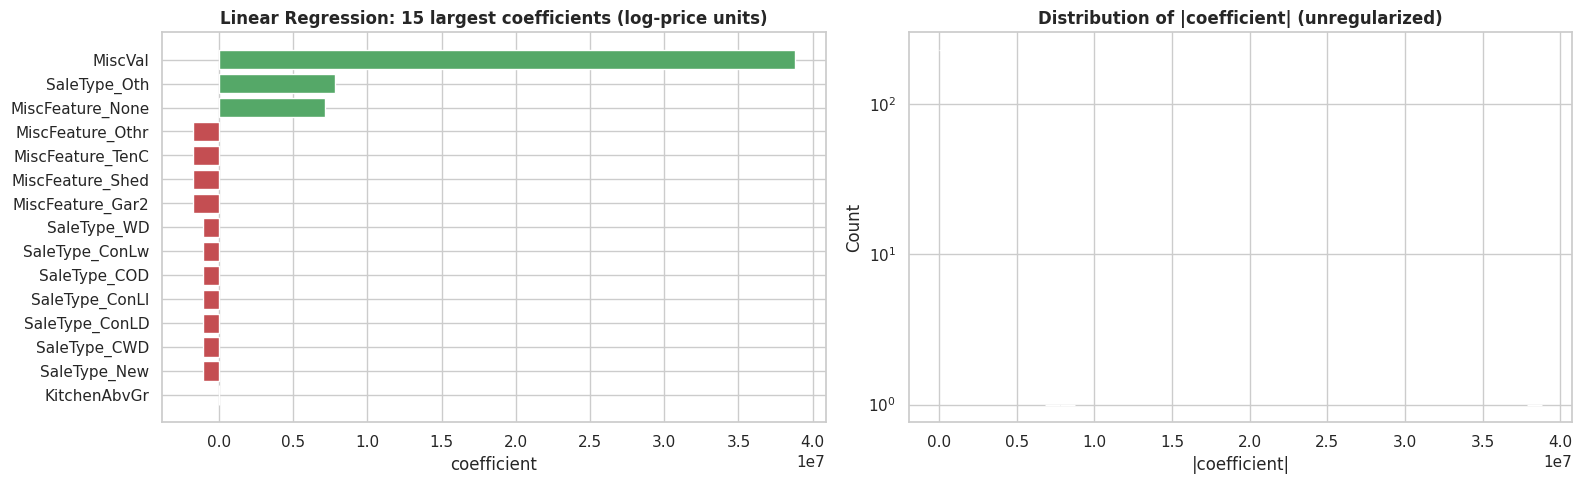

**Linear Regression:** train RMSE 0.0879 vs validation RMSE 1045721.3590 (R² 0.954 → -7331424332267.659). Largest |coefficient| = 38835372.46; 157 of 242 coefficients exceed 0.2 in log-price units, large values that come from correlated columns offsetting each other.

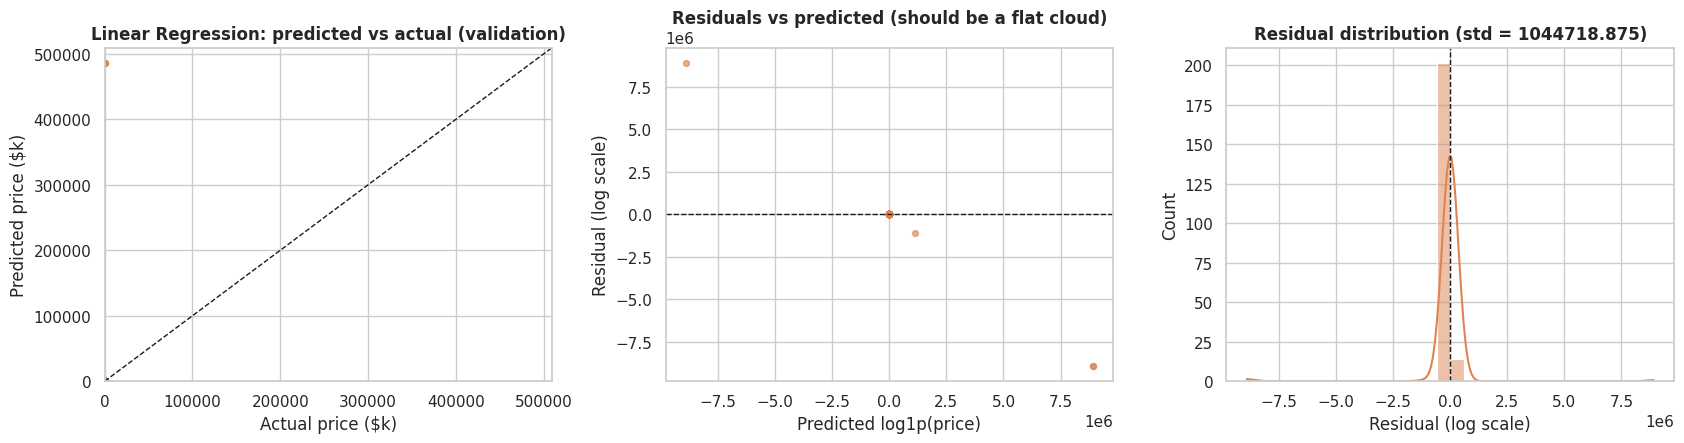

In [41]:
# ---- 7.1 Linear Regression ----
t0 = time.time()
lr_pipe = make_pipeline(LinearRegression()).fit(X_train, y_train)
BEST["Linear Regression"], FIT_SECONDS["Linear Regression"] = lr_pipe, time.time() - t0
record("Linear Regression", "tuned", lr_pipe)
COMPLEXITY["Linear Regression"] = 1

coef = pd.Series(lr_pipe.named_steps["model"].coef_, index=FEATURE_NAMES)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15])[::-1]
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].barh(top.index, top.values, color=np.where(top.values > 0, "#55a868", "#c44e52"))
ax[0].set(title="Linear Regression: 15 largest coefficients (log-price units)", xlabel="coefficient")
sns.histplot(np.abs(coef), bins=40, ax=ax[1], color="#4c72b0", log_scale=(False, True))
ax[1].set(title="Distribution of |coefficient| (unregularized)", xlabel="|coefficient|")
plt.tight_layout(); plt.show()
m = RESULTS[("Linear Regression", "tuned")]
display(Markdown(f"**Linear Regression:** train RMSE {m['train']['RMSE (log)']:.4f} vs validation RMSE {m['validation']['RMSE (log)']:.4f} "
                 f"(R² {m['train']['R² (log)']:.3f} → {m['validation']['R² (log)']:.3f}). Largest |coefficient| = {coef.abs().max():.2f}; "
                 f"{(coef.abs() > 0.2).sum()} of {len(coef)} coefficients exceed 0.2 in log-price units, large values that come from correlated columns offsetting each other."))
plot_diagnostics("Linear Regression", lr_pipe)

### 7.2 Ridge Regression

Ridge uses L2 regularization, which penalizes large coefficients. The `alpha` parameter controls the strength of this penalty. A small value has little effect, while a large value can make the model too simple. I tune `alpha` to find a suitable balance.


**Ridge** — 155 fits in 23s · best CV RMSE (log) **0.1136** (± 0.0110) · best parameters: `{'alpha': 6.81292}`

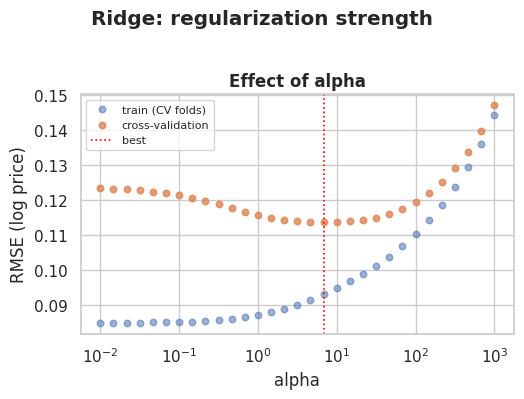

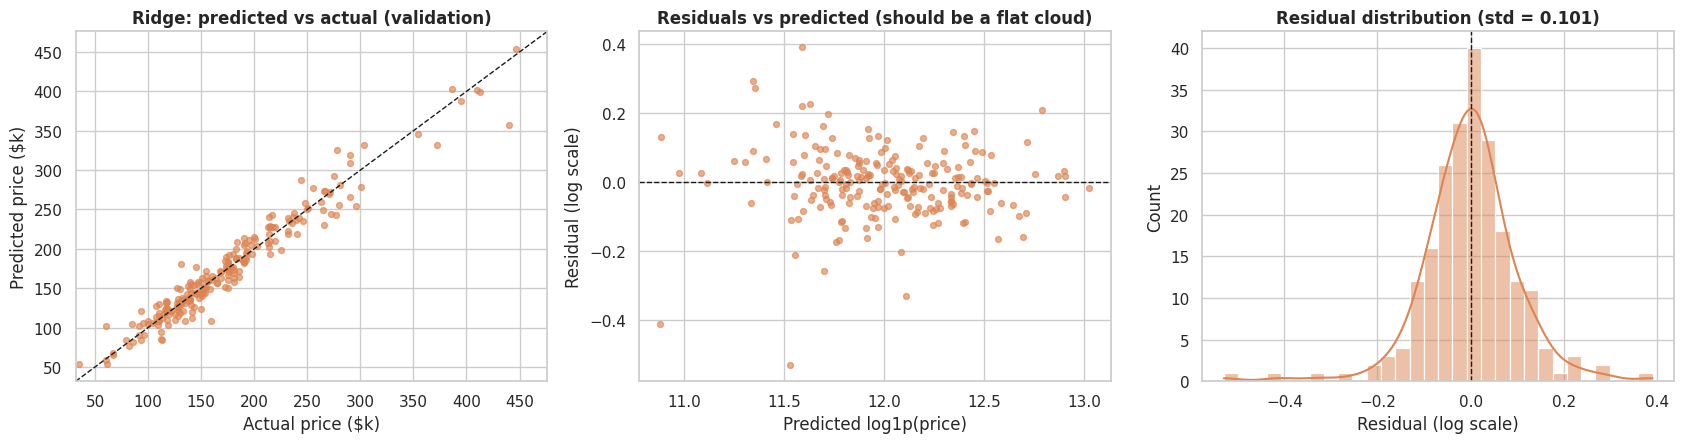

In [42]:
# ---- 7.2 Ridge ----
ridge_search = tune("Ridge", Ridge(), {"alpha": np.logspace(-2, 3, 31)}, kind="grid")
COMPLEXITY["Ridge"] = 2
plot_param_effect(ridge_search, ["alpha"], ncols=1, logx=("alpha",), suptitle="Ridge: regularization strength")
plot_diagnostics("Ridge", BEST["Ridge"])

### 7.3 Lasso Regression

Lasso uses L1 regularization. It can shrink some coefficients all the way to zero, which means that some features are not used by the model. I tune `alpha` to check how much regularization works best for this dataset.


**Lasso** — 110 fits in 28s · best CV RMSE (log) **0.1113** (± 0.0113) · best parameters: `{'alpha': 0.00046}`

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 19.65056943406125, tolerance: 14.782781625326395
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 16.01073337708059, tolerance: 14.782781625326395
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 15.141721821139129, tolerance: 14.782781625326395
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: Convergenc

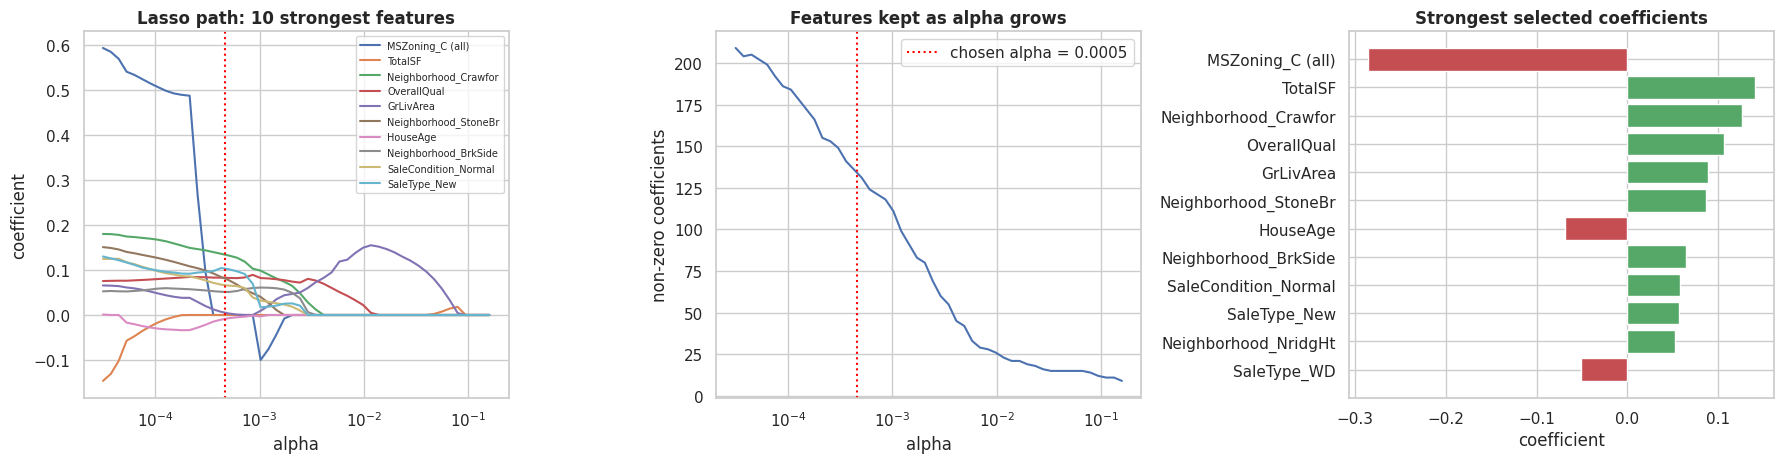

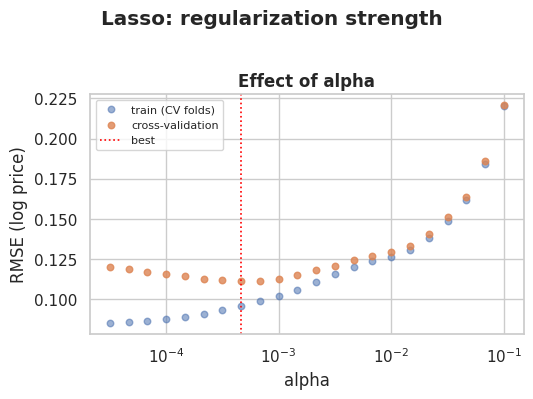

**Lasso keeps 103 of 242 features** (the other 139 are exactly zero) at the chosen `alpha = 0.00046`.

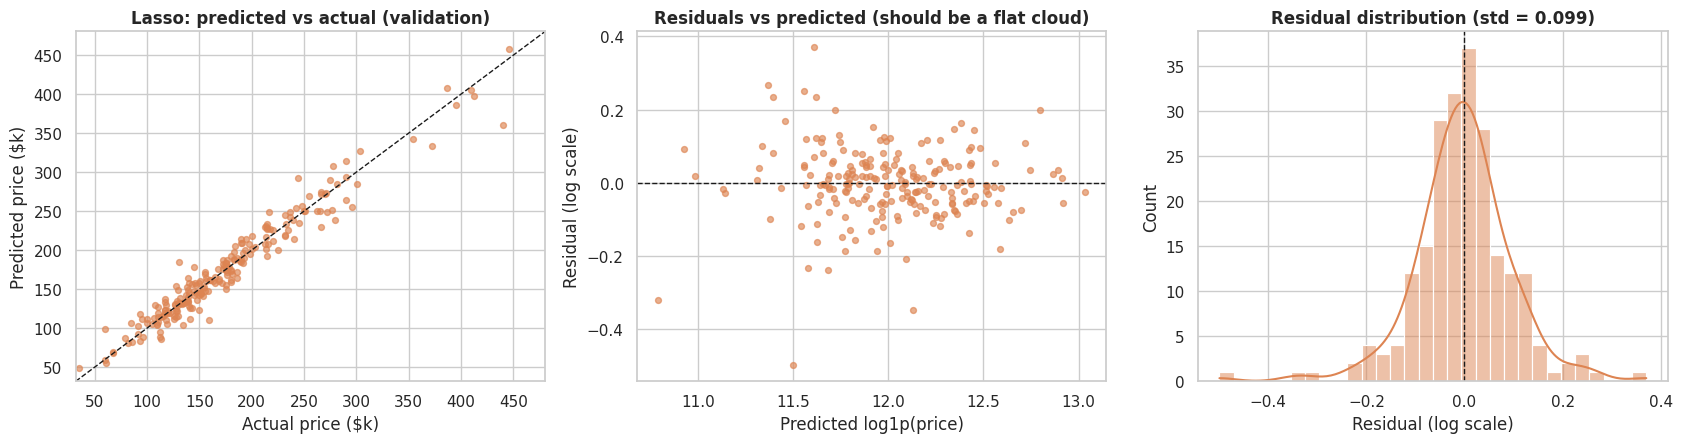

In [43]:
# ---- 7.3 Lasso ----
lasso_search = tune("Lasso", Lasso(max_iter=50000, random_state=RANDOM_STATE), {"alpha": np.logspace(-4.5, -1, 22)}, kind="grid")
COMPLEXITY["Lasso"] = 2
best_lasso = BEST["Lasso"].named_steps["model"]
n_nonzero = int((best_lasso.coef_ != 0).sum())

# regularization path on the preprocessed TRAINING data (visual only)
alphas_path, coefs_path, _ = lasso_path(Xt_tr, y_train, alphas=np.logspace(-4.5, -0.8, 50))
top_idx = np.argsort(-np.abs(best_lasso.coef_))[:10]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for i in top_idx:
    ax[0].plot(alphas_path, coefs_path[i], label=FEATURE_NAMES[i])
ax[0].axvline(best_lasso.alpha, color="red", ls=":"); ax[0].set_xscale("log")
ax[0].set(xlabel="alpha", ylabel="coefficient", title="Lasso path: 10 strongest features")
ax[0].legend(fontsize=7, loc="upper right")
ax[1].plot(alphas_path, (coefs_path != 0).sum(axis=0), color="#4c72b0"); ax[1].set_xscale("log")
ax[1].axvline(best_lasso.alpha, color="red", ls=":", label=f"chosen alpha = {best_lasso.alpha:.4f}")
ax[1].set(xlabel="alpha", ylabel="non-zero coefficients", title="Features kept as alpha grows"); ax[1].legend()
sel = pd.Series(best_lasso.coef_, index=FEATURE_NAMES); sel = sel[sel != 0]
sel = sel.reindex(sel.abs().sort_values(ascending=False).index[:12])[::-1]
ax[2].barh(sel.index, sel.values, color=np.where(sel.values > 0, "#55a868", "#c44e52"))
ax[2].set(title="Strongest selected coefficients", xlabel="coefficient")
plt.tight_layout(); plt.show()
plot_param_effect(lasso_search, ["alpha"], ncols=1, logx=("alpha",), suptitle="Lasso: regularization strength")
display(Markdown(f"**Lasso keeps {n_nonzero} of {len(best_lasso.coef_)} features** (the other {len(best_lasso.coef_) - n_nonzero} are exactly zero) at the chosen `alpha = {best_lasso.alpha:.5f}`."))
plot_diagnostics("Lasso", BEST["Lasso"])

### 7.4 Elastic Net

Elastic Net combines L1 and L2 regularization. The `alpha` parameter controls the overall penalty, while `l1_ratio` controls the balance between the two types. I tune both values to find a useful combination.


**Elastic Net** — 350 fits in 91s · best CV RMSE (log) **0.1113** (± 0.0113) · best parameters: `{'alpha': 0.00046, 'l1_ratio': 1.0}`

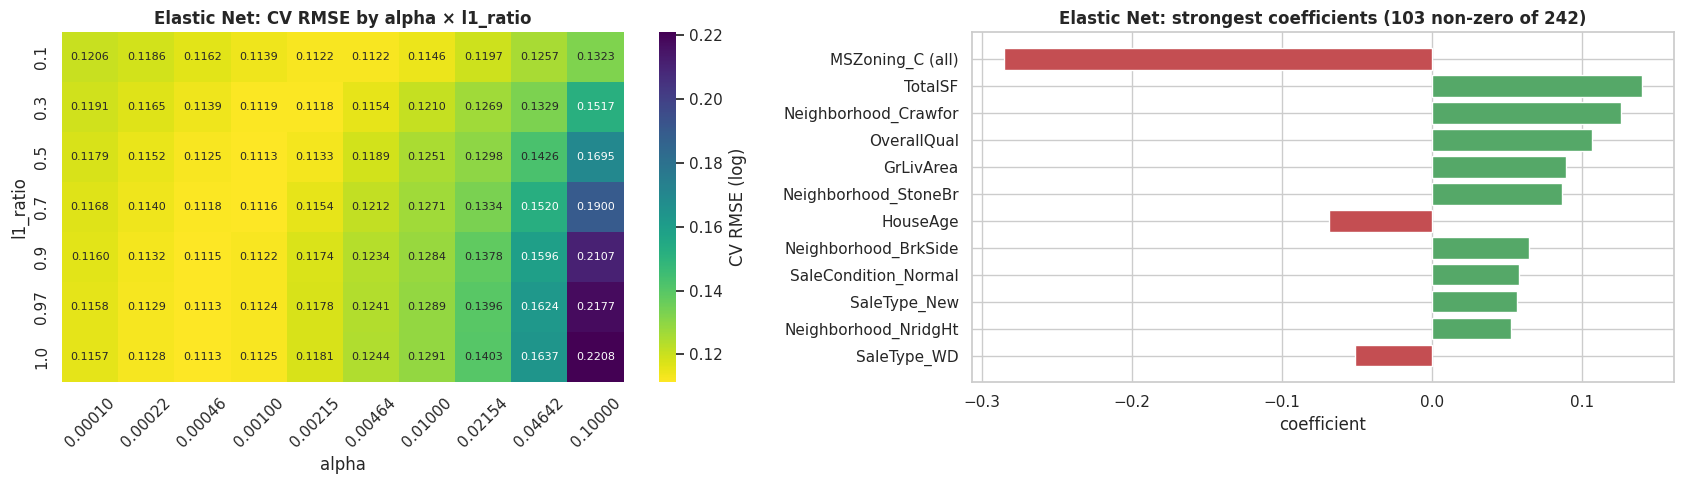

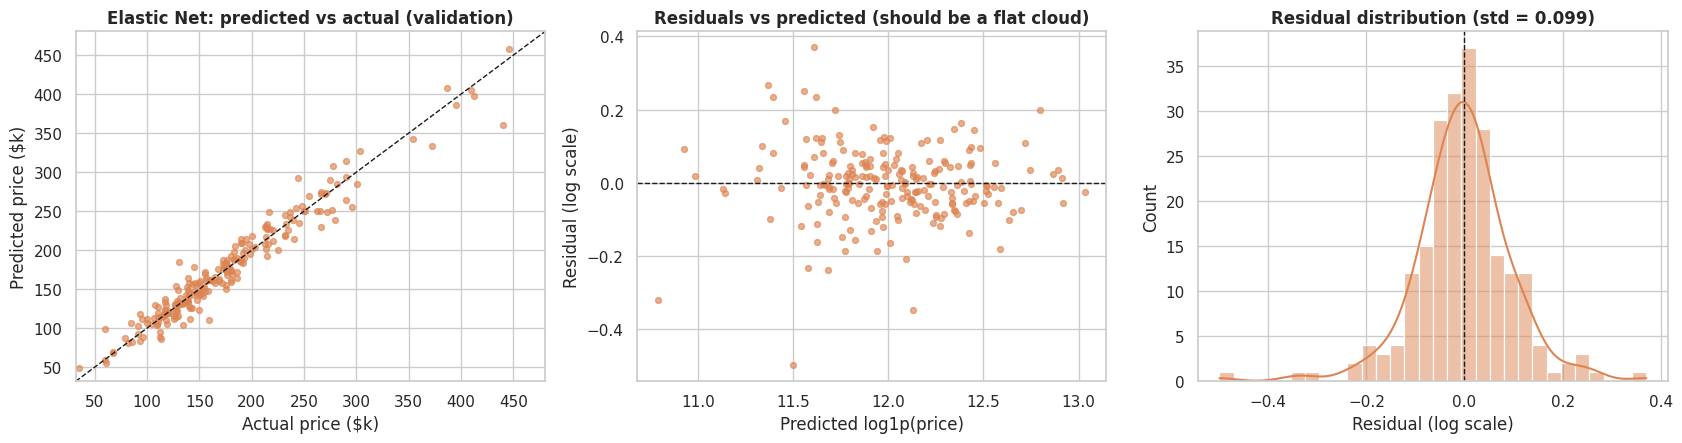

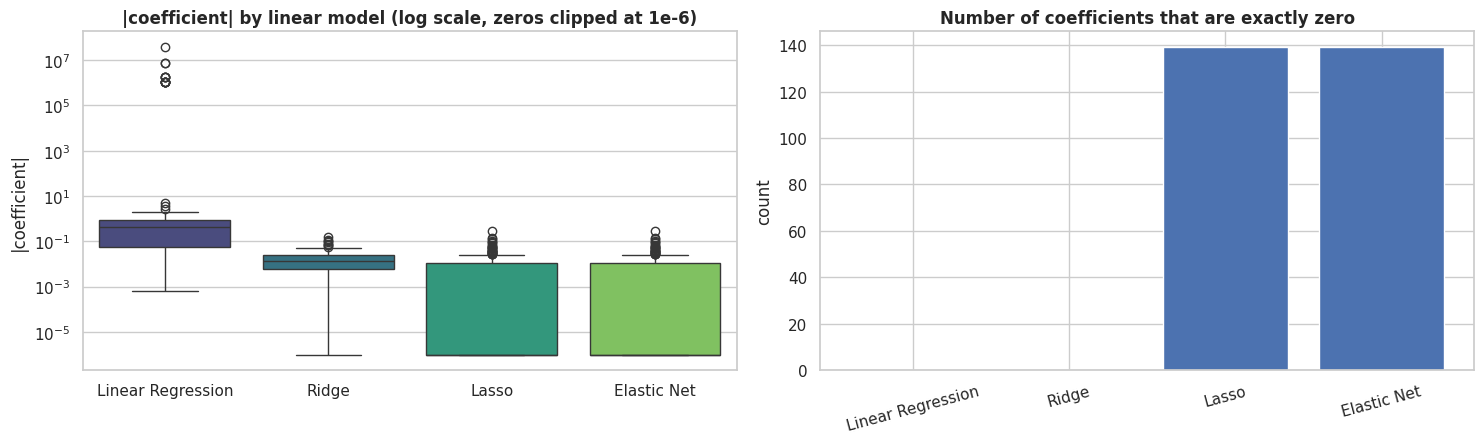

**Regularization effect on the coefficients:** the unregularized model has the widest spread and the largest coefficients; Ridge shrinks them without removing any, whereas Lasso and Elastic Net also remove features completely.

In [44]:
# ---- 7.4 Elastic Net ----
enet_grid = {"alpha": np.logspace(-4, -1, 10), "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.97, 1.0]}
enet_search = tune("Elastic Net", ElasticNet(max_iter=50000, random_state=RANDOM_STATE), enet_grid, kind="grid")
COMPLEXITY["Elastic Net"] = 3

d = search_frame(enet_search)
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
plot_heatmap(ax[0], d.assign(alpha=d["alpha"].map(lambda v: f"{v:.5f}")), "l1_ratio", "alpha",
             "Elastic Net: CV RMSE by alpha × l1_ratio", row_order=enet_grid["l1_ratio"],
             col_order=[f"{v:.5f}" for v in enet_grid["alpha"]])
ax[0].tick_params(axis="x", rotation=45)
best_enet = BEST["Elastic Net"].named_steps["model"]
k_nz = int((best_enet.coef_ != 0).sum())
tops = pd.Series(best_enet.coef_, index=FEATURE_NAMES); tops = tops.reindex(tops.abs().sort_values(ascending=False).index[:12])[::-1]
ax[1].barh(tops.index, tops.values, color=np.where(tops.values > 0, "#55a868", "#c44e52"))
ax[1].set(title=f"Elastic Net: strongest coefficients ({k_nz} non-zero of {len(best_enet.coef_)})", xlabel="coefficient")
plt.tight_layout(); plt.show()
plot_diagnostics("Elastic Net", BEST["Elastic Net"])

# --- shrinkage comparison of the four linear models ---
coef_tbl = pd.DataFrame({n: np.abs(BEST[n].named_steps["model"].coef_) for n in ["Linear Regression", "Ridge", "Lasso", "Elastic Net"]})
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
sns.boxplot(data=coef_tbl.clip(lower=1e-6), ax=ax[0], palette="viridis"); ax[0].set_yscale("log")
ax[0].set(title="|coefficient| by linear model (log scale, zeros clipped at 1e-6)", ylabel="|coefficient|")
ax[1].bar(coef_tbl.columns, (coef_tbl == 0).sum().values, color="#4c72b0")
ax[1].set(title="Number of coefficients that are exactly zero", ylabel="count"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
display(Markdown("**Regularization effect on the coefficients:** the unregularized model has the widest spread and the largest coefficients; "
                 "Ridge shrinks them without removing any, whereas Lasso and Elastic Net also remove features completely."))

# 7.5 KNN

**KNN** — 160 fits in 40s · best CV RMSE (log) **0.1614** (± 0.0075) · best parameters: `{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}`

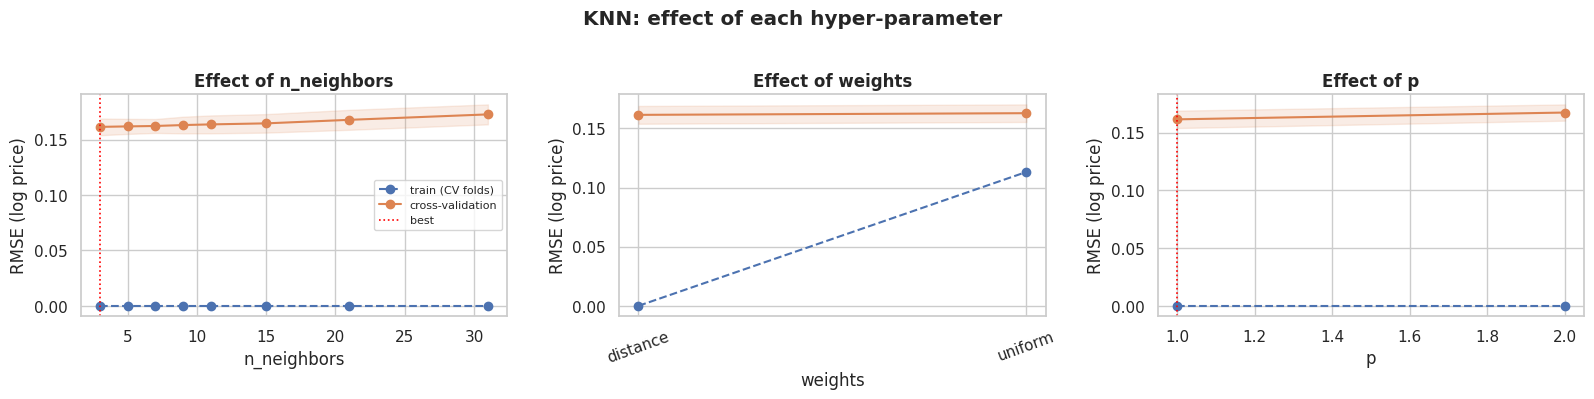

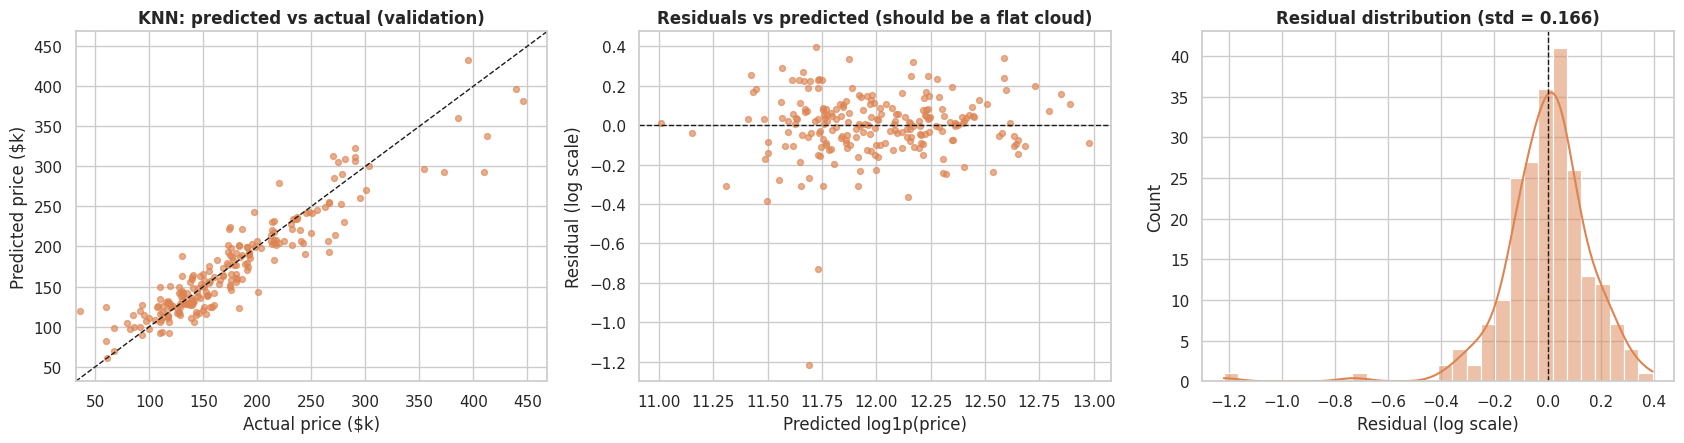

In [45]:
# ---- 7.5 KNN ----
knn_grid = {"n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "weights": ["uniform", "distance"], "p": [1, 2]}
knn_search = tune("KNN", KNeighborsRegressor(), knn_grid, kind="grid")
COMPLEXITY["KNN"] = 3
plot_param_effect(knn_search, ["n_neighbors", "weights", "p"], ncols=3, suptitle="KNN: effect of each hyper-parameter")
plot_diagnostics("KNN", BEST["KNN"])

### 7.6 Support Vector Regression (SVR)

SVR tries to fit predictions within an `epsilon`-wide margin around the target values. Errors outside this margin are penalized.

| Parameter | Meaning |
|---|---|
| `C` | Controls how strongly errors are penalized. |
| `kernel` | Defines the type of relationship the model can learn, such as `rbf` or `poly`. |
| `gamma` | Controls how far the influence of each training example reaches for applicable kernels. |
| `degree` | Sets the polynomial degree when using the `poly` kernel. |
| `epsilon` | Sets the width of the margin where errors are not penalized. |

I first run the main grid for the `rbf` and `poly` kernels. If the best result uses `rbf`, I run a second search with a smaller range around the best settings. Both searches use cross-validation on the training set.


In [46]:
# ---- 7.6 SVR, stage 1: the assignment grid ----

epsilon_values = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]

svr_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10, 100],
        "epsilon": epsilon_values
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.01, 0.001],
        "epsilon": epsilon_values
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.01, 0.001],
        "degree": [2, 3],
        "epsilon": epsilon_values
    },
    {
        "kernel": ["sigmoid"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.01, 0.001],
        "epsilon": epsilon_values
    }
]

if QUICK_RUN:
    svr_grid = [
        {
            "kernel": ["linear"],
            "C": [1, 10],
            "epsilon": [0.1, 0.3, 0.5, 1.0]
        },
        {
            "kernel": ["rbf"],
            "C": [1, 10],
            "gamma": ["scale", 0.01],
            "epsilon": [0.1, 0.3, 0.5, 1.0]
        },
        {
            "kernel": ["poly"],
            "C": [1],
            "gamma": ["scale"],
            "degree": [2],
            "epsilon": [0.1, 0.3, 0.5, 1.0]
        },
        {
            "kernel": ["sigmoid"],
            "C": [1],
            "gamma": ["scale"],
            "epsilon": [0.1, 0.3, 0.5, 1.0]
        }
    ]

svr_s1 = tune(
    "SVR",
    SVR(cache_size=500, max_iter=300000),
    svr_grid,
    kind="grid"
)

svr_stage1 = svr_s1

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


**SVR** — 2720 fits in 836s · best CV RMSE (log) **0.1109** (± 0.0115) · best parameters: `{'C': 10, 'epsilon': 0.05, 'gamma': 0.001, 'kernel': 'rbf'}`

In [47]:
# ---- 7.6 SVR, stage 2: finer search around the best rbf configuration ----
n_feat = Xt_tr.shape[1]
gamma_scale = 1.0 / (n_feat * Xt_tr.var())          # what gamma="scale" means for this data
gamma_auto  = 1.0 / n_feat                           # what gamma="auto" means
bp = svr_stage1.best_params_
print(f"Stage-1 winner: {({k.replace('model__', ''): py(v) for k, v in bp.items()})}")

if bp["model__kernel"] == "rbf":
    g0 = {"scale": gamma_scale, "auto": gamma_auto}.get(bp["model__gamma"], bp["model__gamma"])
    refine = {"kernel": ["rbf"],
              "C": list(np.round(bp["model__C"] * np.array([0.25, 0.5, 1, 2, 4, 8]), 4)),
              "gamma": list(np.round(g0 * np.array([0.25, 0.5, 1, 2, 4]), 6)),
              "epsilon": [0.005, 0.01, 0.03, 0.05, 0.1]}
    if QUICK_RUN:
        refine = {"kernel": ["rbf"], "C": [bp["model__C"]], "gamma": [g0], "epsilon": [0.05, 0.1]}
    svr_s2 = tune("SVR (refined)", SVR(cache_size=500, max_iter=300000), refine, kind="grid")
    use_refined = -svr_s2.best_score_ < -svr_stage1.best_score_
    print(f"Stage-2 CV RMSE {-svr_s2.best_score_:.4f} vs stage-1 {-svr_stage1.best_score_:.4f} -> keep {'refined' if use_refined else 'stage-1'} model")
    if use_refined:
        BEST["SVR"], SEARCH["SVR"] = BEST["SVR (refined)"], svr_s2
        RESULTS[("SVR", "tuned")] = RESULTS[("SVR (refined)", "tuned")]
    # the helper entries are not separate models
    for reg in (RESULTS, BEST, SEARCH, FIT_SECONDS):
        for key in [k for k in reg if (k[0] if isinstance(k, tuple) else k) == "SVR (refined)"]:
            reg.pop(key)
else:
    svr_s2, use_refined = None, False
    print("Winner is a poly kernel -> no rbf refinement.")
COMPLEXITY["SVR"] = 4

Stage-1 winner: {'C': 10, 'epsilon': 0.05, 'gamma': 0.001, 'kernel': 'rbf'}


**SVR (refined)** — 750 fits in 197s · best CV RMSE (log) **0.1102** (± 0.0122) · best parameters: `{'C': 40.0, 'epsilon': 0.03, 'gamma': 0.0005, 'kernel': 'rbf'}`

Stage-2 CV RMSE 0.1102 vs stage-1 0.1109 -> keep refined model


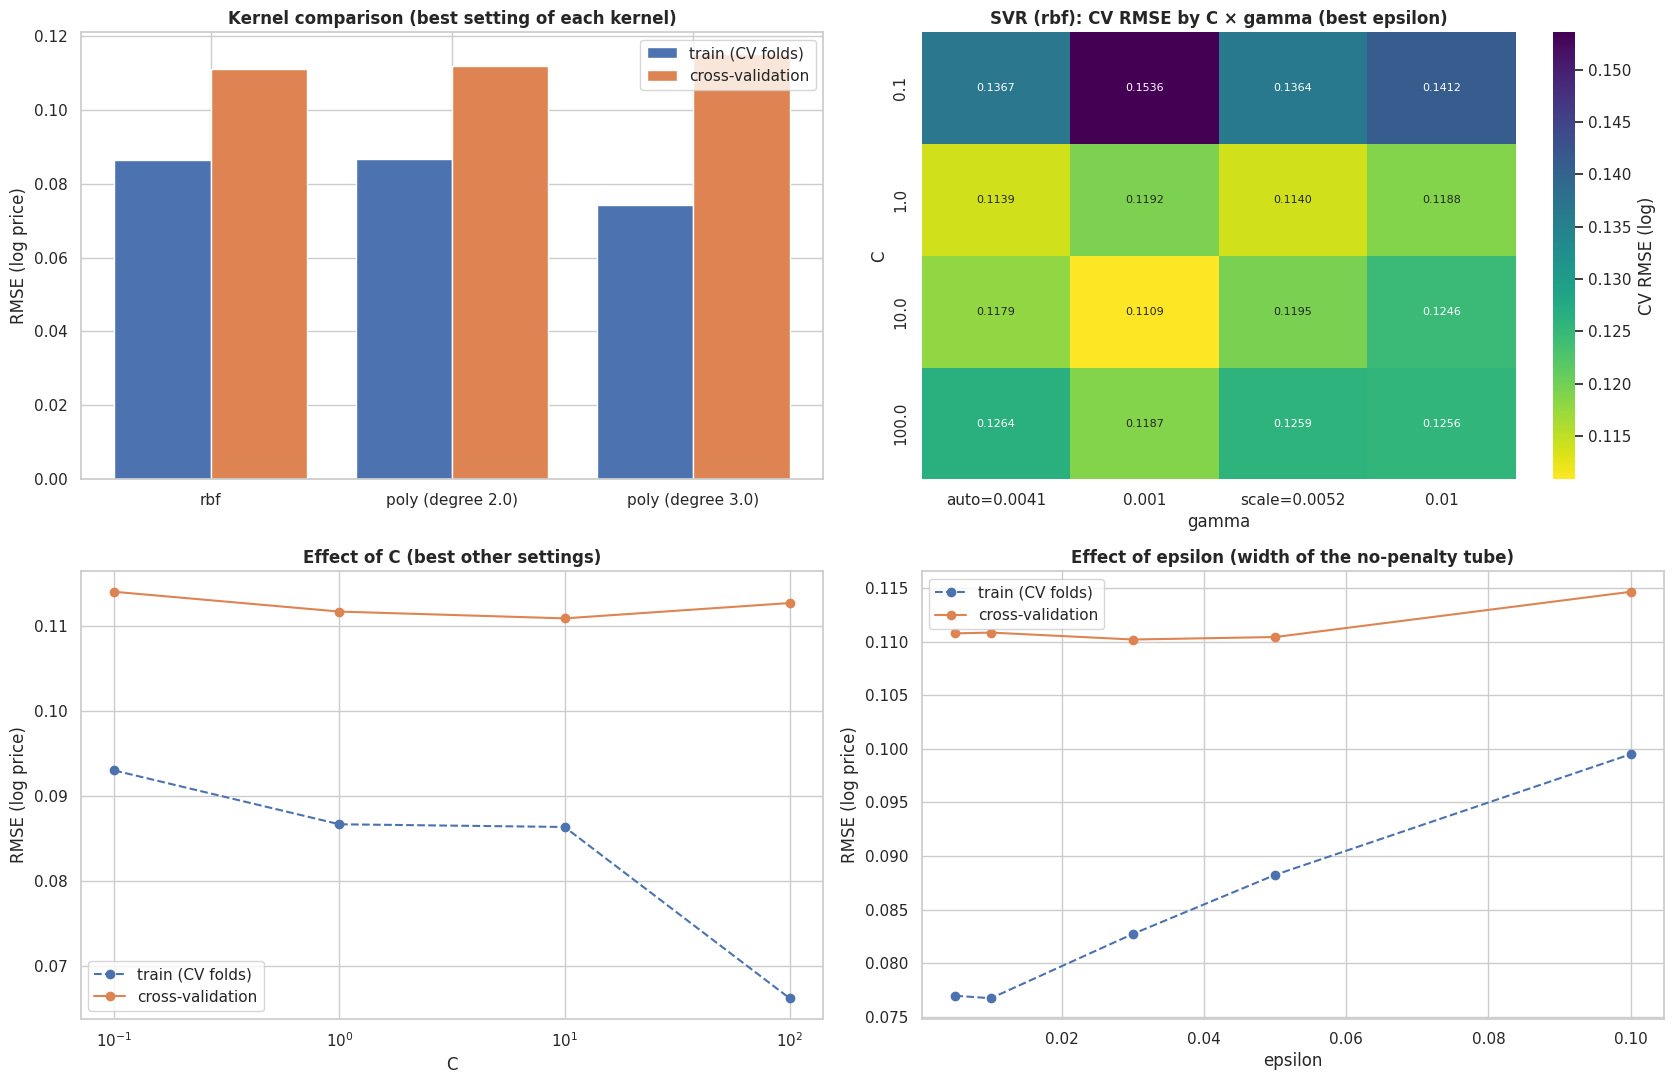

**SVR final configuration:** `{'C': 40.0, 'epsilon': 0.03, 'gamma': 0.0005, 'kernel': 'rbf'}`. The model uses **710 support vectors = 70% of the training houses**; the remaining houses lie inside the ε-tube and do not influence the fit.

**Kernel result:** best `rbf` CV RMSE = 0.1109; best `poly` CV RMSE = 0.1117 -> **rbf** wins on this data.

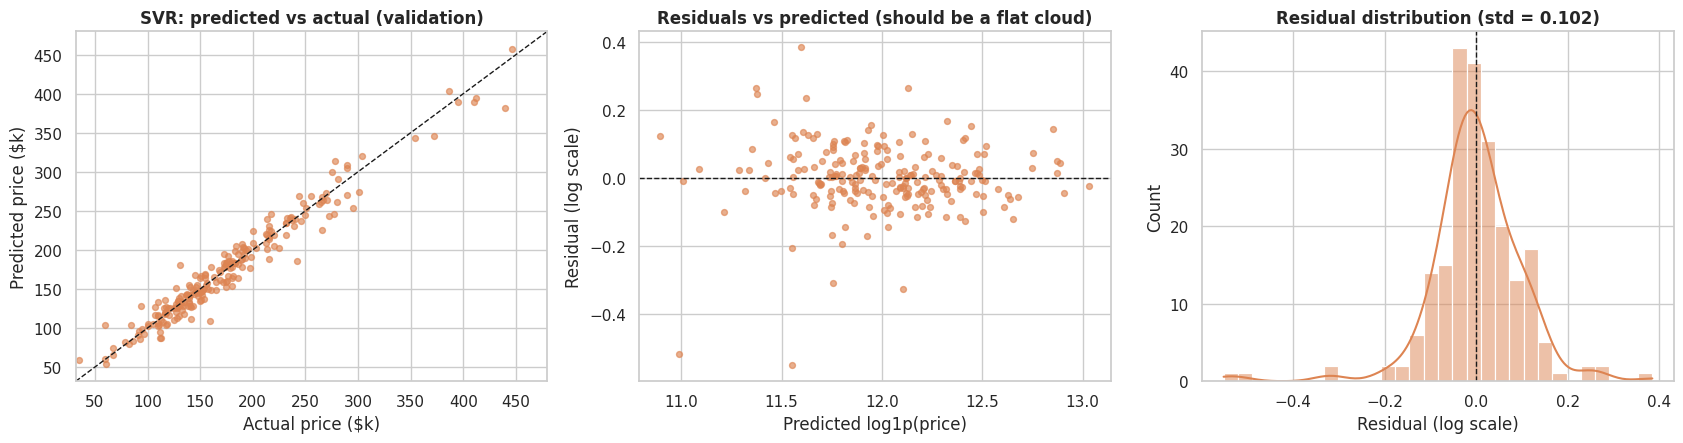

In [48]:
# ---- 7.6 SVR, visuals: kernel comparison, C × gamma heat-map, epsilon, support vectors ----
d1 = search_frame(svr_stage1)
def gamma_label(g):
    return f"scale={gamma_scale:.4f}" if g == "scale" else (f"auto={gamma_auto:.4f}" if g == "auto" else f"{float(g):g}")
d1["gamma_lbl"] = d1["gamma"].map(gamma_label)
gamma_order = sorted(d1["gamma_lbl"].unique(), key=lambda s: float(s.split("=")[-1]))

fig, ax = plt.subplots(2, 2, figsize=(17, 11))
# (a) best CV RMSE per kernel / degree
d1["kernel_lbl"] = np.where(d1["kernel"] == "poly", "poly (degree " + d1["degree"].astype(str) + ")", "rbf")
kern = d1.groupby("kernel_lbl")[["cv_rmse", "train_rmse"]].min().sort_values("cv_rmse")
kern_cv = d1.loc[d1.groupby("kernel_lbl")["cv_rmse"].idxmin()].set_index("kernel_lbl").loc[kern.index]
xk = np.arange(len(kern_cv)); ax[0, 0].bar(xk - .2, kern_cv["train_rmse"], .4, color=SET_COLORS["train"], label="train (CV folds)")
ax[0, 0].bar(xk + .2, kern_cv["cv_rmse"], .4, color=SET_COLORS["validation"], label="cross-validation")
ax[0, 0].set_xticks(xk); ax[0, 0].set_xticklabels(kern_cv.index)
ax[0, 0].set(title="Kernel comparison (best setting of each kernel)", ylabel="RMSE (log price)"); ax[0, 0].legend()
# (b) C × gamma heat-map (rbf, best epsilon)
rbf = d1[d1["kernel"] == "rbf"]
plot_heatmap(ax[0, 1], rbf.assign(gamma=rbf["gamma_lbl"]), "C", "gamma", "SVR (rbf): CV RMSE by C × gamma (best epsilon)", col_order=gamma_order)
# (c) C effect, train vs CV
bestC = d1.loc[d1.groupby(d1["C"].astype(float))["cv_rmse"].idxmin()].sort_values("C")
ax[1, 0].plot(bestC["C"].astype(float), bestC["train_rmse"], "o--", color=SET_COLORS["train"], label="train (CV folds)")
ax[1, 0].plot(bestC["C"].astype(float), bestC["cv_rmse"], "o-", color=SET_COLORS["validation"], label="cross-validation")
ax[1, 0].set_xscale("log"); ax[1, 0].set(xlabel="C", ylabel="RMSE (log price)", title="Effect of C (best other settings)"); ax[1, 0].legend()
# (d) epsilon effect (stage 2 if available, otherwise stage 1)
src = search_frame(svr_s2) if svr_s2 is not None else rbf
eps = src.loc[src.groupby(src["epsilon"].astype(float))["cv_rmse"].idxmin()].sort_values("epsilon")
ax[1, 1].plot(eps["epsilon"].astype(float), eps["train_rmse"], "o--", color=SET_COLORS["train"], label="train (CV folds)")
ax[1, 1].plot(eps["epsilon"].astype(float), eps["cv_rmse"], "o-", color=SET_COLORS["validation"], label="cross-validation")
ax[1, 1].set(xlabel="epsilon", ylabel="RMSE (log price)", title="Effect of epsilon (width of the no-penalty tube)"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

svr_final = BEST["SVR"].named_steps["model"]
n_sv = len(svr_final.support_)
bp_final = {k.replace("model__", ""): py(v) for k, v in SEARCH["SVR"].best_params_.items()}
display(Markdown(f"**SVR final configuration:** `{bp_final}`. The model uses **{n_sv} support vectors = {n_sv / len(X_train):.0%} of the training houses**; "
                 f"the remaining houses lie inside the ε-tube and do not influence the fit."))
if (d1["kernel"] == "poly").any():
    pb, rb = d1[d1["kernel"] == "poly"]["cv_rmse"].min(), d1[d1["kernel"] == "rbf"]["cv_rmse"].min()
    display(Markdown(f"**Kernel result:** best `rbf` CV RMSE = {rb:.4f}; best `poly` CV RMSE = {pb:.4f} -> "
                     f"**{'rbf' if rb <= pb else 'poly'}** wins on this data."))
plot_diagnostics("SVR", BEST["SVR"])

### 7.7 Random Forest

Random Forest trains multiple decision trees and averages their predictions. This usually makes the result more stable than relying on one tree. I tune settings such as tree depth, minimum samples per leaf, and the number of features considered at each split to control model complexity.


**Random Forest** — 120 fits in 183s · best CV RMSE (log) **0.1349** (± 0.0046) · best parameters: `{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': 18}`

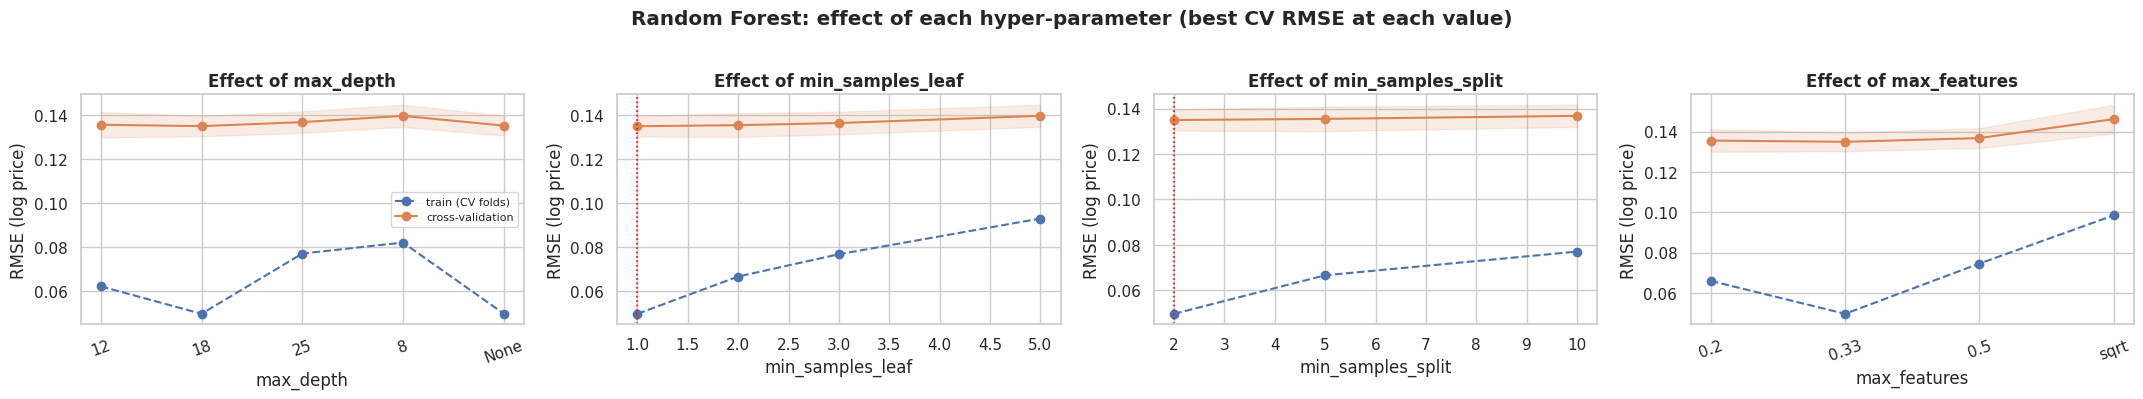

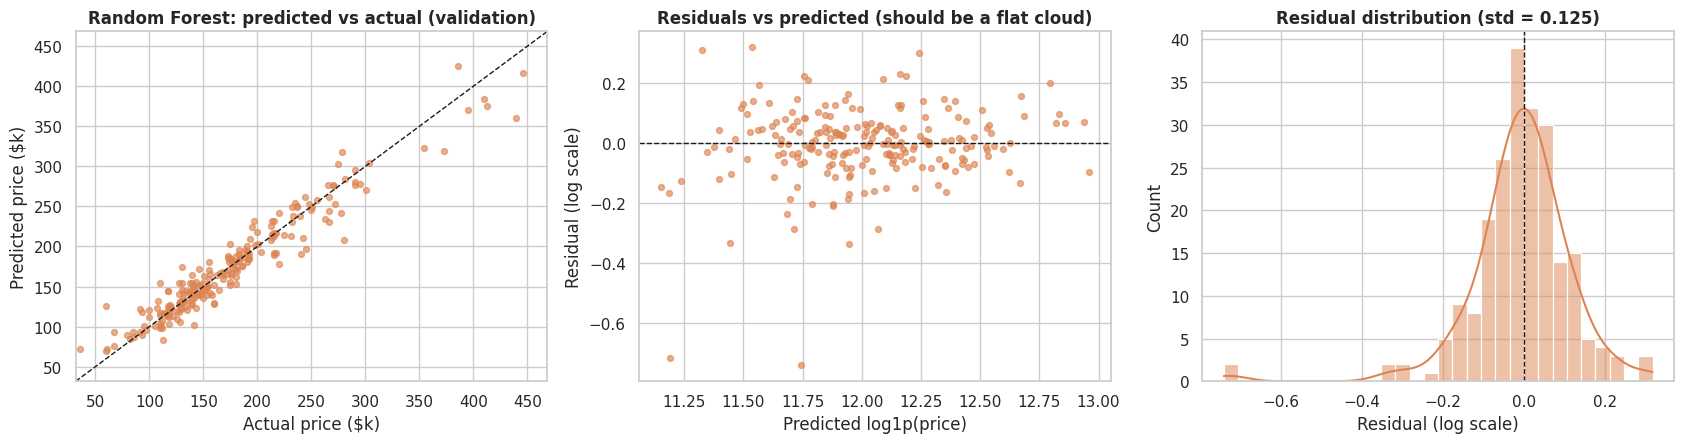

In [49]:
# ---- 7.7 Random Forest ----
rf_space = {"n_estimators": [300], "max_depth": [None, 8, 12, 18, 25], "min_samples_leaf": [1, 2, 3, 5],
            "min_samples_split": [2, 5, 10], "max_features": ["sqrt", 0.2, 0.33, 0.5]}
rf_search = tune("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), rf_space,
                 kind="random", n_iter=4 if QUICK_RUN else 24)
COMPLEXITY["Random Forest"] = 5
plot_param_effect(rf_search, ["max_depth", "min_samples_leaf", "min_samples_split", "max_features"], ncols=4,
                  suptitle="Random Forest: effect of each hyper-parameter (best CV RMSE at each value)")
plot_diagnostics("Random Forest", BEST["Random Forest"])

### 7.8 Gradient Boosting

Gradient Boosting builds trees one after another. Each new tree tries to improve the predictions made by the previous trees. I tune the learning rate, number of trees, tree depth and other settings to find a balance between fitting the training data and performing well on unseen data.


**Gradient Boosting** — 120 fits in 166s · best CV RMSE (log) **0.1184** (± 0.0067) · best parameters: `{'subsample': 0.6, 'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 4, 'learning_rate': 0.02}`

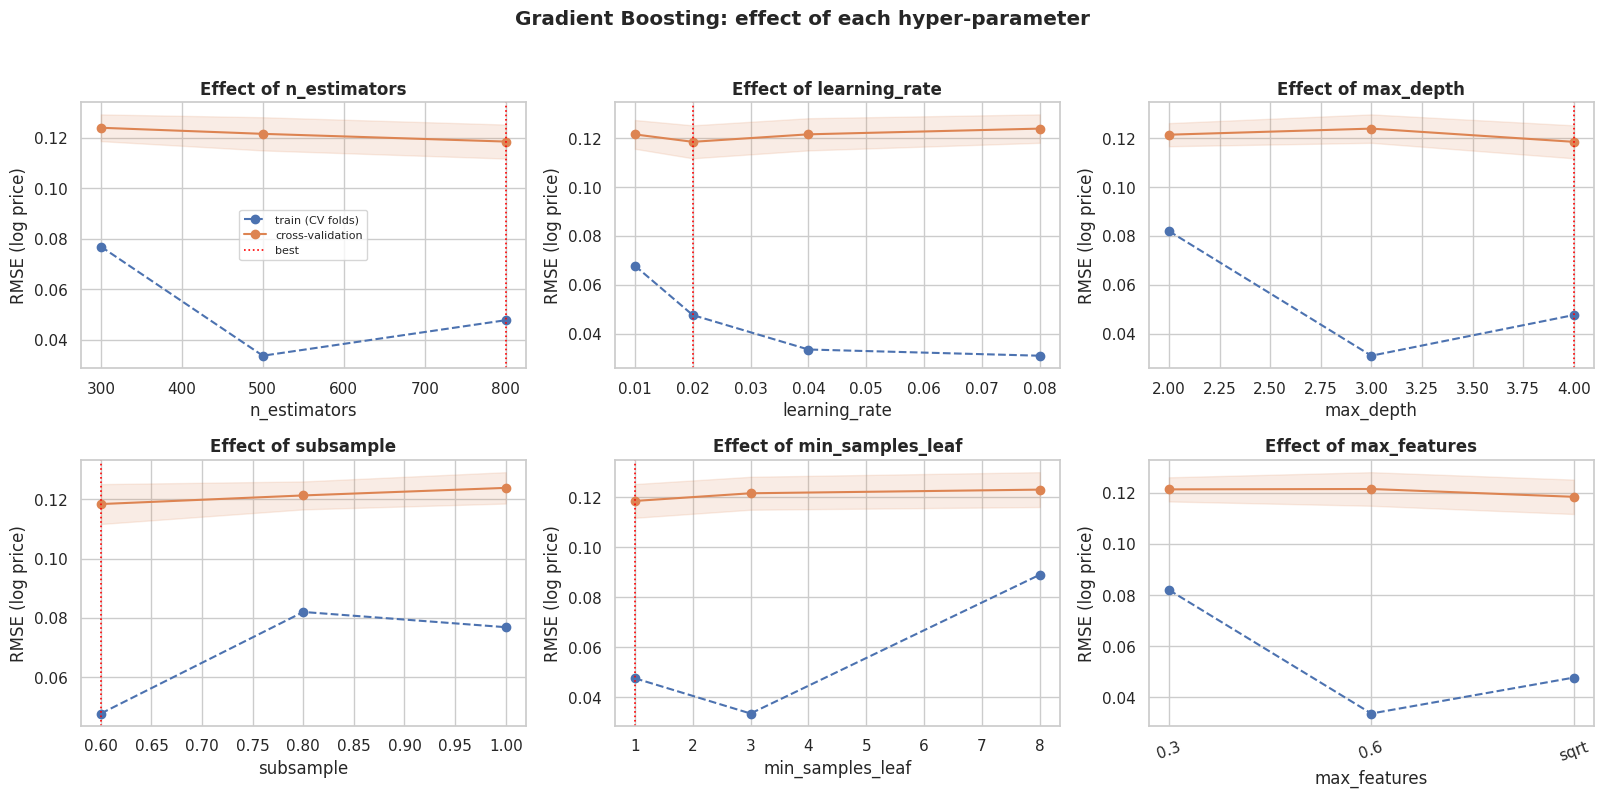

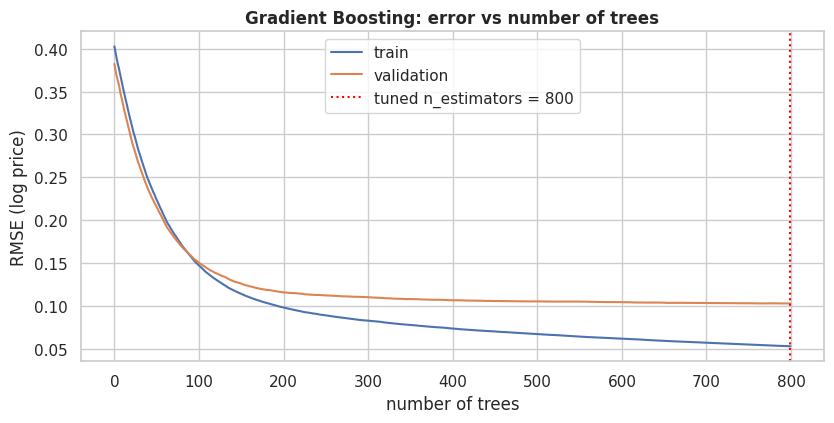

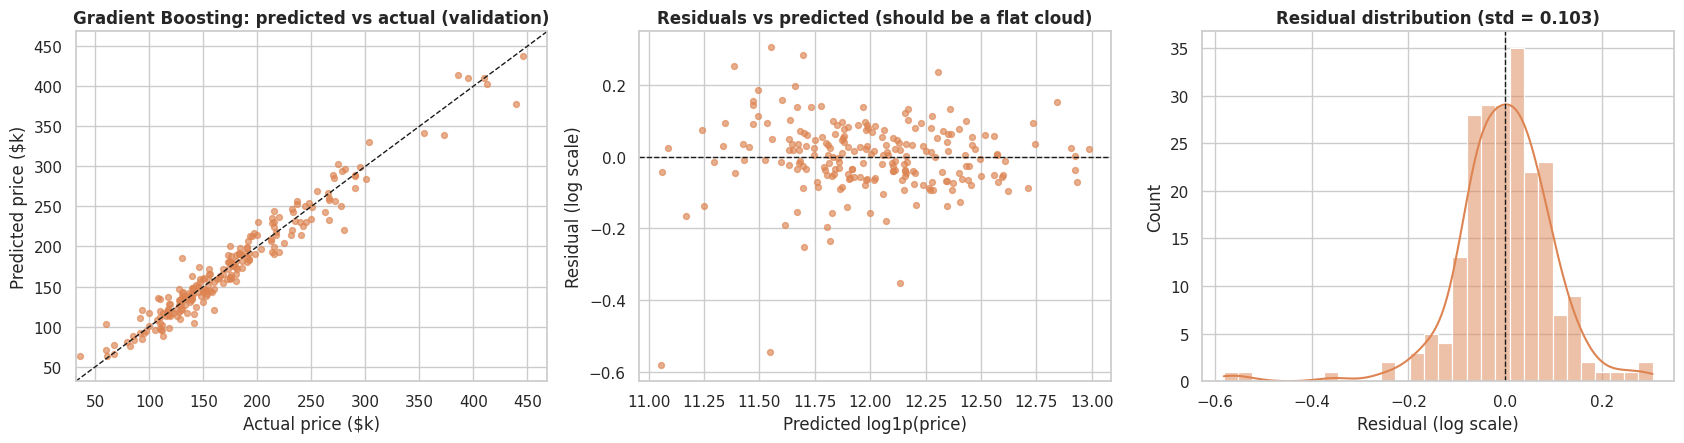

In [50]:
# ---- 7.8 Gradient Boosting ----
gb_space = {"n_estimators": [300, 500, 800], "learning_rate": [0.01, 0.02, 0.04, 0.08], "max_depth": [2, 3, 4],
            "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 3, 8], "max_features": ["sqrt", 0.3, 0.6]}
gb_search = tune("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE), gb_space,
                 kind="random", n_iter=4 if QUICK_RUN else 24)
COMPLEXITY["Gradient Boosting"] = 5
plot_param_effect(gb_search, ["n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf", "max_features"], ncols=3,
                  suptitle="Gradient Boosting: effect of each hyper-parameter")

# learning curve over the number of trees (preprocessed matrices; diagnostic only)
gb_best = clone(BEST["Gradient Boosting"].named_steps["model"]).fit(Xt_tr, y_train)
tr_curve = [np.sqrt(mean_squared_error(y_train, p)) for p in gb_best.staged_predict(Xt_tr)]
va_curve = [np.sqrt(mean_squared_error(y_val, p)) for p in gb_best.staged_predict(Xt_va)]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(tr_curve, color=SET_COLORS["train"], label="train"); ax.plot(va_curve, color=SET_COLORS["validation"], label="validation")
ax.axvline(len(tr_curve) - 1, color="red", ls=":", label=f"tuned n_estimators = {len(tr_curve)}")
ax.set(xlabel="number of trees", ylabel="RMSE (log price)", title="Gradient Boosting: error vs number of trees"); ax.legend()
plt.tight_layout(); plt.show()
plot_diagnostics("Gradient Boosting", BEST["Gradient Boosting"])

### 7.9 Tuning summary

The table below collects the best settings and search information for the models that were tuned.


In [51]:
# ---- 7.9 Best hyper-parameters of every tuned model ----
rows = []
for name, s in SEARCH.items():
    rows.append({"model": name, "search": type(s).__name__, "fits": len(s.cv_results_["params"]) * CV.get_n_splits(),
                 "best CV RMSE (log)": -s.best_score_, "CV std": s.cv_results_["std_test_score"][s.best_index_],
                 "seconds": FIT_SECONDS[name],
                 "best parameters": {k.replace("model__", ""): py(v) for k, v in s.best_params_.items()}})
tuning_summary = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.max_colwidth", 140):
    display(tuning_summary.round(4))

,search,fits,best CV RMSE (log),CV std,seconds,best parameters
model,,,,,,
Ridge,GridSearchCV,155,0.1136,0.0110,22.5379,{'alpha': 6.81292}
Lasso,GridSearchCV,110,0.1113,0.0113,27.6797,{'alpha': 0.00046}
Elastic Net,GridSearchCV,350,0.1113,0.0113,91.2899,"{'alpha': 0.00046, 'l1_ratio': 1.0}"
KNN,GridSearchCV,160,0.1614,0.0075,39.6052,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}"
SVR,GridSearchCV,750,0.1102,0.0122,835.5122,"{'C': 40.0, 'epsilon': 0.03, 'gamma': 0.0005, 'kernel': 'rbf'}"
Random Forest,RandomizedSearchCV,120,0.1349,0.0046,183.4943,"{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': 18}"
Gradient Boosting,RandomizedSearchCV,120,0.1184,0.0067,165.7816,"{'subsample': 0.6, 'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 4, 'learning_rate': 0.02}"


### 7.10 Optuna: guided hyperparameter optimization

Optuna is an additional experiment, not a replacement for the existing `GridSearchCV` and `RandomizedSearchCV` runs. Its Tree-structured Parzen Estimator (TPE) sampler uses results from previous trials to suggest promising next configurations. Unlike a fixed grid, the search below includes continuous ranges for values such as `max_samples` and `max_features`.

To keep the comparison fair, each trial uses the same 5-fold cross-validation, the same training data, the same preprocessing pipeline, and the same log-scale RMSE objective. The validation and test sets are not used to choose trial parameters. Optuna's Random Forest is added as a separate candidate in the model comparison.

**Runtime note:** Optuna does not automatically make scikit-learn Random Forest run on a GPU. This experiment uses CPU-based scikit-learn. `QUICK_RUN` controls the number of Optuna trials for a faster test.


  0%|          | 0/20 [00:00<?, ?it/s]

,sampler,trials,best CV RMSE (log),seconds,best parameters
model,,,,,
Optuna Random Forest,Tree-structured Parzen Estimator (TPE),20,0.1336,314.7007,"{'n_estimators': 350, 'max_depth': None, 'min_..."


,number,value,params_bootstrap,params_max_depth,params_max_features,params_min_samples_leaf,params_min_samples_split,params_n_estimators,state
18,18,0.1336,False,NaN,0.2017,2,6,350,COMPLETE
14,14,0.1339,False,35.0000,0.2777,1,7,400,COMPLETE
12,12,0.1339,False,25.0000,0.2776,1,7,400,COMPLETE
15,15,0.1339,False,35.0000,0.2579,1,4,450,COMPLETE
13,13,0.1355,False,25.0000,0.3654,1,8,350,COMPLETE
1,1,0.1359,False,25.0000,0.3116,4,5,450,COMPLETE
17,17,0.1361,True,35.0000,0.2041,1,7,300,COMPLETE
11,11,0.1363,False,25.0000,0.2147,3,11,450,COMPLETE
19,19,0.1369,False,8.0000,0.2294,2,4,350,COMPLETE
10,10,0.1380,False,25.0000,0.4524,3,10,500,COMPLETE


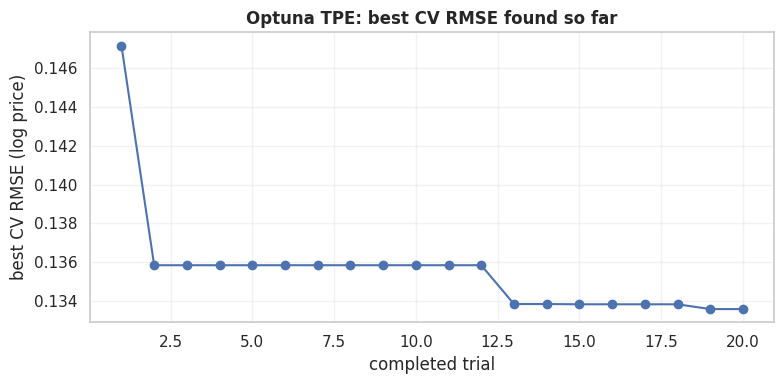

**Optuna result:** best CV RMSE (log) = **0.1336** after **20 trials** (314.7 seconds). This is the best configuration found during these trials, not a guarantee of the global optimum.

In [52]:
# ---- 7.10 Optuna hyperparameter optimization ----
# Install Optuna only if it is not already available in the current runtime.

import optuna
from sklearn.model_selection import cross_val_score

# Keep Optuna's log output concise so the notebook focuses on the results.
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Use fewer trials for a quick smoke test and more trials for the full experiment.
OPTUNA_TRIALS = 3 if QUICK_RUN else 20
OPTUNA_MODEL_NAME = "Optuna Random Forest"

def optuna_objective(trial):
    """Return mean 5-fold CV RMSE for one Random Forest configuration."""
    # Suggest both integer and continuous hyperparameters.
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 500, step=50),
        "max_depth": trial.suggest_categorical("max_depth", [None, 8, 12, 18, 25, 35]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 6),
        "max_features": trial.suggest_float("max_features", 0.2, 1.0),
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
    }

    # Rebuild the complete preprocessing/model pipeline for every trial.
    # This ensures that preprocessing is learned only from each CV training fold.
    candidate = make_pipeline(RandomForestRegressor(
        **params, random_state=RANDOM_STATE, n_jobs=1
    ))

    # The scorer is negative RMSE, so negate its mean to minimize a positive RMSE.
    fold_scores = cross_val_score(
        candidate, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1
    )
    return float(-fold_scores.mean())

# TPE learns from completed trials and proposes promising configurations.
# A fixed seed makes the sampling reproducible for this notebook.
optuna_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    study_name="ames_random_forest_tuning"
)

t0 = time.time()
optuna_study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
optuna_seconds = time.time() - t0

# Refit the best configuration on the full training set, then evaluate it on the same splits.
optuna_best_pipeline = make_pipeline(RandomForestRegressor(
    **optuna_study.best_params, random_state=RANDOM_STATE, n_jobs=-1
))
optuna_best_pipeline.fit(X_train, y_train)
BEST[OPTUNA_MODEL_NAME] = optuna_best_pipeline
FIT_SECONDS[OPTUNA_MODEL_NAME] = optuna_seconds
COMPLEXITY[OPTUNA_MODEL_NAME] = 5
record(OPTUNA_MODEL_NAME, "tuned", optuna_best_pipeline)

# Use the existing Random Forest baseline as the baseline reference for this tuned variant.
# The default metrics are copied under a distinct name so the comparison tables remain complete.
RESULTS[(OPTUNA_MODEL_NAME, "default")] = RESULTS[("Random Forest", "default")]

optuna_trials = optuna_study.trials_dataframe(attrs=("number", "value", "params", "state"))
optuna_trials.to_csv("optuna_random_forest_trials.csv", index=False)

# Display the best configuration and a compact summary of the search.
optuna_summary = pd.DataFrame([{
    "model": OPTUNA_MODEL_NAME,
    "sampler": "Tree-structured Parzen Estimator (TPE)",
    "trials": len(optuna_study.trials),
    "best CV RMSE (log)": optuna_study.best_value,
    "seconds": optuna_seconds,
    "best parameters": optuna_study.best_params,
}]).set_index("model")
display(optuna_summary)
display(optuna_trials.sort_values("value").head(10))

# Plot how the best observed CV RMSE changed as trials were completed.
trial_values = [trial.value for trial in optuna_study.trials if trial.value is not None]
best_so_far = np.minimum.accumulate(trial_values)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(best_so_far) + 1), best_so_far, marker="o")
ax.set(title="Optuna TPE: best CV RMSE found so far", xlabel="completed trial", ylabel="best CV RMSE (log price)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Explain what the result means without claiming that it is a global optimum.
display(Markdown(
    f"**Optuna result:** best CV RMSE (log) = **{optuna_study.best_value:.4f}** "
    f"after **{len(optuna_study.trials)} trials** ({optuna_seconds:,.1f} seconds). "
    "This is the best configuration found during these trials, not a guarantee of the global optimum."
))


---
# Section 8 — Model Evaluation and Comparison

After tuning, I compare the models using the training, validation and test sets. I look at MAE, MSE, RMSE and R² in dollars, along with RMSE and R² on the log scale.

I use the validation results to compare and select models. The test results are kept for the final report and are not used to choose hyperparameters.


In [53]:
# ---- 8.1 Metric tables ----
ORDER = [m for m in ["Linear Regression", "Ridge", "Lasso", "Elastic Net", "KNN", "SVR", "Random Forest",
                     "Gradient Boosting", "Optuna Random Forest"] if m in BEST]
TUNED, DEFAULT = results_frame("tuned"), results_frame("default")

def metric_table(split, frame=None):
    frame = TUNED if frame is None else frame
    return frame[frame["set"] == split].set_index("model")[METRICS].reindex(ORDER)

for split in ["validation", "test", "train"]:
    display(Markdown(f"**Tuned models — {split} set**"))
    display(pretty(metric_table(split)))

overview = pd.concat({s: metric_table(s)[["RMSE ($)", "R²"]] for s in ["train", "validation", "test"]}, axis=1)
overview.columns = [f"{s} · {m}" for s, m in overview.columns]
display(Markdown("**Overview (RMSE in dollars, R² in dollars)**")); display(pretty(overview))
TUNED.to_csv("model_comparison_tuned.csv", index=False); DEFAULT.to_csv("model_comparison_default.csv", index=False)

**Tuned models — validation set**

,MAE ($),MSE ($²),RMSE ($),R²,RMSE (log),R² (log)
model,,,,,,
Linear Regression,"6,658,512","3,222,424,188,865,751","56,766,400",-654202.3323,1045721.3590,-7331424332267.6592
Ridge,"11,526","258,805,640","16,087",0.9475,0.1014,0.9311
Lasso,"11,551","255,217,606","15,976",0.9482,0.0995,0.9336
Elastic Net,"11,551","255,217,606","15,976",0.9482,0.0995,0.9336
KNN,"18,487","662,285,527","25,735",0.8655,0.1656,0.8162
SVR,"11,023","231,936,916","15,229",0.9529,0.1015,0.9309
Random Forest,"13,572","359,548,319","18,962",0.9270,0.1251,0.8950
Gradient Boosting,"11,577","236,365,308","15,374",0.9520,0.1033,0.9284
Optuna Random Forest,"13,276","347,993,490","18,655",0.9294,0.1256,0.8942


**Tuned models — test set**

,MAE ($),MSE ($²),RMSE ($),R²,RMSE (log),R² (log)
model,,,,,,
Linear Regression,"2,229,209","1,073,383,936,579,532","32,762,539",-276007.9633,75272.6104,-41637482653.8517
Ridge,"12,763","298,073,272","17,265",0.9234,0.1149,0.9030
Lasso,"12,540","280,747,724","16,756",0.9278,0.1133,0.9057
Elastic Net,"12,540","280,747,724","16,756",0.9278,0.1133,0.9057
KNN,"17,029","565,770,552","23,786",0.8545,0.1499,0.8348
SVR,"11,306","259,757,584","16,117",0.9332,0.1087,0.9132
Random Forest,"12,471","309,059,867","17,580",0.9205,0.1222,0.8902
Gradient Boosting,"11,707","279,708,787","16,724",0.9281,0.1112,0.9091
Optuna Random Forest,"12,508","316,183,925","17,782",0.9187,0.1215,0.8915


**Tuned models — train set**

,MAE ($),MSE ($²),RMSE ($),R²,RMSE (log),R² (log)
model,,,,,,
Linear Regression,"11,362","297,606,527","17,251",0.9582,0.0879,0.9537
Ridge,"12,135","332,245,545","18,228",0.9533,0.0945,0.9464
Lasso,"12,667","364,868,666","19,102",0.9487,0.0981,0.9423
Elastic Net,"12,667","364,868,666","19,102",0.9487,0.0981,0.9423
KNN,0,0,0,1.0000,0.0000,1.0000
SVR,"9,134","241,775,996","15,549",0.9660,0.0843,0.9574
Random Forest,"6,434","116,590,631","10,798",0.9836,0.0497,0.9852
Gradient Boosting,"7,242","96,940,906","9,846",0.9864,0.0535,0.9829
Optuna Random Forest,"3,697","51,317,848","7,164",0.9928,0.0354,0.9925


**Overview (RMSE in dollars, R² in dollars)**

,train · RMSE ($),train · R²,validation · RMSE ($),validation · R²,test · RMSE ($),test · R²
model,,,,,,
Linear Regression,"17,251",0.9582,"56,766,400",-654202.3323,"32,762,539",-276007.9633
Ridge,"18,228",0.9533,"16,087",0.9475,"17,265",0.9234
Lasso,"19,102",0.9487,"15,976",0.9482,"16,756",0.9278
Elastic Net,"19,102",0.9487,"15,976",0.9482,"16,756",0.9278
KNN,0,1.0000,"25,735",0.8655,"23,786",0.8545
SVR,"15,549",0.9660,"15,229",0.9529,"16,117",0.9332
Random Forest,"10,798",0.9836,"18,962",0.9270,"17,580",0.9205
Gradient Boosting,"9,846",0.9864,"15,374",0.9520,"16,724",0.9281
Optuna Random Forest,"7,164",0.9928,"18,655",0.9294,"17,782",0.9187


### 8.2 Comparing the models visually

The plots make it easier to compare the models' errors across the training, validation and test sets.


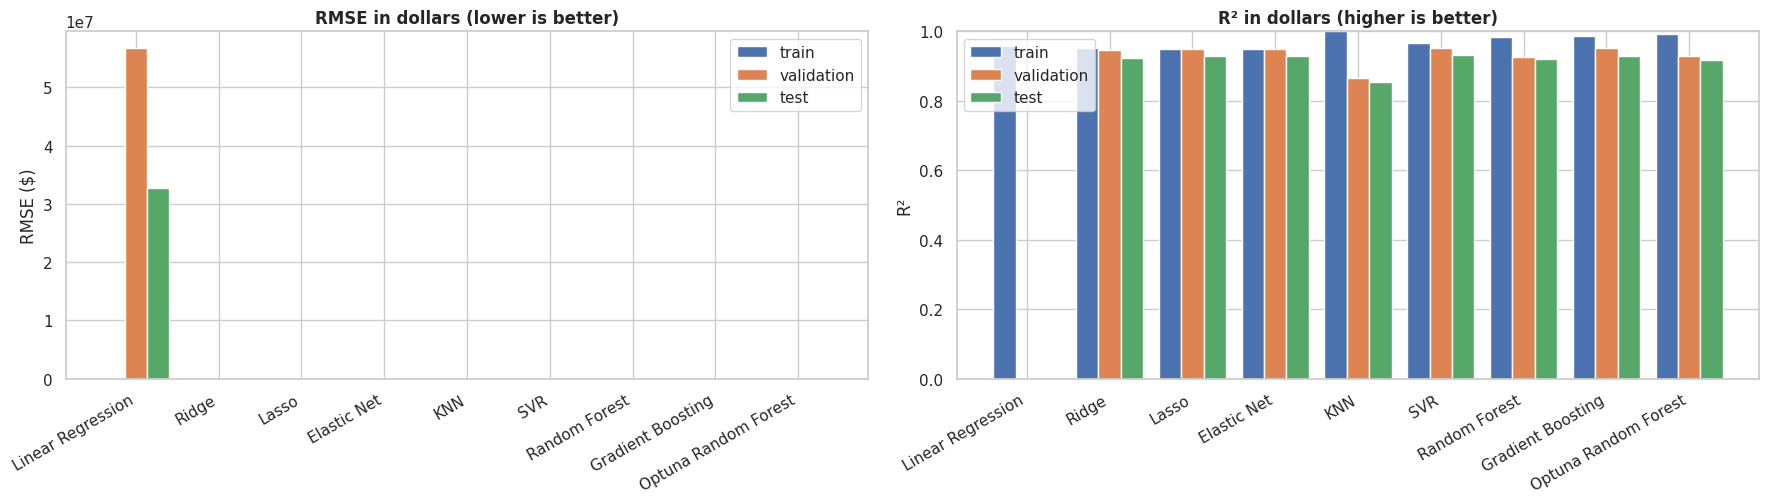

In [54]:
# ---- 8.2 Train / validation / test comparison ----
fig, ax = plt.subplots(1, 2, figsize=(18, 5.2))
w = 0.27; x = np.arange(len(ORDER))
for k, s in enumerate(["train", "validation", "test"]):
    t = metric_table(s)
    ax[0].bar(x + (k - 1) * w, t["RMSE ($)"], w, label=s, color=SET_COLORS[s])
    ax[1].bar(x + (k - 1) * w, t["R²"], w, label=s, color=SET_COLORS[s])
ax[0].set(title="RMSE in dollars (lower is better)", ylabel="RMSE ($)")
ax[1].set(title="R² in dollars (higher is better)", ylabel="R²", ylim=(max(0, metric_table("validation")["R²"].min() - 0.05), 1.0))
for a in ax:
    a.set_xticks(x); a.set_xticklabels(ORDER, rotation=30, ha="right"); a.legend()
plt.tight_layout(); plt.show()

### 8.3 Overfitting, underfitting and tuning

I compare training and validation errors to understand how each model behaves.

- **Overfitting:** the training error is much lower than the validation error.
- **Underfitting:** the model has high error even on the training data.
- **Effect of tuning:** I compare the validation error before and after tuning to see whether the search helped.


,train RMSE (log),validation RMSE (log),gap (val − train),val / train,diagnosis (tuned),default val RMSE,default val / train,diagnosis (default),tuning gain (%)
model,,,,,,,,,
Linear Regression,0.0879,"1,045,721.3590","1,045,721.2712","11,900,378.1068",Overfitting (strong),"1,045,721.3590","11,900,378.1068",Overfitting (strong),0.0000
Ridge,0.0945,0.1014,0.0069,1.0726,Good fit,0.1099,1.2264,Good fit,7.7509
Lasso,0.0981,0.0995,0.0014,1.0140,Good fit,0.3871,0.9478,Underfitting (high bias),74.2978
Elastic Net,0.0981,0.0995,0.0014,1.0140,Good fit,0.3871,0.9478,Underfitting (high bias),74.2978
KNN,0.0000,0.1656,0.1656,16.5590,Overfitting (strong),0.1580,1.1893,Good fit,-4.7755
SVR,0.0843,0.1015,0.0172,1.2045,Good fit,0.1044,1.1398,Good fit,2.7659
Random Forest,0.0497,0.1251,0.0755,2.5193,Overfitting (strong),0.1299,2.5034,Overfitting (strong),3.6868
Gradient Boosting,0.0535,0.1033,0.0499,1.9325,Overfitting (strong),0.1141,1.5351,Mild overfitting,9.4520
Optuna Random Forest,0.0354,0.1256,0.0902,3.5486,Overfitting (strong),0.1299,2.5034,Overfitting (strong),3.3039


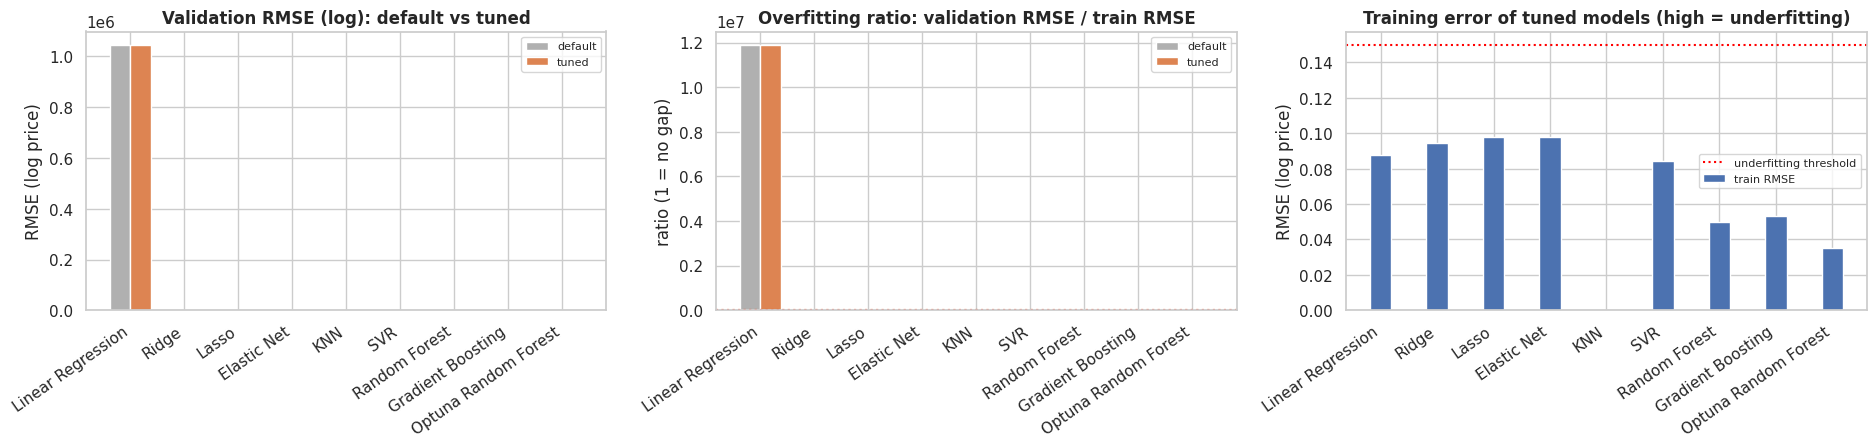

In [55]:
# ---- 8.3 Over/underfitting diagnosis and tuning effect ----
def safe(x):                      # a perfect training fit (KNN with distance weights) would divide by zero
    return max(x, 1e-2)

def diagnose(train_rmse, val_rmse):
    ratio = val_rmse / safe(train_rmse)
    if train_rmse > 0.15:   return "Underfitting (high bias)"
    if ratio > 1.6:         return "Overfitting (strong)"
    if ratio > 1.25:        return "Mild overfitting"
    return "Good fit"

rows = []
for m in ORDER:
    t, d_ = RESULTS[(m, "tuned")], RESULTS[(m, "default")] if (m, "default") in RESULTS else RESULTS[(m, "tuned")]
    rows.append({"model": m,
                 "train RMSE (log)": t["train"]["RMSE (log)"], "validation RMSE (log)": t["validation"]["RMSE (log)"],
                 "gap (val − train)": t["validation"]["RMSE (log)"] - t["train"]["RMSE (log)"],
                 "val / train": t["validation"]["RMSE (log)"] / safe(t["train"]["RMSE (log)"]),
                 "diagnosis (tuned)": diagnose(t["train"]["RMSE (log)"], t["validation"]["RMSE (log)"]),
                 "default val RMSE": d_["validation"]["RMSE (log)"],
                 "default val / train": d_["validation"]["RMSE (log)"] / safe(d_["train"]["RMSE (log)"]),
                 "diagnosis (default)": diagnose(d_["train"]["RMSE (log)"], d_["validation"]["RMSE (log)"]),
                 "tuning gain (%)": 100 * (d_["validation"]["RMSE (log)"] - t["validation"]["RMSE (log)"]) / d_["validation"]["RMSE (log)"]})
FIT_DIAG = pd.DataFrame(rows).set_index("model")
display(FIT_DIAG.round(4))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
x = np.arange(len(ORDER)); w = 0.38
ax[0].bar(x - w / 2, FIT_DIAG["default val RMSE"], w, color="#b0b0b0", label="default")
ax[0].bar(x + w / 2, FIT_DIAG["validation RMSE (log)"], w, color=SET_COLORS["validation"], label="tuned")
ax[0].set(title="Validation RMSE (log): default vs tuned", ylabel="RMSE (log price)")
ax[1].bar(x - w / 2, FIT_DIAG["default val / train"], w, color="#b0b0b0", label="default")
ax[1].bar(x + w / 2, FIT_DIAG["val / train"], w, color=SET_COLORS["validation"], label="tuned")
ax[1].axhline(1.25, color="orange", ls=":"); ax[1].axhline(1.6, color="red", ls=":")
ax[1].set(title="Overfitting ratio: validation RMSE / train RMSE", ylabel="ratio (1 = no gap)")
ax[2].bar(ORDER, FIT_DIAG["train RMSE (log)"], .38, color=SET_COLORS["train"], label="train RMSE")
ax[2].axhline(0.15, color="red", ls=":", label="underfitting threshold")
ax[2].set(title="Training error of tuned models (high = underfitting)", ylabel="RMSE (log price)")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(ORDER, rotation=35, ha="right"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.4 Predicted prices versus actual prices

I compare the predicted and actual prices on the validation set. Points closer to the diagonal line indicate more accurate predictions. I also check the residuals to look for patterns in the errors.


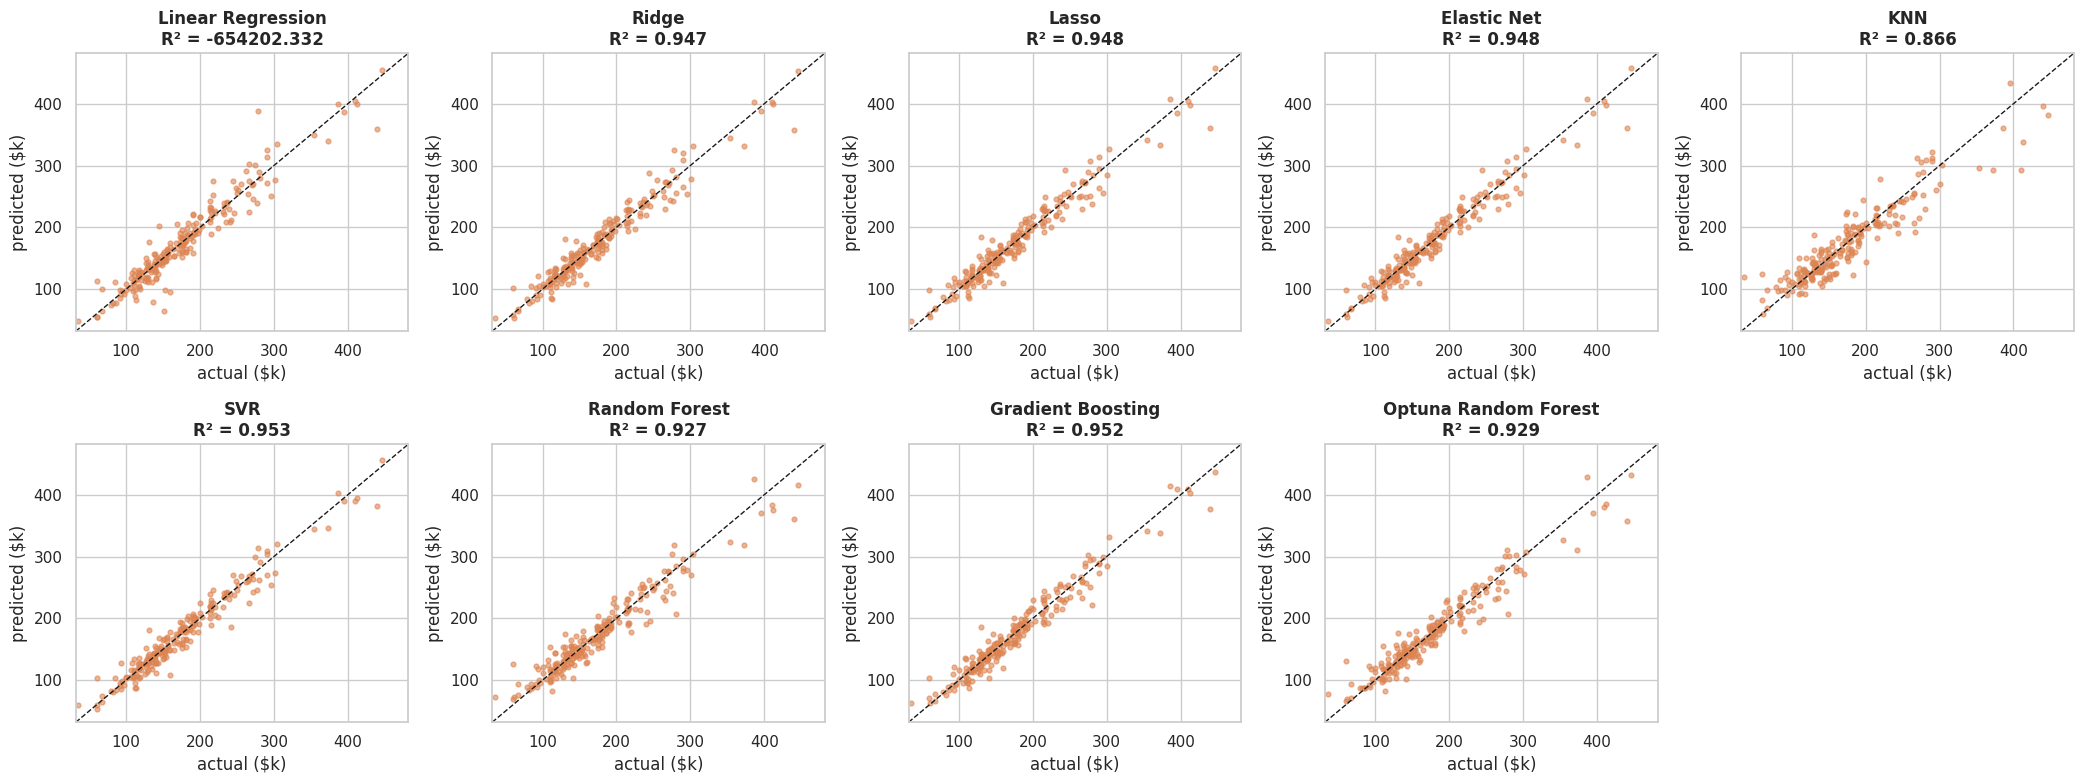

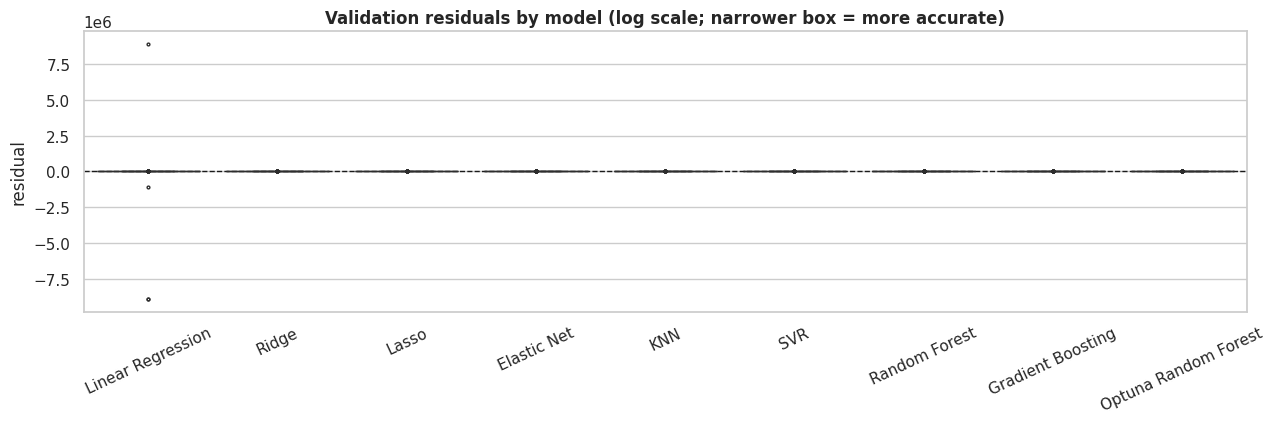

In [56]:
# ---- 8.4 Predicted vs actual for all models + residual box-plots ----
ncols = 5; nrows = int(np.ceil(len(ORDER) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.0 * nrows), squeeze=False)
lim = [y_raw_val.min() / 1e3 * .9, y_raw_val.max() / 1e3 * 1.08]
for ax, m in zip(axes.ravel(), ORDER):
    p = to_usd(BEST[m].predict(X_val)) / 1e3
    ax.scatter(y_raw_val / 1e3, p, s=12, alpha=.6, color=SET_COLORS["validation"]); ax.plot(lim, lim, "k--", lw=1)
    ax.set(xlim=lim, ylim=lim, title=f"{m}\nR² = {RESULTS[(m, 'tuned')]['validation']['R²']:.3f}", xlabel="actual ($k)", ylabel="predicted ($k)")
for ax in axes.ravel()[len(ORDER):]: ax.axis("off")
plt.tight_layout(); plt.show()

resid_tbl = pd.DataFrame({m: np.asarray(y_val) - BEST[m].predict(X_val) for m in ORDER})
fig, ax = plt.subplots(figsize=(13, 4.4))
sns.boxplot(data=resid_tbl, ax=ax, palette="viridis", fliersize=2); ax.axhline(0, color="k", ls="--", lw=1)
ax.set(title="Validation residuals by model (log scale; narrower box = more accurate)", ylabel="residual"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

### 8.5 Learning curves for the best models

Learning curves show how training and cross-validation errors change as more training examples are used. They help me check whether the models may benefit from more data or need different complexity settings.


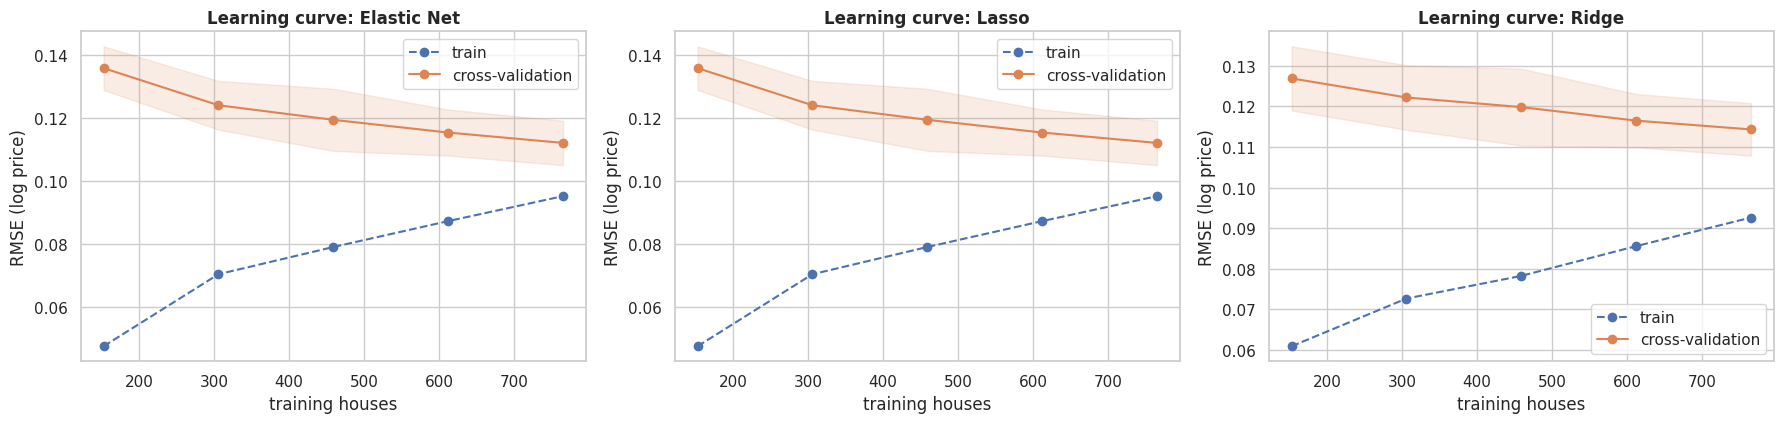

In [57]:
# ---- 8.5 Learning curves (top-3 models by validation RMSE) ----
top3 = FIT_DIAG.sort_values("validation RMSE (log)").index[:3].tolist()
fig, axes = plt.subplots(1, len(top3), figsize=(6 * len(top3), 4.4), squeeze=False)
for ax, m in zip(axes.ravel(), top3):
    sizes, tr_s, cv_s = learning_curve(clone(BEST[m]), X_train, y_train, cv=KFold(4, shuffle=True, random_state=RANDOM_STATE),
                                       train_sizes=np.linspace(0.2, 1.0, 5), scoring=SCORING,
                                       n_jobs=-1)  # Parallelize CPU cross-validation jobs.
    ax.plot(sizes, -tr_s.mean(1), "o--", color=SET_COLORS["train"], label="train")
    ax.plot(sizes, -cv_s.mean(1), "o-", color=SET_COLORS["validation"], label="cross-validation")
    ax.fill_between(sizes, -cv_s.mean(1) - cv_s.std(1), -cv_s.mean(1) + cv_s.std(1), color=SET_COLORS["validation"], alpha=.15)
    ax.set(title=f"Learning curve: {m}", xlabel="training houses", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()

### 8.6 Errors across price ranges

The overall score may hide differences between cheaper and more expensive houses. I divide the validation houses into five price groups and compare the mean absolute percentage error for each group.


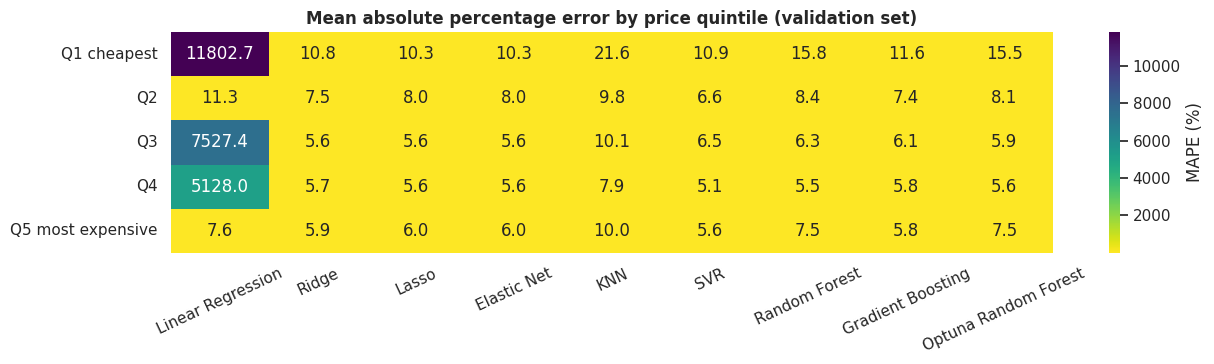

In [58]:
# ---- 8.6 Error by price segment (validation) ----
seg = pd.qcut(y_raw_val, 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 most expensive"])
mape = pd.DataFrame({m: (np.abs(to_usd(BEST[m].predict(X_val)) - y_raw_val) / y_raw_val).groupby(seg, observed=True).mean() * 100 for m in ORDER})
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(mape, annot=True, fmt=".1f", cmap="viridis_r", cbar_kws={"label": "MAPE (%)"}, ax=ax)
ax.set(title="Mean absolute percentage error by price quintile (validation set)", ylabel="")
ax.tick_params(axis="x", rotation=25); plt.tight_layout(); plt.show()

### 8.7 Evaluation questions

The next cell uses the results calculated above to summarize the main evaluation findings.


In [59]:
# ---- 8.7 Automatic discussion ----
val_rmse = FIT_DIAG["validation RMSE (log)"]; best_m = val_rmse.idxmin()
v = lambda m, k, s="validation": RESULTS[(m, "tuned")][s][k]
over = FIT_DIAG.index[FIT_DIAG["diagnosis (tuned)"].str.startswith(("Overfitting", "Mild"))].tolist()
over_def = FIT_DIAG.index[FIT_DIAG["diagnosis (default)"].str.startswith(("Overfitting", "Mild"))].tolist()
under = FIT_DIAG.index[FIT_DIAG["diagnosis (tuned)"].str.startswith("Underfitting")].tolist()
under_def = FIT_DIAG.index[FIT_DIAG["diagnosis (default)"].str.startswith("Underfitting")].tolist()
gain = FIT_DIAG["tuning gain (%)"].drop(index="Linear Regression", errors="ignore")
test_gap = pd.Series({m: v(m, "RMSE (log)", "test") - v(m, "RMSE (log)") for m in ORDER})
display(Markdown(f"""
**Which model performs best?** On the validation set **{best_m}** has the lowest error (RMSE ${v(best_m, 'RMSE ($)'):,.0f}, MAE ${v(best_m, 'MAE ($)'):,.0f}, R² {v(best_m, 'R²'):.3f}; log-RMSE {v(best_m, 'RMSE (log)'):.4f}). \
The ranking by validation log-RMSE is: {', '.join(f'{m} ({val_rmse[m]:.4f})' for m in val_rmse.sort_values().index)}.

**Evidence of overfitting.** After tuning, models still showing a train–validation gap: {', '.join(f'{m} ({FIT_DIAG.loc[m, "val / train"]:.2f}x)' for m in over) or 'none'}. \
Before tuning the flagged models were: {', '.join(over_def) or 'none'}. The widest remaining gap is **{FIT_DIAG['val / train'].idxmax()}** ({FIT_DIAG['val / train'].max():.2f}x); \
the narrowest is **{FIT_DIAG['val / train'].idxmin()}** ({FIT_DIAG['val / train'].min():.2f}x).

**Evidence of underfitting.** Tuned models flagged as underfitting: {', '.join(under) or 'none'}. Default models flagged: {', '.join(under_def) or 'none'} \
(for the penalized linear models this is the effect of the default `alpha=1`).

**Training vs validation.** Average train RMSE (log) of the tuned models is {FIT_DIAG['train RMSE (log)'].mean():.4f} against {val_rmse.mean():.4f} on validation. \
Tree ensembles typically reach the smallest training error; regularized and kernel models keep the two closest.

**Did tuning help?** Mean validation-RMSE improvement over the tuned models (excluding Linear Regression, which has nothing to tune): **{gain.mean():.1f}%**; \
largest gain **{gain.idxmax()} ({gain.max():.1f}%)**, smallest **{gain.idxmin()} ({gain.min():.1f}%)**. \
{'All models improved.' if (gain >= 0).all() else 'Models that did not improve: ' + ', '.join(gain.index[gain < 0]) + '.'}

**Which model generalizes best to unseen data?** The smallest change from validation to the untouched test set is **{test_gap.abs().idxmin()}** \
({test_gap[test_gap.abs().idxmin()]:+.4f} log-RMSE) and the lowest test error is **{pd.Series({m: v(m, 'RMSE (log)', 'test') for m in ORDER}).idxmin()}**. \
The test set has only {len(X_test)} houses, so differences of a few percent between the top models are within sampling noise (see the bootstrap interval in Section 10).
"""))


**Which model performs best?** On the validation set **Lasso** has the lowest error (RMSE $15,976, MAE $11,551, R² 0.948; log-RMSE 0.0995). The ranking by validation log-RMSE is: Elastic Net (0.0995), Lasso (0.0995), Ridge (0.1014), SVR (0.1015), Gradient Boosting (0.1033), Random Forest (0.1251), Optuna Random Forest (0.1256), KNN (0.1656), Linear Regression (1045721.3590).

**Evidence of overfitting.** After tuning, models still showing a train–validation gap: Linear Regression (11900378.11x), KNN (16.56x), Random Forest (2.52x), Gradient Boosting (1.93x), Optuna Random Forest (3.55x). Before tuning the flagged models were: Linear Regression, Random Forest, Gradient Boosting, Optuna Random Forest. The widest remaining gap is **Linear Regression** (11900378.11x); the narrowest is **Lasso** (1.01x).

**Evidence of underfitting.** Tuned models flagged as underfitting: none. Default models flagged: Lasso, Elastic Net (for the penalized linear models this is the effect of the default `alpha=1`).

**Training vs validation.** Average train RMSE (log) of the tuned models is 0.0668 against 116191.3645 on validation. Tree ensembles typically reach the smallest training error; regularized and kernel models keep the two closest.

**Did tuning help?** Mean validation-RMSE improvement over the tuned models (excluding Linear Regression, which has nothing to tune): **21.3%**; largest gain **Lasso (74.3%)**, smallest **KNN (-4.8%)**. Models that did not improve: KNN.

**Which model generalizes best to unseen data?** The smallest change from validation to the untouched test set is **Random Forest** (-0.0029 log-RMSE) and the lowest test error is **SVR**. The test set has only 219 houses, so differences of a few percent between the top models are within sampling noise (see the bootstrap interval in Section 10).


### 8.8 Model selection rule

I do not select a model using the test set. I first find the lowest validation RMSE, then keep models whose validation RMSE is within 2% of that value. If several models are close, I prefer the simpler model; if their complexity is the same, I choose the one with the lower validation error.


In [60]:
# ---- 8.8 Selection rule ----
def choose_final(tol=0.02):
    val = {m: RESULTS[(m, "tuned")]["validation"]["RMSE (log)"] for m in BEST}
    best = min(val.values())
    candidates = [m for m, e in val.items() if e <= best * (1 + tol)]
    return min(candidates, key=lambda m: (COMPLEXITY[m], val[m])), sorted(candidates, key=val.get), val

FINAL_NAME, FINAL_CANDIDATES, VAL_RMSE = choose_final()
FINAL_MODEL = BEST[FINAL_NAME]
print(f"Candidates within 2% of the best validation RMSE: {FINAL_CANDIDATES}")
print(f"Selected model: {FINAL_NAME}")

Candidates within 2% of the best validation RMSE: ['Lasso', 'Elastic Net', 'Ridge']
Selected model: Lasso


---
# Section 9 — Final Model Selection

In this section, I use the validation results and the selection rule from Section 8 to choose the final model. I then evaluate that model on the test set, which has not been used for tuning or model selection.


In [61]:
# ---- 9.1 Decision table (everything except the test set) ----
dec = pd.DataFrame({
    "val RMSE (log)":   {m: RESULTS[(m, "tuned")]["validation"]["RMSE (log)"] for m in ORDER},
    "val RMSE ($)":     {m: RESULTS[(m, "tuned")]["validation"]["RMSE ($)"] for m in ORDER},
    "val R²":           {m: RESULTS[(m, "tuned")]["validation"]["R²"] for m in ORDER},
    "CV RMSE (log)":    {m: (-SEARCH[m].best_score_ if m in SEARCH else (optuna_study.best_value if m == "Optuna Random Forest" else np.nan)) for m in ORDER},
    "val / train":      FIT_DIAG["val / train"],
    "diagnosis":        FIT_DIAG["diagnosis (tuned)"],
    "complexity rank":  {m: COMPLEXITY[m] for m in ORDER},
    "fit time (s)":     {m: FIT_SECONDS[m] for m in ORDER},
}).sort_values("val RMSE (log)")
dec["within 2% of best"] = np.where(dec["val RMSE (log)"] <= dec["val RMSE (log)"].min() * 1.02, "yes", "")
dec["SELECTED"] = np.where(dec.index == FINAL_NAME, "◀", "")
display(dec.assign(**{"val RMSE ($)": dec["val RMSE ($)"].map("{:,.0f}".format), "fit time (s)": dec["fit time (s)"].map("{:,.1f}".format)}))

,val RMSE (log),val RMSE ($),val R²,CV RMSE (log),val / train,diagnosis,complexity rank,fit time (s),within 2% of best,SELECTED
Elastic Net,0.0995,"15,976",0.9482,0.1113,1.0140,Good fit,3,91.3,yes,
Lasso,0.0995,"15,976",0.9482,0.1113,1.0140,Good fit,2,27.7,yes,◀
Ridge,0.1014,"16,087",0.9475,0.1136,1.0726,Good fit,2,22.5,yes,
SVR,0.1015,"15,229",0.9529,0.1102,1.2045,Good fit,4,835.5,,
Gradient Boosting,0.1033,"15,374",0.9520,0.1184,1.9325,Overfitting (strong),5,165.8,,
Random Forest,0.1251,"18,962",0.9270,0.1349,2.5193,Overfitting (strong),5,183.5,,
Optuna Random Forest,0.1256,"18,655",0.9294,0.1336,3.5486,Overfitting (strong),5,314.7,,
KNN,0.1656,"25,735",0.8655,0.1614,16.5590,Overfitting (strong),3,39.6,,
Linear Regression,"1,045,721.3590","56,766,400","-654,202.3323",NaN,"11,900,378.1068",Overfitting (strong),1,0.1,,


### Final model: **Lasso**

,MAE ($),MSE ($²),RMSE ($),R²,RMSE (log),R² (log)
train,"12,667","364,868,666","19,102",0.9487,0.0981,0.9423
validation,"11,551","255,217,606","15,976",0.9482,0.0995,0.9336
test,"12,540","280,747,724","16,756",0.9278,0.1133,0.9057


**Test RMSE $16,756** (95% bootstrap interval $14,772 – $18,712) · **MAE $12,540** · **R² 0.928** (95% interval 0.906 – 0.945). **75%** of the test houses are predicted within 10% of the real price and **93%** within 20%.

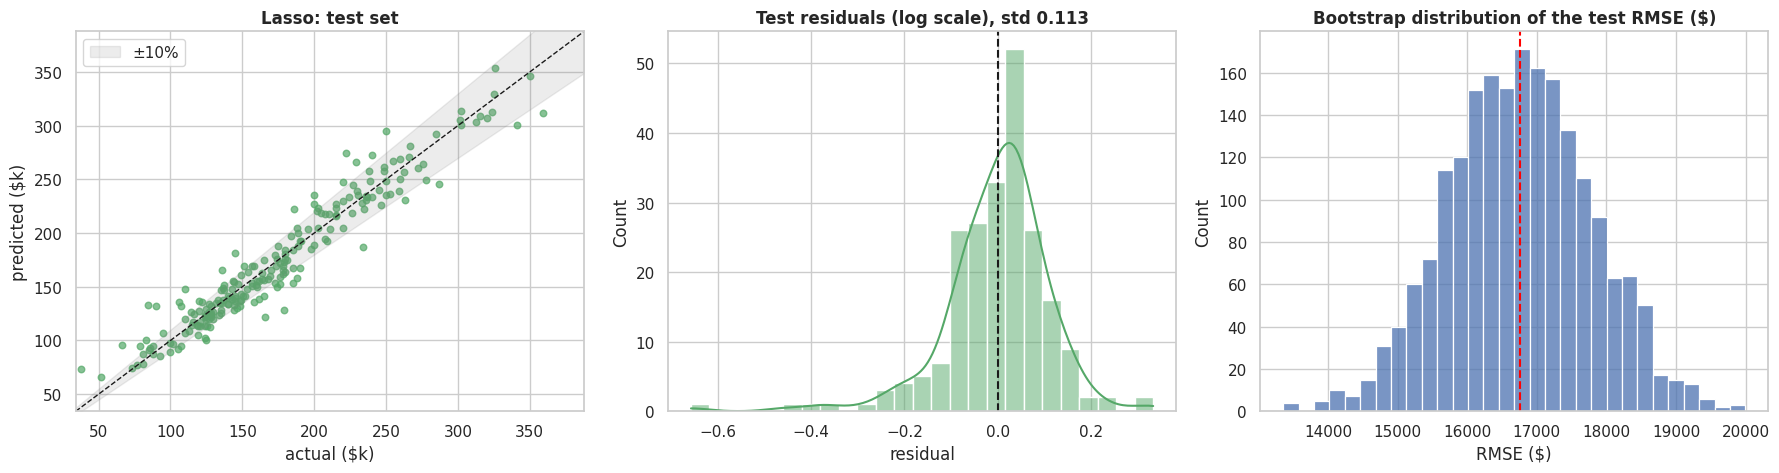

In [62]:
# ---- 9.2 Final evaluation on the untouched test set + uncertainty ----
final_res = RESULTS[(FINAL_NAME, "tuned")]
display(Markdown(f"### Final model: **{FINAL_NAME}**"))
display(pretty(pd.DataFrame(final_res).T[METRICS]))

# bootstrap confidence interval of the test RMSE ($) and R²
rng = np.random.default_rng(RANDOM_STATE)
pred_test = to_usd(FINAL_MODEL.predict(X_test)); true_test = np.asarray(y_raw_test)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(true_test), len(true_test))
    boot.append((np.sqrt(np.mean((true_test[i] - pred_test[i]) ** 2)), r2_score(true_test[i], pred_test[i])))
boot = np.array(boot)
rmse_ci, r2_ci = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])
pct_err = np.abs(pred_test - true_test) / true_test
display(Markdown(f"**Test RMSE ${final_res['test']['RMSE ($)']:,.0f}** (95% bootstrap interval ${rmse_ci[0]:,.0f} – ${rmse_ci[1]:,.0f}) · "
                 f"**MAE ${final_res['test']['MAE ($)']:,.0f}** · **R² {final_res['test']['R²']:.3f}** (95% interval {r2_ci[0]:.3f} – {r2_ci[1]:.3f}). "
                 f"**{(pct_err <= 0.10).mean():.0%}** of the test houses are predicted within 10% of the real price and **{(pct_err <= 0.20).mean():.0%}** within 20%."))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.9))
lim = [true_test.min() / 1e3 * .9, true_test.max() / 1e3 * 1.08]
ax[0].scatter(true_test / 1e3, pred_test / 1e3, s=22, alpha=.7, color=SET_COLORS["test"]); ax[0].plot(lim, lim, "k--", lw=1)
ax[0].fill_between(lim, [l * .9 for l in lim], [l * 1.1 for l in lim], color="grey", alpha=.15, label="±10%")
ax[0].set(xlim=lim, ylim=lim, xlabel="actual ($k)", ylabel="predicted ($k)", title=f"{FINAL_NAME}: test set"); ax[0].legend()
res_t = np.asarray(y_test) - FINAL_MODEL.predict(X_test)
sns.histplot(res_t, kde=True, bins=25, color=SET_COLORS["test"], ax=ax[1]); ax[1].axvline(0, color="k", ls="--")
ax[1].set(title=f"Test residuals (log scale), std {res_t.std():.3f}", xlabel="residual")
sns.histplot(boot[:, 0], bins=30, color="#4c72b0", ax=ax[2]); ax[2].axvline(final_res["test"]["RMSE ($)"], color="red", ls="--")
ax[2].set(title="Bootstrap distribution of the test RMSE ($)", xlabel="RMSE ($)")
plt.tight_layout(); plt.show()

In [63]:
# ---- 9.3 Justification (generated from the numbers) ----
others_ranked = [m for m in dec.index if m != FINAL_NAME][:3]
def vs(m):
    a, b = RESULTS[(m, "tuned")], final_res
    return (f"- **{m}**: validation RMSE {a['validation']['RMSE (log)']:.4f} vs {b['validation']['RMSE (log)']:.4f} "
            f"({100 * (a['validation']['RMSE (log)'] / b['validation']['RMSE (log)'] - 1):+.1f}%), test RMSE ${a['test']['RMSE ($)']:,.0f} vs ${b['test']['RMSE ($)']:,.0f}, "
            f"train/val ratio {FIT_DIAG.loc[m, 'val / train']:.2f} vs {FIT_DIAG.loc[FINAL_NAME, 'val / train']:.2f}, complexity rank {COMPLEXITY[m]} vs {COMPLEXITY[FINAL_NAME]}.")
best_val_m = dec.index[0]
display(Markdown(f"""
### Why **{FINAL_NAME}**?
* **Accuracy:** validation RMSE (log) {final_res['validation']['RMSE (log)']:.4f}, i.e. typical errors of about \
${final_res['validation']['MAE ($)']:,.0f} (MAE) and R² {final_res['validation']['R²']:.3f}; on the test set RMSE ${final_res['test']['RMSE ($)']:,.0f}, R² {final_res['test']['R²']:.3f}.
* **Generalization:** train/validation RMSE ratio of {FIT_DIAG.loc[FINAL_NAME, 'val / train']:.2f} ({FIT_DIAG.loc[FINAL_NAME, 'diagnosis (tuned)']}); \
validation → test change of {final_res['test']['RMSE (log)'] - final_res['validation']['RMSE (log)']:+.4f} log-RMSE.
* **Tuning:** hyper-parameters were chosen by 5-fold cross-validation inside the training set; tuning changed validation RMSE by {FIT_DIAG.loc[FINAL_NAME, 'tuning gain (%)']:+.1f}% relative to the defaults.
* **Complexity:** predefined complexity score {COMPLEXITY[FINAL_NAME]}. {'It is the lowest-error model on validation.' if FINAL_NAME == best_val_m else f'The lowest validation error is **{best_val_m}** ({dec.loc[best_val_m, "val RMSE (log)"]:.4f}), but it is within 2% of {FINAL_NAME}, which is simpler, so the extra complexity is not justified.'}
* **Appropriate metric:** log-scale RMSE is the training objective and measures *relative* error, so cheap and expensive houses count equally; dollar MAE/RMSE are reported for interpretability.

**Compared with the closest alternatives**
{chr(10).join(vs(m) for m in others_ranked)}

**Limitations.** The test set has only {len(X_test)} houses (see the bootstrap interval); errors are largest for the most expensive houses (Section 8.6); \
the model was trained on one city (Ames, Iowa) and one time period, so it should not be applied to other markets without re-validation.
"""))

joblib.dump(FINAL_MODEL, "final_model.joblib")
print("Saved: final_model.joblib  (load with joblib.load and call .predict on a DataFrame with the same 83 columns)")


### Why **Lasso**?
* **Accuracy:** validation RMSE (log) 0.0995, i.e. typical errors of about $11,551 (MAE) and R² 0.948; on the test set RMSE $16,756, R² 0.928.
* **Generalization:** train/validation RMSE ratio of 1.01 (Good fit); validation → test change of +0.0138 log-RMSE.
* **Tuning:** hyper-parameters were chosen by 5-fold cross-validation inside the training set; tuning changed validation RMSE by +74.3% relative to the defaults.
* **Complexity:** predefined complexity score 2. The lowest validation error is **Elastic Net** (0.0995), but it is within 2% of Lasso, which is simpler, so the extra complexity is not justified.
* **Appropriate metric:** log-scale RMSE is the training objective and measures *relative* error, so cheap and expensive houses count equally; dollar MAE/RMSE are reported for interpretability.

**Compared with the closest alternatives**
- **Elastic Net**: validation RMSE 0.0995 vs 0.0995 (+0.0%), test RMSE $16,756 vs $16,756, train/val ratio 1.01 vs 1.01, complexity rank 3 vs 2.
- **Ridge**: validation RMSE 0.1014 vs 0.0995 (+1.9%), test RMSE $17,265 vs $16,756, train/val ratio 1.07 vs 1.01, complexity rank 2 vs 2.
- **SVR**: validation RMSE 0.1015 vs 0.0995 (+2.0%), test RMSE $16,117 vs $16,756, train/val ratio 1.20 vs 1.01, complexity rank 4 vs 2.

**Limitations.** The test set has only 219 houses (see the bootstrap interval); errors are largest for the most expensive houses (Section 8.6); the model was trained on one city (Ames, Iowa) and one time period, so it should not be applied to other markets without re-validation.


Saved: final_model.joblib  (load with joblib.load and call .predict on a DataFrame with the same 83 columns)


In [65]:
!pip freeze > requirements.txt